In [1]:
# PROJETO FIAP - TECH CHALLENGE
# Análise de vendas do marketplace Olist
# Objetivo: avaliar crescimento, previsibilidade, riscos e oportunidades
# Importando as bibliotecas

# Manipulação de dados
import pandas as pd
import numpy as np

# Visualização de dados
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Configurações para facilitar a leitura
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [2]:
# Importando os arquivos

from google.colab import files

# Selecionar o arquivo zip do computador
arquivos = files.upload()

Saving archive.zip to archive.zip


In [3]:
# extraindo os arquivos

# Biblioteca para trabalhar com arquivos compactados
import zipfile
import io

# Abrir o arquivo ZIP
nome_arquivo_zip = "archive.zip"

with zipfile.ZipFile(io.BytesIO(arquivos[nome_arquivo_zip]), "r") as zip_ref:

    # Extrair os arquivos para a pasta de trabalho do Colab
    zip_ref.extractall("/content/olist")

    # Listar os arquivos existentes dentro do ZIP
    arquivos_zip = zip_ref.namelist()

print("Arquivos encontrados dentro do ZIP:")
for arquivo in arquivos_zip:
    print(arquivo)


Arquivos encontrados dentro do ZIP:
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [4]:
# descobrir quantas tabelas temos e seus nomes - Cada arquivo representa uma parte do negócio. Precisamos entender essas partes antes de juntá-las.

# Selecionar somente os arquivos CSV
arquivos_csv = [
    arquivo
    for arquivo in arquivos_zip
    if arquivo.lower().endswith(".csv")
]

print(f"Quantidade de arquivos CSV: {len(arquivos_csv)}")

print("\nLista de tabelas:")
for arquivo in arquivos_csv:
    print("-", arquivo)


Quantidade de arquivos CSV: 9

Lista de tabelas:
- olist_customers_dataset.csv
- olist_geolocation_dataset.csv
- olist_order_items_dataset.csv
- olist_order_payments_dataset.csv
- olist_order_reviews_dataset.csv
- olist_orders_dataset.csv
- olist_products_dataset.csv
- olist_sellers_dataset.csv
- product_category_name_translation.csv


In [5]:

# vamos importar cada CSV como um DataFrame, verificando a quantidade de linhas e variáveis em cada uma

from pathlib import Path

# Dicionário para armazenar as tabelas
tabelas = {}

for arquivo in arquivos_csv:

    # Caminho completo do arquivo
    caminho = Path("/content/olist") / arquivo

    # Nome da tabela sem o sufixo .csv
    nome_tabela = Path(arquivo).stem

    # Ler o CSV e armazenar no dicionário
    tabelas[nome_tabela] = pd.read_csv(caminho)

print("Arquivos carregados com sucesso!\n")

# Mostrar as dimensões de cada tabela
for nome, df in tabelas.items():
    print(f"{nome}: {df.shape[0]:,} linhas | {df.shape[1]} colunas")


Arquivos carregados com sucesso!

olist_customers_dataset: 99,441 linhas | 5 colunas
olist_geolocation_dataset: 1,000,163 linhas | 5 colunas
olist_order_items_dataset: 112,650 linhas | 7 colunas
olist_order_payments_dataset: 103,886 linhas | 5 colunas
olist_order_reviews_dataset: 99,224 linhas | 7 colunas
olist_orders_dataset: 99,441 linhas | 8 colunas
olist_products_dataset: 32,951 linhas | 9 colunas
olist_sellers_dataset: 3,095 linhas | 4 colunas
product_category_name_translation: 71 linhas | 2 colunas


In [6]:

# vamos entender cada tabela

# começando pela tabela de pedidos

orders = tabelas["olist_orders_dataset"]

display(orders.head())

print("Dimensões:", orders.shape)

print("\nColunas disponíveis:")
print(orders.columns.tolist())

print("\nInformações gerais:")
orders.info()

print("\nValores ausentes:")
print(orders.isnull().sum())

print("\nLinhas duplicadas:", orders.duplicated().sum())


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


Dimensões: (99441, 8)

Colunas disponíveis:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Valor

In [7]:
# vamos precisar ajustar a data, pois vamos precisar acompanhar vendas por mês
# vamos investigar as ausências em pedidos aprovados, pedidos encaminhados e pedidos entregues


# 1. Verificar os status dos pedidos
print("Quantidade de pedidos por status:")
display(orders["order_status"].value_counts(dropna=False))

# 2. Verificar a proporção de valores ausentes
print("\nPercentual de valores ausentes por coluna:")
percentual_ausentes = (
    orders.isnull().mean().mul(100).sort_values(ascending=False)
)
display(percentual_ausentes.round(2))

# 3. Converter as colunas de data para datetime
colunas_data = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for coluna in colunas_data:
    orders[coluna] = pd.to_datetime(
        orders[coluna],
        errors="coerce"
    )

# 4. Conferir os tipos após a conversão
print("\nTipos de dados após a conversão:")
print(orders.dtypes)

# 5. Conferir novamente os valores ausentes
print("\nValores ausentes após a conversão:")
print(orders[colunas_data].isnull().sum())


Quantidade de pedidos por status:


,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2



Percentual de valores ausentes por coluna:


,0
order_delivered_customer_date,2.98
order_delivered_carrier_date,1.79
order_approved_at,0.16
order_id,0.00
order_purchase_timestamp,0.00
order_status,0.00
customer_id,0.00
order_estimated_delivery_date,0.00



Tipos de dados após a conversão:
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Valores ausentes após a conversão:
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [8]:

# vamos mapear o período da base

# Identificar a primeira e a última data de compra
data_inicial = orders["order_purchase_timestamp"].min()
data_final = orders["order_purchase_timestamp"].max()

print("Primeira compra:", data_inicial)
print("Última compra:", data_final)

# Quantidade de dias cobertos pelos dados
periodo_dias = (data_final - data_inicial).days

print("Período coberto em dias:", periodo_dias)

# Verificar a quantidade de pedidos por ano
print("\nQuantidade de pedidos por ano:")
display(
    orders["order_purchase_timestamp"]
    .dt.year
    .value_counts()
    .sort_index()
)


Primeira compra: 2016-09-04 21:15:19
Última compra: 2018-10-17 17:30:18
Período coberto em dias: 772

Quantidade de pedidos por ano:


,count
order_purchase_timestamp,
2016,329
2017,45101
2018,54011


Primeiros meses:


,mes,quantidade_pedidos
0,2016-09-01,4
1,2016-10-01,324
2,2016-12-01,1
3,2017-01-01,800
4,2017-02-01,1780
5,2017-03-01,2682


Últimos meses:


,mes,quantidade_pedidos
19,2018-05-01,6873
20,2018-06-01,6167
21,2018-07-01,6292
22,2018-08-01,6512
23,2018-09-01,16
24,2018-10-01,4


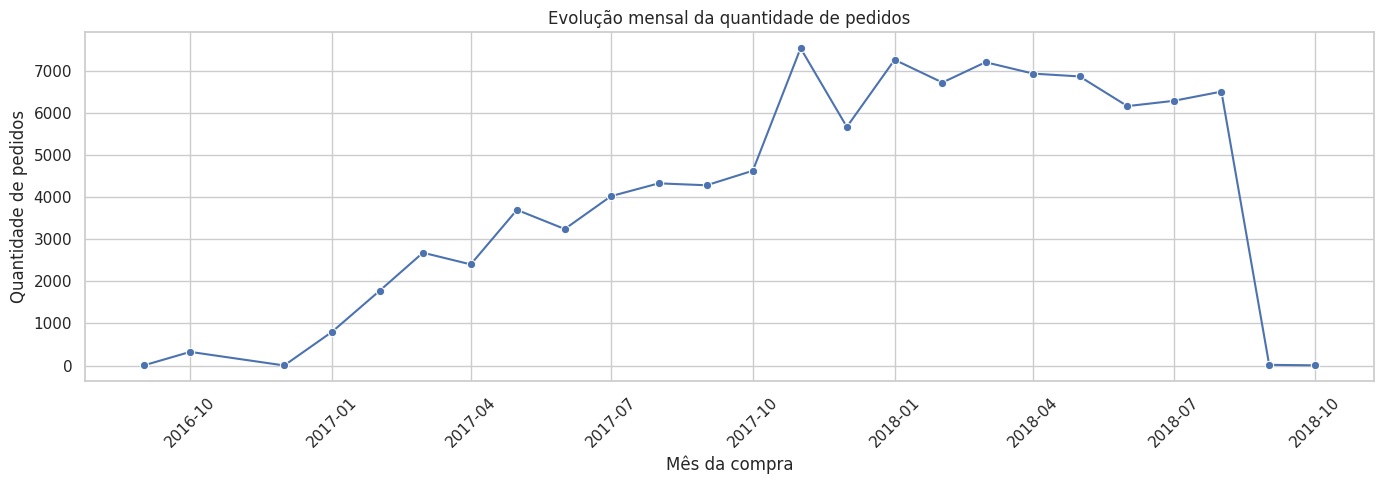

In [9]:

# vamos mapear a evolução mensal dos pedidos

# Criar uma cópia com as informações necessárias
pedidos = orders[
    ["order_id", "order_purchase_timestamp"]
].copy()

# Criar uma coluna com o mês da compra
pedidos["mes"] = (
    pedidos["order_purchase_timestamp"]
    .dt.to_period("M")
)

# Contar os pedidos de cada mês
pedidos_mensais = (
    pedidos.groupby("mes")["order_id"]
    .nunique()
    .reset_index(name="quantidade_pedidos")
)

# Converter o mês para data, facilitando a construção do gráfico
pedidos_mensais["mes"] = (
    pedidos_mensais["mes"].dt.to_timestamp()
)

# Exibir os primeiros e últimos meses
print("Primeiros meses:")
display(pedidos_mensais.head(6))

print("Últimos meses:")
display(pedidos_mensais.tail(6))

# Gráfico da evolução mensal
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=pedidos_mensais,
    x="mes",
    y="quantidade_pedidos",
    marker="o"
)

plt.title("Evolução mensal da quantidade de pedidos")
plt.xlabel("Mês da compra")
plt.ylabel("Quantidade de pedidos")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [10]:
# como temos uma queda em setembro e outubro de 2028, precisamos investigar melhor esse final para não enviezar

# INVESTIGAR A DISTRIBUIÇÃO MENSAL DOS PEDIDOS


# Conferir o volume de pedidos de cada mês
display(
    pedidos_mensais[
        ["mes", "quantidade_pedidos"]
    ].to_string(index=False)
)

# Conferir quantos pedidos existem em cada ano e mês
orders["ano_mes"] = (
    orders["order_purchase_timestamp"].dt.to_period("M")
)

print("\nQuantidade de pedidos por ano e mês:")
display(
    orders.groupby("ano_mes")["order_id"]
    .nunique()
    .tail(12)
)


'       mes  quantidade_pedidos\n2016-09-01                   4\n2016-10-01                 324\n2016-12-01                   1\n2017-01-01                 800\n2017-02-01                1780\n2017-03-01                2682\n2017-04-01                2404\n2017-05-01                3700\n2017-06-01                3245\n2017-07-01                4026\n2017-08-01                4331\n2017-09-01                4285\n2017-10-01                4631\n2017-11-01                7544\n2017-12-01                5673\n2018-01-01                7269\n2018-02-01                6728\n2018-03-01                7211\n2018-04-01                6939\n2018-05-01                6873\n2018-06-01                6167\n2018-07-01                6292\n2018-08-01                6512\n2018-09-01                  16\n2018-10-01                   4'


Quantidade de pedidos por ano e mês:


,order_id
ano_mes,
2017-11,7544
2017-12,5673
2018-01,7269
2018-02,6728
2018-03,7211
2018-04,6939
2018-05,6873
2018-06,6167
2018-07,6292


In [11]:
#setembro está estranho, vamos investigar antes de seguir


# vamos investigar as datas de compra

# Filtrar os pedidos de setembro de 2018
setembro_2018 = orders[
    orders["order_purchase_timestamp"].dt.to_period("M")
    == pd.Period("2018-09", freq="M")
].copy()

print("Quantidade de registros:", len(setembro_2018))

# Mostrar as primeiras e últimas datas encontradas
print("\nPrimeiros registros:")
display(
    setembro_2018[
        ["order_id", "order_purchase_timestamp", "order_status"]
    ].sort_values("order_purchase_timestamp").head(10)
)

print("\nÚltimos registros:")
display(
    setembro_2018[
        ["order_id", "order_purchase_timestamp", "order_status"]
    ].sort_values("order_purchase_timestamp").tail(10)
)

# Identificar o primeiro e o último dia com pedidos
print("\nPrimeira compra em setembro:",
      setembro_2018["order_purchase_timestamp"].min())

print("Última compra em setembro:",
      setembro_2018["order_purchase_timestamp"].max())


Quantidade de registros: 16

Primeiros registros:


,order_id,order_purchase_timestamp,order_status
62360,54282e97f61c23b78330c15b154c867d,2018-09-03 09:06:57,shipped
39919,4637ca194b6387e2d538dc89b124b0ee,2018-09-03 14:14:25,canceled
24410,0d3adebce4bebc1f80a7f36e9833f497,2018-09-03 18:40:50,canceled
73341,cfdfd7862e532c4ec1ed1c6a1b56d320,2018-09-03 18:45:34,canceled
53501,afb61112fb99b07fe17e591c68c0c84c,2018-09-06 10:48:12,canceled
20778,4d59cc2a2e7bb6c0a851725f5888a9b5,2018-09-06 14:50:07,canceled
99347,a89abace0dcc01eeb267a9660b5ac126,2018-09-06 18:45:47,canceled
31170,21a00b08cbeb5716bbb66105e3dbd850,2018-09-10 17:51:25,canceled
9976,87ae60ef8b08ae0e5f903cacb53a6904,2018-09-11 16:45:54,canceled
80019,1ad22e16129698e1a3cc11e4350d2cb7,2018-09-12 15:32:16,canceled



Últimos registros:


,order_id,order_purchase_timestamp,order_status
99347,a89abace0dcc01eeb267a9660b5ac126,2018-09-06 18:45:47,canceled
31170,21a00b08cbeb5716bbb66105e3dbd850,2018-09-10 17:51:25,canceled
9976,87ae60ef8b08ae0e5f903cacb53a6904,2018-09-11 16:45:54,canceled
80019,1ad22e16129698e1a3cc11e4350d2cb7,2018-09-12 15:32:16,canceled
5149,ea844c92cf978ea23321fa7fe5871761,2018-09-13 09:56:12,canceled
16366,bd35b677fd239386e9861d11ae98ab56,2018-09-17 17:21:16,canceled
1801,ed3efbd3a87bea76c2812c66a0b32219,2018-09-20 13:54:16,canceled
33979,5aac76cf7b07dd06fa4d50bf461d2f40,2018-09-25 11:59:18,canceled
37003,869997fbe01f39d184956b5c6bccfdbe,2018-09-26 08:40:15,canceled
50387,392ed9afd714e3c74767d0c4d3e3f477,2018-09-29 09:13:03,canceled



Primeira compra em setembro: 2018-09-03 09:06:57
Última compra em setembro: 2018-09-29 09:13:03


In [12]:

# vamos entender como está a disbribução no final da série de dados
# Selecionar setembro e outubro de 2018
periodo_final = orders[
    orders["order_purchase_timestamp"].dt.to_period("M").isin(
        [pd.Period("2018-09", freq="M"),
         pd.Period("2018-10", freq="M")]
    )
].copy()

# Quantidade de pedidos por mês e status
status_por_mes = pd.crosstab(
    periodo_final["order_purchase_timestamp"].dt.to_period("M"),
    periodo_final["order_status"]
)

display(status_por_mes)


order_status,canceled,shipped
order_purchase_timestamp,,
2018-09,15,1
2018-10,4,0


In [13]:

#vamos comparar com agosto
# Imagine que o investidor veja um gráfico mostrando uma queda de mais de 99% no volume de pedidos
# Ele poderia interpretar isso como um colapso comercial.

# Selecionar os três meses
ultimos_meses = orders[
    orders["order_purchase_timestamp"].dt.to_period("M").isin(
        [pd.Period("2018-08", freq="M"),
         pd.Period("2018-09", freq="M"),
         pd.Period("2018-10", freq="M")]
    )
].copy()

# Contar pedidos únicos por mês e status
comparacao = (
    ultimos_meses
    .groupby([
        ultimos_meses["order_purchase_timestamp"].dt.to_period("M"),
        "order_status"
    ])["order_id"]
    .nunique()
    .unstack(fill_value=0)
)

display(comparacao)


order_status,canceled,delivered,invoiced,shipped,unavailable
order_purchase_timestamp,,,,,
2018-08,84,6351,23,47,7
2018-09,15,0,0,1,0
2018-10,4,0,0,0,0


In [14]:

# validar a ruptura na outra tabela, de itens

# Carregar a tabela de itens vendidos
order_items = tabelas["olist_order_items_dataset"].copy()

# Conferir estrutura e tipos de dados
print("Dimensões:", order_items.shape)
print("\nColunas:")
print(order_items.columns.tolist())

print("\nInformações da tabela:")
order_items.info()

# Converter a data de compra usando a tabela orders
# Primeiro, associamos cada item ao respectivo pedido.
itens_com_data = order_items.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Contar itens e pedidos únicos por mês
itens_com_data["mes"] = (
    itens_com_data["order_purchase_timestamp"].dt.to_period("M")
)

resumo_itens = (
    itens_com_data
    .groupby("mes")
    .agg(
        quantidade_itens=("order_id", "size"),
        pedidos_unicos=("order_id", "nunique"),
        valor_itens=("price", "sum")
    )
    .reset_index()
)

# Mostrar os últimos meses disponíveis
display(resumo_itens.tail(8))


Dimensões: (112650, 7)

Colunas:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Informações da tabela:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


,mes,quantidade_itens,pedidos_unicos,valor_itens
16,2018-02,7672,6694,"844,178.71"
17,2018-03,8217,7188,"983,213.44"
18,2018-04,7975,6934,"996,647.75"
19,2018-05,7925,6853,"996,517.68"
20,2018-06,7078,6160,"865,124.31"
21,2018-07,7092,6273,"895,507.22"
22,2018-08,7248,6452,"854,686.33"
23,2018-09,1,1,145.00


In [15]:

# RECUPERAÇÃO DO AMBIENTE
# Etapa 1: carregar novamente o arquivo ZIP

from google.colab import files

arquivos = files.upload()


Saving archive.zip to archive (1).zip


In [16]:

# RECUPERAÇÃO DO AMBIENTE - VERSÃO CORRIGIDA

import zipfile
import io
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Configurações de visualização
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

# Identificar o arquivo ZIP enviado
nome_zip = next(
    nome for nome in arquivos
    if nome.lower().endswith(".zip")
)

# Preparar a pasta de trabalho
pasta = Path("/content/olist")
pasta.mkdir(parents=True, exist_ok=True)

# Abrir o ZIP corretamente a partir dos bytes
with zipfile.ZipFile(io.BytesIO(arquivos[nome_zip])) as zip_ref:
    zip_ref.extractall(pasta)

# Carregar os arquivos CSV
tabelas = {}

for caminho in pasta.rglob("*.csv"):
    nome_tabela = caminho.stem
    tabelas[nome_tabela] = pd.read_csv(caminho)

# Conferir o resultado
print("Quantidade de tabelas:", len(tabelas))

for nome, df in tabelas.items():
    print(f"{nome}: {df.shape[0]:,} linhas × {df.shape[1]} colunas")

# Recuperar as tabelas principais
orders = tabelas["olist_orders_dataset"].copy()
order_items = tabelas["olist_order_items_dataset"].copy()

# Converter as datas
colunas_data = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for coluna in colunas_data:
    orders[coluna] = pd.to_datetime(
        orders[coluna], errors="coerce"
    )

print("\nAmbiente recuperado com sucesso!")
print("Pedidos:", orders.shape)
print("Itens:", order_items.shape)


Quantidade de tabelas: 9
product_category_name_translation: 71 linhas × 2 colunas
olist_order_reviews_dataset: 99,224 linhas × 7 colunas
olist_orders_dataset: 99,441 linhas × 8 colunas
olist_geolocation_dataset: 1,000,163 linhas × 5 colunas
olist_products_dataset: 32,951 linhas × 9 colunas
olist_sellers_dataset: 3,095 linhas × 4 colunas
olist_order_payments_dataset: 103,886 linhas × 5 colunas
olist_order_items_dataset: 112,650 linhas × 7 colunas
olist_customers_dataset: 99,441 linhas × 5 colunas

Ambiente recuperado com sucesso!
Pedidos: (99441, 8)
Itens: (112650, 7)


In [17]:

# COMPARAÇÃO MENSAL DE PEDIDOS E ITENS

# Associar a data de compra a cada item
itens_com_data = order_items.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Resumo mensal dos pedidos
pedidos_mensais = (
    orders.groupby(
        orders["order_purchase_timestamp"].dt.to_period("M")
    )["order_id"]
    .nunique()
    .rename("quantidade_pedidos")
    .reset_index()
    .rename(columns={"order_purchase_timestamp": "mes"})
)

# Resumo mensal dos itens
resumo_itens = (
    itens_com_data.groupby(
        itens_com_data["order_purchase_timestamp"].dt.to_period("M")
    )
    .agg(
        pedidos_com_itens=("order_id", "nunique"),
        quantidade_itens=("order_id", "size"),
        valor_itens=("price", "sum")
    )
    .reset_index()
    .rename(columns={"order_purchase_timestamp": "mes"})
)

# Comparar as duas tabelas
comparacao_temporal = (
    pedidos_mensais
    .merge(resumo_itens, on="mes", how="outer")
    .sort_values("mes")
)

# Mostrar os últimos 12 meses
display(comparacao_temporal.tail(12))


,mes,quantidade_pedidos,pedidos_com_itens,quantidade_itens,valor_itens
13,2017-11,7544,"7,451.00","8,665.00","1,010,271.37"
14,2017-12,5673,"5,624.00","6,308.00","743,914.17"
15,2018-01,7269,"7,220.00","8,208.00","950,030.36"
16,2018-02,6728,"6,694.00","7,672.00","844,178.71"
17,2018-03,7211,"7,188.00","8,217.00","983,213.44"
18,2018-04,6939,"6,934.00","7,975.00","996,647.75"
19,2018-05,6873,"6,853.00","7,925.00","996,517.68"
20,2018-06,6167,"6,160.00","7,078.00","865,124.31"
21,2018-07,6292,"6,273.00","7,092.00","895,507.22"
22,2018-08,6512,"6,452.00","7,248.00","854,686.33"


In [18]:


# vamos verificar os pedidos sem itens associados

# Identificar quais pedidos aparecem na tabela de itens
ids_pedidos_com_itens = set(order_items["order_id"].unique())

# Marcar os pedidos que possuem ou não itens associados
orders["tem_itens"] = orders["order_id"].isin(ids_pedidos_com_itens)

# Resumo geral
print("Total de pedidos:", orders["order_id"].nunique())
print("Pedidos com itens:", orders.loc[orders["tem_itens"], "order_id"].nunique())
print("Pedidos sem itens:", orders.loc[~orders["tem_itens"], "order_id"].nunique())

# Conferir os pedidos sem itens por mês e status
pedidos_sem_itens = orders.loc[~orders["tem_itens"]].copy()

pedidos_sem_itens["mes"] = (
    pedidos_sem_itens["order_purchase_timestamp"].dt.to_period("M")
)

resumo_sem_itens = (
    pedidos_sem_itens
    .groupby(["mes", "order_status"])["order_id"]
    .nunique()
    .reset_index(name="quantidade_pedidos")
)

display(resumo_sem_itens.tail(20))


Total de pedidos: 99441
Pedidos com itens: 98666
Pedidos sem itens: 775


,mes,order_status,quantidade_pedidos
29,2017-12,created,2
30,2017-12,unavailable,42
31,2018-01,canceled,1
32,2018-01,unavailable,48
33,2018-02,canceled,3
34,2018-02,created,1
35,2018-02,unavailable,30
36,2018-03,canceled,6
37,2018-03,unavailable,17
38,2018-04,unavailable,5


In [19]:

# vamos investigar a tabela de pagamentos para tentar correlacionar com pedidos sem itens

# Recuperar a tabela de pagamentos
payments = tabelas["olist_order_payments_dataset"].copy()

print("Dimensões da tabela:", payments.shape)
print("\nColunas:")
print(payments.columns.tolist())

# Associar a data de compra aos pagamentos
pagamentos_com_data = payments.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Criar o mês da compra
pagamentos_com_data["mes"] = (
    pagamentos_com_data["order_purchase_timestamp"].dt.to_period("M")
)

# Resumir pagamentos por mês
resumo_pagamentos = (
    pagamentos_com_data.groupby("mes")
    .agg(
        quantidade_registros_pagamento=("order_id", "size"),
        pedidos_com_pagamento=("order_id", "nunique"),
        valor_pagamentos=("payment_value", "sum")
    )
    .reset_index()
)

# Conferir os últimos 12 meses
display(resumo_pagamentos.tail(12))


Dimensões da tabela: (103886, 5)

Colunas:
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']


,mes,quantidade_registros_pagamento,pedidos_com_pagamento,valor_pagamentos
13,2017-11,7863,7544,"1,194,882.80"
14,2017-12,5895,5673,"878,401.48"
15,2018-01,7563,7269,"1,115,004.18"
16,2018-02,6952,6728,"992,463.34"
17,2018-03,7512,7211,"1,159,652.12"
18,2018-04,7209,6939,"1,160,785.48"
19,2018-05,7135,6873,"1,153,982.15"
20,2018-06,6419,6167,"1,023,880.50"
21,2018-07,6507,6292,"1,066,540.75"
22,2018-08,6698,6512,"1,022,425.32"


In [20]:

# perfil dos pedidos no final da série

# Selecionar os pedidos de agosto, setembro e outubro
periodo_final = orders[
    orders["order_purchase_timestamp"].dt.to_period("M").isin(
        [
            pd.Period("2018-08", freq="M"),
            pd.Period("2018-09", freq="M"),
            pd.Period("2018-10", freq="M")
        ]
    )
].copy()

# Conferir os status dos pedidos por mês
print("Pedidos por mês e status:")
display(
    pd.crosstab(
        periodo_final["order_purchase_timestamp"].dt.to_period("M"),
        periodo_final["order_status"]
    )
)

# Conferir a distribuição diária em setembro
print("\nPedidos por dia em setembro de 2018:")
setembro = periodo_final[
    periodo_final["order_purchase_timestamp"].dt.to_period("M")
    == pd.Period("2018-09", freq="M")
].copy()

setembro["dia"] = setembro["order_purchase_timestamp"].dt.date

display(
    setembro.groupby("dia")["order_id"]
    .nunique()
    .reset_index(name="quantidade_pedidos")
)


Pedidos por mês e status:


order_status,canceled,delivered,invoiced,shipped,unavailable
order_purchase_timestamp,,,,,
2018-08,84,6351,23,47,7
2018-09,15,0,0,1,0
2018-10,4,0,0,0,0



Pedidos por dia em setembro de 2018:


,dia,quantidade_pedidos
0,2018-09-03,4
1,2018-09-06,3
2,2018-09-10,1
3,2018-09-11,1
4,2018-09-12,1
5,2018-09-13,1
6,2018-09-17,1
7,2018-09-20,1
8,2018-09-25,1
9,2018-09-26,1


In [21]:

# vamos verificar a cobertura das avaliações também

reviews = tabelas["olist_order_reviews_dataset"].copy()

print("Dimensões da tabela de avaliações:", reviews.shape)
print("\nColunas disponíveis:")
print(reviews.columns.tolist())

# Conferir os tipos de dados
reviews.info()

# Converter a data de criação da avaliação
reviews["review_creation_date"] = pd.to_datetime(
    reviews["review_creation_date"], errors="coerce"
)

# Verificar o intervalo temporal
print("\nPrimeira data de avaliação:")
print(reviews["review_creation_date"].min())

print("\nÚltima data de avaliação:")
print(reviews["review_creation_date"].max())

# Contar avaliações por mês
reviews["mes"] = reviews["review_creation_date"].dt.to_period("M")

avaliacoes_mensais = (
    reviews.groupby("mes")
    .size()
    .reset_index(name="quantidade_avaliacoes")
)

display(avaliacoes_mensais.tail(12))


Dimensões da tabela de avaliações: (99224, 7)

Colunas disponíveis:
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB

Primeira data de avaliação:
2016-10-02 00:00:00

Última data de avaliação:
2018-08-31 00:00:00


,mes,quantidade_avaliacoes
11,2017-09,4199
12,2017-10,4424
13,2017-11,4786
14,2017-12,7982
15,2018-01,6179
16,2018-02,6101
17,2018-03,7803
18,2018-04,7287
19,2018-05,7458
20,2018-06,6715


In [22]:

# resumo da cobertura temporal das tabelas

# Conferir o período de cada tabela que possui data própria
tabelas_com_data = {
    "Pedidos": (
        orders,
        "order_purchase_timestamp"
    ),
    "Avaliações": (
        reviews,
        "review_creation_date"
    )
}

for nome, (df, coluna_data) in tabelas_com_data.items():
    print(f"\n{nome}")
    print("Primeira data:", df[coluna_data].min())
    print("Última data:", df[coluna_data].max())
    print("Quantidade de registros:", len(df))

# Conferir os últimos pedidos registrados
print("\nÚltimos 10 pedidos da base:")
display(
    orders[
        ["order_id", "order_purchase_timestamp", "order_status"]
    ]
    .sort_values("order_purchase_timestamp", ascending=False)
    .head(10)
)



Pedidos
Primeira data: 2016-09-04 21:15:19
Última data: 2018-10-17 17:30:18
Quantidade de registros: 99441

Avaliações
Primeira data: 2016-10-02 00:00:00
Última data: 2018-08-31 00:00:00
Quantidade de registros: 99224

Últimos 10 pedidos da base:


,order_id,order_purchase_timestamp,order_status
60938,10a045cdf6a5650c21e9cfeb60384c16,2018-10-17 17:30:18,canceled
68373,b059ee4de278302d550a3035c4cdb740,2018-10-16 20:16:02,canceled
31891,a2ac6dad85cf8af5b0afb510a240fe8c,2018-10-03 18:55:29,canceled
88500,616fa7d4871b87832197b2a137a115d2,2018-10-01 15:30:09,canceled
50387,392ed9afd714e3c74767d0c4d3e3f477,2018-09-29 09:13:03,canceled
37003,869997fbe01f39d184956b5c6bccfdbe,2018-09-26 08:40:15,canceled
33979,5aac76cf7b07dd06fa4d50bf461d2f40,2018-09-25 11:59:18,canceled
1801,ed3efbd3a87bea76c2812c66a0b32219,2018-09-20 13:54:16,canceled
16366,bd35b677fd239386e9861d11ae98ab56,2018-09-17 17:21:16,canceled
5149,ea844c92cf978ea23321fa7fe5871761,2018-09-13 09:56:12,canceled


In [23]:

# vamos fazer uma análise de sensibilidade
# Comparar resultados com e sem setembro/outubro de 2018

# 1. Preparar os pedidos por mês
pedidos = orders.copy()
pedidos["mes"] = pedidos["order_purchase_timestamp"].dt.to_period("M")

pedidos_mensais = (
    pedidos.groupby("mes")
    .agg(
        quantidade_pedidos=("order_id", "nunique")
    )
)

# 2. Preparar o valor dos itens por mês
itens = order_items.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

itens["mes"] = itens["order_purchase_timestamp"].dt.to_period("M")

itens_mensais = (
    itens.groupby("mes")
    .agg(
        quantidade_pedidos_com_itens=("order_id", "nunique"),
        quantidade_itens=("order_id", "size"),
        valor_itens=("price", "sum")
    )
)

# 3. Preparar os pagamentos por mês
pagamentos = tabelas["olist_order_payments_dataset"].merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

pagamentos["mes"] = (
    pagamentos["order_purchase_timestamp"].dt.to_period("M")
)

pagamentos_mensais = (
    pagamentos.groupby("mes")
    .agg(
        pedidos_com_pagamento=("order_id", "nunique"),
        valor_pagamentos=("payment_value", "sum")
    )
)

# 4. Consolidar os indicadores mensais
mensal = (
    pedidos_mensais
    .join(itens_mensais, how="outer")
    .join(pagamentos_mensais, how="outer")
    .sort_index()
)

# 5. Definir os cenários
cenario_a = mensal.loc[
    pd.Period("2016-09", "M"):pd.Period("2018-10", "M")
]

cenario_b = mensal.loc[
    pd.Period("2016-09", "M"):pd.Period("2018-08", "M")
]

periodo_anterior = mensal.loc[
    pd.Period("2016-09", "M"):pd.Period("2017-08", "M")
]

periodo_posterior = mensal.loc[
    pd.Period("2017-09", "M"):pd.Period("2018-08", "M")
]

# 6. Resumir os indicadores de cada cenário
def resumir_periodo(df, nome):
    return {
        "cenario": nome,
        "meses_com_dados": int(df["quantidade_pedidos"].notna().sum()),
        "pedidos": int(df["quantidade_pedidos"].sum()),
        "valor_itens_R$": df["valor_itens"].sum(),
        "valor_pagamentos_R$": df["valor_pagamentos"].sum()
    }

comparacao = pd.DataFrame([
    resumir_periodo(cenario_a, "A - Série completa"),
    resumir_periodo(cenario_b, "B - Até agosto/2018"),
    resumir_periodo(periodo_anterior, "C1 - Set/2016 a Ago/2017"),
    resumir_periodo(periodo_posterior, "C2 - Set/2017 a Ago/2018")
])

display(comparacao.round(2))

# 7. Comparar os dois períodos equivalentes
pedidos_ant = periodo_anterior["quantidade_pedidos"].sum()
pedidos_pos = periodo_posterior["quantidade_pedidos"].sum()

valor_ant = periodo_anterior["valor_itens"].sum()
valor_pos = periodo_posterior["valor_itens"].sum()

print("\nCrescimento entre períodos equivalentes:")
print(f"Pedidos: {(pedidos_pos / pedidos_ant - 1) * 100:.2f}%")
print(f"Valor dos itens: {(valor_pos / valor_ant - 1) * 100:.2f}%")


,cenario,meses_com_dados,pedidos,valor_itens_R$,valor_pagamentos_R$
0,A - Série completa,25,99441,"13,591,643.70","16,008,872.12"
1,B - Até agosto/2018,23,99421,"13,591,498.70","16,003,842.91"
2,C1 - Set/2016 a Ago/2017,11,23297,"3,162,786.24","3,728,384.46"
3,C2 - Set/2017 a Ago/2018,12,76124,"10,428,712.46","12,275,458.45"



Crescimento entre períodos equivalentes:
Pedidos: 226.75%
Valor dos itens: 229.73%


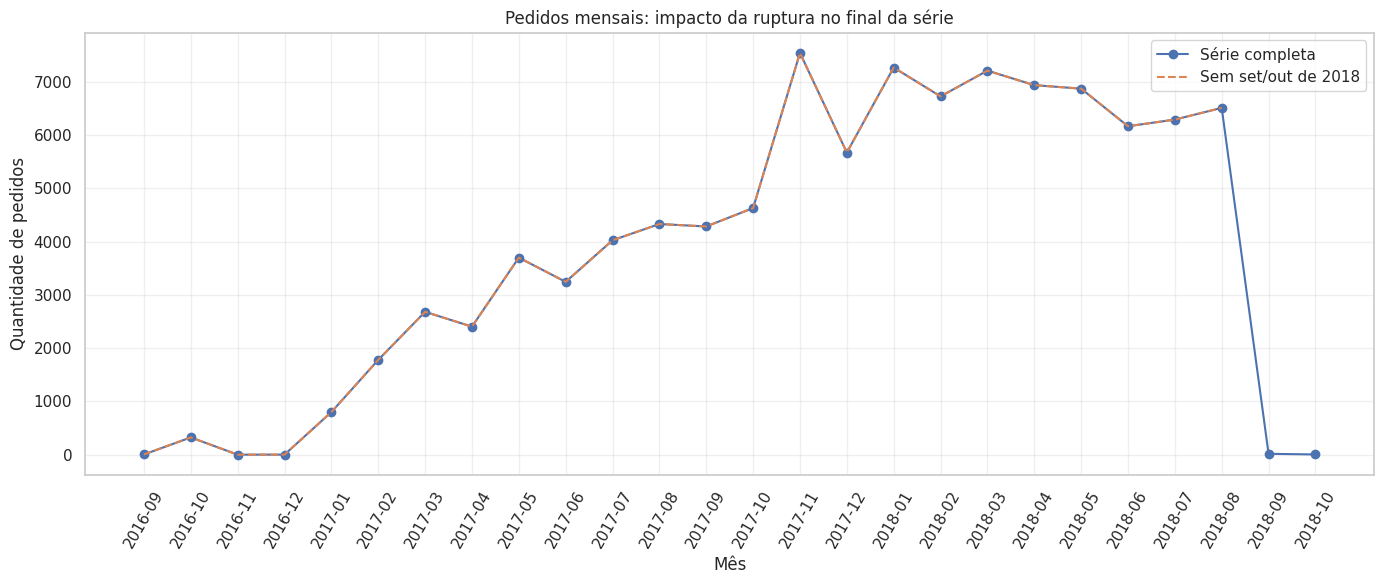

In [24]:

# vamos comparar a série mensal com e sem ruptura

import matplotlib.pyplot as plt

# Criar uma sequência mensal contínua, incluindo meses sem registros
todos_meses = pd.period_range(
    start=mensal.index.min(),
    end=mensal.index.max(),
    freq="M"
)

serie_pedidos = (
    mensal["quantidade_pedidos"]
    .reindex(todos_meses, fill_value=0)
)

# Série alternativa: setembro e outubro de 2018 ficam como ausentes
# para não serem confundidos com meses de atividade comercial normal.
serie_sem_fim = serie_pedidos.copy()
serie_sem_fim.loc[
    pd.Period("2018-09", freq="M"):
    pd.Period("2018-10", freq="M")
] = float("nan")

plt.figure(figsize=(14, 6))

plt.plot(
    serie_pedidos.index.astype(str),
    serie_pedidos.values,
    marker="o",
    label="Série completa"
)

plt.plot(
    serie_sem_fim.index.astype(str),
    serie_sem_fim.values,
    linestyle="--",
    label="Sem set/out de 2018"
)

plt.title("Pedidos mensais: impacto da ruptura no final da série")
plt.xlabel("Mês")
plt.ylabel("Quantidade de pedidos")
plt.xticks(rotation=60)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [25]:

# vamos validar os valores da tabela de itens

# 1. Verificar estrutura e valores ausentes
print("Dimensões:", order_items.shape)

print("\nValores ausentes:")
print(order_items.isna().sum())

# 2. Verificar duplicidade do identificador do item
print(
    "\nLinhas duplicadas completas:",
    order_items.duplicated().sum()
)

print(
    "Chaves duplicadas (pedido + número do item):",
    order_items.duplicated(
        subset=["order_id", "order_item_id"]
    ).sum()
)

# 3. Verificar preços e fretes
print("\nResumo estatístico de preço e frete:")
display(order_items[["price", "freight_value"]].describe().round(2))

print(
    "\nPreços iguais a zero:",
    (order_items["price"] == 0).sum()
)

print(
    "Preços negativos:",
    (order_items["price"] < 0).sum()
)

print(
    "Fretes negativos:",
    (order_items["freight_value"] < 0).sum()
)

# 4. Conferir a soma dos valores
print(
    "\nSoma dos preços dos itens (R$):",
    round(order_items["price"].sum(), 2)
)

print(
    "Soma dos fretes registrados nos itens (R$):",
    round(order_items["freight_value"].sum(), 2)
)


Dimensões: (112650, 7)

Valores ausentes:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Linhas duplicadas completas: 0
Chaves duplicadas (pedido + número do item): 0

Resumo estatístico de preço e frete:


,price,freight_value
count,"112,650.00","112,650.00"
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
25%,39.90,13.08
50%,74.99,16.26
75%,134.90,21.15
max,"6,735.00",409.68



Preços iguais a zero: 0
Preços negativos: 0
Fretes negativos: 0

Soma dos preços dos itens (R$): 13591643.7
Soma dos fretes registrados nos itens (R$): 2251909.54


In [26]:

# vamos consolidar o histórico mensal completo
# Período esperado: setembro/2016 a outubro/2018

# 1. Preparar a tabela de pedidos
pedidos = orders.copy()

pedidos["order_purchase_timestamp"] = pd.to_datetime(
    pedidos["order_purchase_timestamp"],
    errors="coerce"
)

pedidos["mes"] = (
    pedidos["order_purchase_timestamp"].dt.to_period("M")
)

# 2. Contar pedidos por mês
pedidos_mensais = (
    pedidos.groupby("mes")
    .agg(
        quantidade_pedidos=("order_id", "nunique")
    )
)

# 3. Associar os itens às datas dos pedidos
itens = order_items.merge(
    pedidos[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

itens["mes"] = (
    itens["order_purchase_timestamp"].dt.to_period("M")
)

# 4. Calcular os indicadores dos itens por mês
itens_mensais = (
    itens.groupby("mes")
    .agg(
        pedidos_com_itens=("order_id", "nunique"),
        quantidade_itens=("order_item_id", "size"),
        valor_itens=("price", "sum"),
        valor_frete=("freight_value", "sum")
    )
)

# 5. Preparar a tabela de pagamentos
payments = tabelas["olist_order_payments_dataset"].copy()

pagamentos = payments.merge(
    pedidos[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

pagamentos["mes"] = (
    pagamentos["order_purchase_timestamp"].dt.to_period("M")
)

pagamentos_mensais = (
    pagamentos.groupby("mes")
    .agg(
        pedidos_com_pagamento=("order_id", "nunique"),
        valor_pagamentos=("payment_value", "sum")
    )
)

# 6. Consolidar os indicadores
historico_mensal = (
    pedidos_mensais
    .join(itens_mensais, how="left")
    .join(pagamentos_mensais, how="left")
    .sort_index()
)

# 7. Completar os meses do calendário, se necessário
calendario = pd.period_range(
    start="2016-09",
    end="2018-10",
    freq="M"
)

historico_mensal = historico_mensal.reindex(calendario)
historico_mensal.index.name = "mes"

# Contagens e somas ausentes em meses sem registros passam a zero.
colunas_contagem_valor = [
    "quantidade_pedidos",
    "pedidos_com_itens",
    "quantidade_itens",
    "valor_itens",
    "valor_frete",
    "pedidos_com_pagamento",
    "valor_pagamentos"
]

historico_mensal[colunas_contagem_valor] = (
    historico_mensal[colunas_contagem_valor].fillna(0)
)

# 8. Exibir toda a série, em ordem cronológica
display(historico_mensal.round(2))

# 9. Conferir o intervalo e os totais
print("Primeiro mês:", historico_mensal.index.min())
print("Último mês:", historico_mensal.index.max())
print("Quantidade de meses:", len(historico_mensal))

print(
    "\nTotal de pedidos:",
    int(historico_mensal["quantidade_pedidos"].sum())
)

print(
    "Total do valor dos itens (R$):",
    round(historico_mensal["valor_itens"].sum(), 2)
)

print(
    "Total de pagamentos (R$):",
    round(historico_mensal["valor_pagamentos"].sum(), 2)
)


,quantidade_pedidos,pedidos_com_itens,quantidade_itens,valor_itens,valor_frete,pedidos_com_pagamento,valor_pagamentos
mes,,,,,,,
2016-09,4.00,3.00,6.00,267.36,87.39,3.00,252.24
2016-10,324.00,308.00,363.00,"49,507.66","7,301.18",324.00,"59,090.48"
2016-11,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2016-12,1.00,1.00,1.00,10.90,8.72,1.00,19.62
2017-01,800.00,789.00,955.00,"120,312.87","16,875.62",800.00,"138,488.04"
2017-02,"1,780.00","1,733.00","1,951.00","247,303.02","38,977.60","1,780.00","291,908.01"
2017-03,"2,682.00","2,641.00","3,000.00","374,344.30","57,704.29","2,682.00","449,863.60"
2017-04,"2,404.00","2,391.00","2,684.00","359,927.23","52,495.01","2,404.00","417,788.03"
2017-05,"3,700.00","3,660.00","4,136.00","506,071.14","80,119.81","3,700.00","592,918.82"


Primeiro mês: 2016-09
Último mês: 2018-10
Quantidade de meses: 26

Total de pedidos: 99441
Total do valor dos itens (R$): 13591643.7
Total de pagamentos (R$): 16008872.12


In [27]:

# vamos conferir os totois que consolidamos

total_pedidos_original = orders["order_id"].nunique()
total_itens_original = order_items["price"].sum()

payments_original = tabelas["olist_order_payments_dataset"]

total_pagamentos_original = payments_original["payment_value"].sum()

print("PEDIDOS")
print("Total na tabela original:", total_pedidos_original)
print(
    "Total na tabela mensal:",
    int(historico_mensal["quantidade_pedidos"].sum())
)

print("\nVALOR DOS ITENS")
print("Total na tabela original:", round(total_itens_original, 2))
print(
    "Total na tabela mensal:",
    round(historico_mensal["valor_itens"].sum(), 2)
)

print("\nPAGAMENTOS")
print("Total na tabela original:", round(total_pagamentos_original, 2))
print(
    "Total na tabela mensal:",
    round(historico_mensal["valor_pagamentos"].sum(), 2)
)


PEDIDOS
Total na tabela original: 99441
Total na tabela mensal: 99441

VALOR DOS ITENS
Total na tabela original: 13591643.7
Total na tabela mensal: 13591643.7

PAGAMENTOS
Total na tabela original: 16008872.12
Total na tabela mensal: 16008872.12


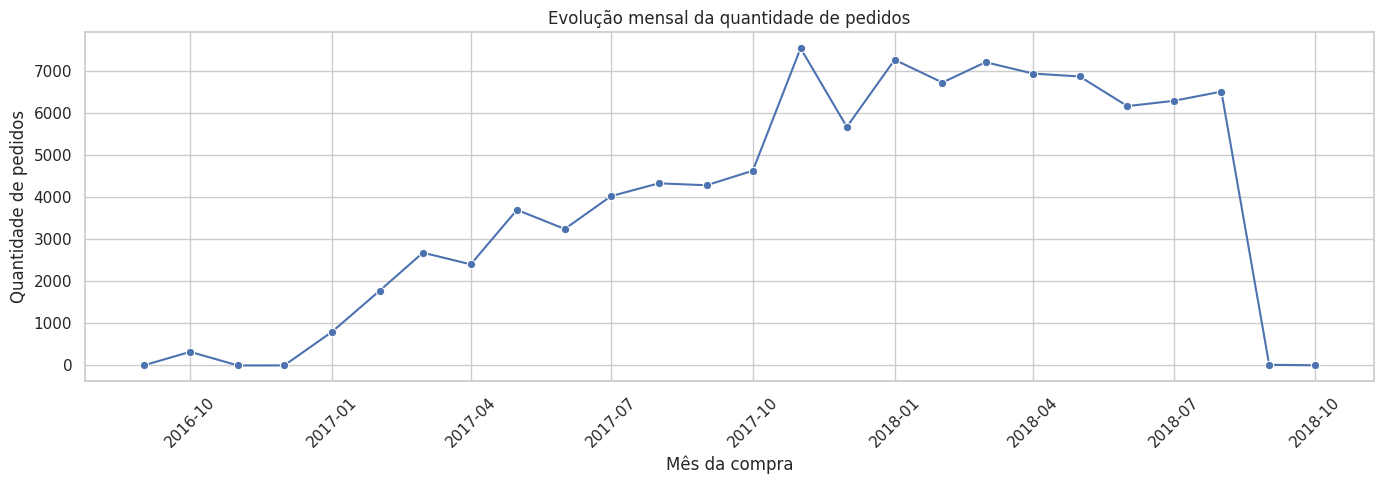

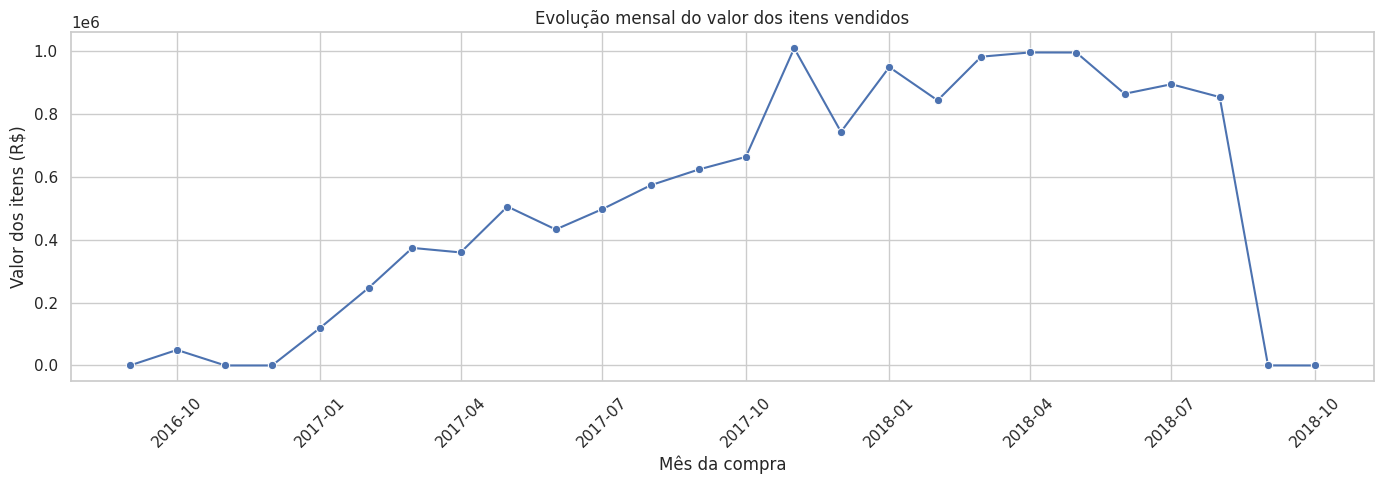

In [28]:

# vamos avaliar como foi a evolução mensal
# Histórico completo: setembro/2016 a outubro/2018

import matplotlib.pyplot as plt
import seaborn as sns

# Converter o índice mensal para datas, para facilitar o eixo X
historico_grafico = historico_mensal.copy()
historico_grafico["data"] = (
    historico_grafico.index.to_timestamp()
)

sns.set_theme(style="whitegrid")

# Gráfico 1: quantidade de pedidos
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=historico_grafico,
    x="data",
    y="quantidade_pedidos",
    marker="o"
)

plt.title("Evolução mensal da quantidade de pedidos")
plt.xlabel("Mês da compra")
plt.ylabel("Quantidade de pedidos")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Gráfico 2: valor dos itens vendidos
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=historico_grafico,
    x="data",
    y="valor_itens",
    marker="o"
)

plt.title("Evolução mensal do valor dos itens vendidos")
plt.xlabel("Mês da compra")
plt.ylabel("Valor dos itens (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [29]:


#vamos avaliar o crescinento mensal e o ticket médio
# Histórico completo

analise = historico_mensal.copy()

# 1. Ticket médio dos itens por pedido com itens
analise["ticket_medio_itens"] = (
    analise["valor_itens"]
    .div(analise["pedidos_com_itens"].replace(0, np.nan))
)

# 2. Variação percentual mensal dos pedidos
analise["variacao_pedidos_pct"] = (
    analise["quantidade_pedidos"].pct_change() * 100
)

# 3. Variação percentual mensal do valor dos itens
analise["variacao_valor_itens_pct"] = (
    analise["valor_itens"].pct_change() * 100
)

# 4. Exibir os indicadores mês a mês
colunas = [
    "quantidade_pedidos",
    "valor_itens",
    "ticket_medio_itens",
    "variacao_pedidos_pct",
    "variacao_valor_itens_pct"
]

display(analise[colunas].round(2))


,quantidade_pedidos,valor_itens,ticket_medio_itens,variacao_pedidos_pct,variacao_valor_itens_pct
mes,,,,,
2016-09,4.00,267.36,89.12,NaN,NaN
2016-10,324.00,"49,507.66",160.74,"8,000.00","18,417.23"
2016-11,0.00,0.00,NaN,-100.00,-100.00
2016-12,1.00,10.90,10.90,inf,inf
2017-01,800.00,"120,312.87",152.49,"79,900.00","1,103,687.80"
2017-02,"1,780.00","247,303.02",142.70,122.50,105.55
2017-03,"2,682.00","374,344.30",141.74,50.67,51.37
2017-04,"2,404.00","359,927.23",150.53,-10.37,-3.85
2017-05,"3,700.00","506,071.14",138.27,53.91,40.60


In [30]:

# avaliar o crescimento acumulado e possível volatilidade
# Comparação: janeiro a agosto de 2018

periodo_2018 = analise.loc[
    pd.Period("2018-01", freq="M"):
    pd.Period("2018-08", freq="M")
].copy()

# Crescimento acumulado entre janeiro e agosto
crescimento_pedidos = (
    periodo_2018["quantidade_pedidos"].iloc[-1]
    / periodo_2018["quantidade_pedidos"].iloc[0] - 1
) * 100

crescimento_valor = (
    periodo_2018["valor_itens"].iloc[-1]
    / periodo_2018["valor_itens"].iloc[0] - 1
) * 100

# Volatilidade: desvio-padrão das variações mensais
volatilidade_pedidos = (
    periodo_2018["variacao_pedidos_pct"].std()
)

volatilidade_valor = (
    periodo_2018["variacao_valor_itens_pct"].std()
)

print("JANEIRO A AGOSTO DE 2018")
print(f"Crescimento acumulado dos pedidos: {crescimento_pedidos:.2f}%")
print(f"Crescimento acumulado do valor dos itens: {crescimento_valor:.2f}%")
print(f"Volatilidade das variações dos pedidos: {volatilidade_pedidos:.2f}%")
print(f"Volatilidade das variações do valor dos itens: {volatilidade_valor:.2f}%")


JANEIRO A AGOSTO DE 2018
Crescimento acumulado dos pedidos: -10.41%
Crescimento acumulado do valor dos itens: -10.04%
Volatilidade das variações dos pedidos: 11.91%
Volatilidade das variações do valor dos itens: 13.74%


In [31]:

# comparar JANEIRO E AGOSTO DE 2018
# O valor dos itens caiu porque tivemos menos pedidos?
# Ou por que o valor médio por pedido também mudou?

comparacao = analise.loc[
    [
        pd.Period("2018-01", freq="M"),
        pd.Period("2018-08", freq="M")
    ],
    [
        "quantidade_pedidos",
        "pedidos_com_itens",
        "valor_itens",
        "ticket_medio_itens"
    ]
].copy()

display(comparacao.round(2))

# Calcular a variação entre janeiro e agosto
for coluna in [
    "quantidade_pedidos",
    "pedidos_com_itens",
    "valor_itens",
    "ticket_medio_itens"
]:
    janeiro = comparacao[coluna].iloc[0]
    agosto = comparacao[coluna].iloc[1]

    variacao = (agosto / janeiro - 1) * 100

    print(f"Variação de {coluna}: {variacao:.2f}%")


,quantidade_pedidos,pedidos_com_itens,valor_itens,ticket_medio_itens
mes,,,,
2018-01,"7,269.00","7,220.00","950,030.36",131.58
2018-08,"6,512.00","6,452.00","854,686.33",132.47


Variação de quantidade_pedidos: -10.41%
Variação de pedidos_com_itens: -10.64%
Variação de valor_itens: -10.04%
Variação de ticket_medio_itens: 0.67%


In [32]:

# Verificar quais tabelas estão carregadas no ambiente

for nome in [
    "orders",
    "order_items",
    "olist_customers_dataset",
    "customers",
    "pedidos",
    "itens"
]:
    print(f"{nome}: {nome in globals()}")


orders: True
order_items: True
olist_customers_dataset: False
customers: False
pedidos: True
itens: True


In [33]:

# Procurar o arquivo de clientes na pasta em que os dados foram extraídos

import os

for raiz, pastas, arquivos in os.walk("/content"):
    for arquivo in arquivos:
        if "olist_customers_dataset" in arquivo.lower():
            print(os.path.join(raiz, arquivo))


/content/olist/olist_customers_dataset.csv


In [34]:

# Carregar a tabela de clientes

customers = pd.read_csv(
    "/content/olist/olist_customers_dataset.csv"
)

# Conferir se a tabela foi carregada corretamente
print("Dimensões da tabela:", customers.shape)
print("Colunas:", customers.columns.tolist())

display(customers.head())


Dimensões da tabela: (99441, 5)
Colunas: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [35]:

# vamos cruzar pedidos, itens, clientes

# 1. Selecionar apenas as colunas necessárias
pedidos_base = orders[
    ["order_id", "customer_id", "order_purchase_timestamp",
     "order_status"]
].copy()

itens_base = order_items[
    ["order_id", "order_item_id", "price"]
].copy()

clientes_base = customers[
    ["customer_id", "customer_state"]
].copy()

# 2. Associar cada pedido aos seus itens
vendas = pedidos_base.merge(
    itens_base,
    on="order_id",
    how="inner",
    validate="one_to_many"
)

# 3. Associar cada pedido ao estado do cliente
vendas = vendas.merge(
    clientes_base,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# 4. Criar a coluna de mês
vendas["mes"] = (
    vendas["order_purchase_timestamp"]
    .dt.to_period("M")
)

# 5. Conferir o resultado
print("Quantidade de linhas:", len(vendas))
print("Pedidos únicos:", vendas["order_id"].nunique())
print("Estados ausentes:", vendas["customer_state"].isna().sum())
print("Datas ausentes:", vendas["order_purchase_timestamp"].isna().sum())

display(vendas.head())


Quantidade de linhas: 112650
Pedidos únicos: 98666
Estados ausentes: 0
Datas ausentes: 0


,order_id,customer_id,order_purchase_timestamp,order_status,order_item_id,price,customer_state,mes
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,delivered,1,29.99,SP,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,delivered,1,118.70,BA,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,delivered,1,159.90,GO,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,delivered,1,45.00,RN,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,delivered,1,19.90,SP,2018-02


In [36]:

# Recuperar as bibliotecas principais

import pandas as pd
import numpy as np

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

# Verificar se as tabelas continuam disponíveis
print("\nVerificação das tabelas:")
print("orders:", "orders" in globals())
print("order_items:", "order_items" in globals())
print("customers:", "customers" in globals())
print("vendas:", "vendas" in globals())


Pandas: 2.2.3
NumPy: 2.4.6

Verificação das tabelas:
orders: True
order_items: True
customers: True
vendas: True


In [37]:
# Verificar os arquivos disponíveis no ambiente

import os

print("Arquivos na pasta /content:")
print(os.listdir("/content"))

Arquivos na pasta /content:
['.config', 'archive (1).zip', 'olist', 'archive.zip', 'sample_data']


In [38]:
# Importar ferramenta de upload do Google Colab
from google.colab import files

# Selecionar o arquivo ZIP da base Olist
arquivos = files.upload()

Saving archive.zip to archive (2).zip


In [39]:
import zipfile
import os

# Identificar o nome do arquivo enviado
nome_zip = list(arquivos.keys())[0]

# Extrair os arquivos
with zipfile.ZipFile(nome_zip, "r") as zip_ref:
    zip_ref.extractall("/content/olist")

# Conferir os arquivos extraídos
print("Arquivos extraídos:")

for raiz, pastas, arquivos_encontrados in os.walk("/content/olist"):
    for arquivo in arquivos_encontrados:
        print(arquivo)

Arquivos extraídos:
product_category_name_translation.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_geolocation_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
olist_order_payments_dataset.csv
olist_order_items_dataset.csv
olist_customers_dataset.csv


In [40]:

# IMPORTAÇÃO DAS TABELAS DA BASE OLIST

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Configurações de visualização
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

# Caminho onde os arquivos foram extraídos
pasta = "/content/olist"

# Carregamento das nove tabelas
orders = pd.read_csv(f"{pasta}/olist_orders_dataset.csv")
order_items = pd.read_csv(f"{pasta}/olist_order_items_dataset.csv")
payments = pd.read_csv(f"{pasta}/olist_order_payments_dataset.csv")
sellers = pd.read_csv(f"{pasta}/olist_sellers_dataset.csv")
customers = pd.read_csv(f"{pasta}/olist_customers_dataset.csv")
reviews = pd.read_csv(f"{pasta}/olist_order_reviews_dataset.csv")
products = pd.read_csv(f"{pasta}/olist_products_dataset.csv")
geolocation = pd.read_csv(f"{pasta}/olist_geolocation_dataset.csv")
category_translation = pd.read_csv(f"{pasta}/product_category_name_translation.csv")

print("Todas as tabelas foram carregadas!")


Todas as tabelas foram carregadas!


In [41]:

#  VALIDAÇÃO DAS TABELAS CARREGADAS

tabelas = {
    "Pedidos": orders,
    "Itens dos pedidos": order_items,
    "Pagamentos": payments,
    "Vendedores": sellers,
    "Clientes": customers,
    "Avaliações": reviews,
    "Produtos": products,
    "Geolocalização": geolocation,
    "Tradução de categorias": category_translation
}

print("RESUMO DA BASE DE DADOS\n")

for nome, tabela in tabelas.items():
    print(f"{nome}: {tabela.shape[0]:,} linhas e {tabela.shape[1]} colunas")


RESUMO DA BASE DE DADOS

Pedidos: 99,441 linhas e 8 colunas
Itens dos pedidos: 112,650 linhas e 7 colunas
Pagamentos: 103,886 linhas e 5 colunas
Vendedores: 3,095 linhas e 4 colunas
Clientes: 99,441 linhas e 5 colunas
Avaliações: 99,224 linhas e 7 colunas
Produtos: 32,951 linhas e 9 colunas
Geolocalização: 1,000,163 linhas e 5 colunas
Tradução de categorias: 71 linhas e 2 colunas


In [42]:

# Visualizar os primeiros registros da tabela de pedidos

display(orders.head())


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [43]:

# verificando a estrutura e a qualidade das tabelas

for nome, tabela in tabelas.items():

    print("\n" + "=" * 60)
    print(f"tabela: {nome}")
    print("=" * 60)

    print("\ndimensões:", tabela.shape)

    print("\ntipos de variáveis:")
    print(tabela.dtypes)

    print("\nvalores ausentes por coluna:")
    print(tabela.isnull().sum())

    print("\npercentual de valores ausentes:")
    print((tabela.isnull().mean() * 100).round(2))

    print("\nlinhas duplicadas:")
    print(tabela.duplicated().sum())



tabela: Pedidos

dimensões: (99441, 8)

tipos de variáveis:
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

valores ausentes por coluna:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

percentual de valores ausentes:
order_id                        0.00
customer_id                     0.00
order_status                    0.00
order_purchase_timestamp        0.00
order_approved_at               0.16
order_delivered_carrier_date    1.79
ord

In [44]:

# analisando valores ausentes por status do pedido

colunas_datas = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

resumo_ausencias = orders.groupby("order_status").agg(
    quantidade_pedidos=("order_id", "count"),
    aprovacao_ausente=("order_approved_at", lambda x: x.isnull().sum()),
    envio_ausente=("order_delivered_carrier_date", lambda x: x.isnull().sum()),
    entrega_ausente=("order_delivered_customer_date", lambda x: x.isnull().sum())
)

display(resumo_ausencias)


,quantidade_pedidos,aprovacao_ausente,envio_ausente,entrega_ausente
order_status,,,,
approved,2,0,2,2
canceled,625,141,550,619
created,5,5,5,5
delivered,96478,14,2,8
invoiced,314,0,314,314
processing,301,0,301,301
shipped,1107,0,0,1107
unavailable,609,0,609,609


In [45]:

# verificando a distribuição dos pedidos por status

resumo_status = orders["order_status"].value_counts().to_frame(
    name="quantidade_pedidos"
)

resumo_status["percentual"] = (
    resumo_status["quantidade_pedidos"] /
    len(orders) * 100
).round(2)

display(resumo_status)


,quantidade_pedidos,percentual
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


In [46]:

# convertendo as colunas de data para datetime

colunas_datas = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for coluna in colunas_datas:
    orders[coluna] = pd.to_datetime(
        orders[coluna],
        errors="coerce"
    )

# conferindo os tipos após a conversão

print("tipos das colunas após conversão:")
print(orders[colunas_datas].dtypes)

# conferindo valores ausentes após a conversão

print("\nvalores ausentes:")
print(orders[colunas_datas].isnull().sum())


tipos das colunas após conversão:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

valores ausentes:
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [47]:
# verificar a distribuição mensal dos pedidos por status

orders["mes"] = orders["order_purchase_timestamp"].dt.to_period("M")

pedidos_status_mes = (
    orders
    .groupby(["mes", "order_status"])
    .size()
    .unstack(fill_value=0)
)

display(pedidos_status_mes)


order_status,approved,canceled,created,delivered,invoiced,processing,shipped,unavailable
mes,,,,,,,,
2016-09,0,2,0,1,0,0,1,0
2016-10,0,24,0,265,18,2,8,7
2016-12,0,0,0,1,0,0,0,0
2017-01,0,3,0,750,12,9,16,10
2017-02,1,17,0,1653,11,32,21,45
2017-03,0,33,0,2546,3,23,45,32
2017-04,1,18,0,2303,14,10,49,9
2017-05,0,29,0,3546,16,23,55,31
2017-06,0,16,0,3135,11,12,47,24


In [48]:
# definir o período de cobertura comercial
data_inicio = "2016-09-01"
data_fim = "2018-08-31"

# filtrar os pedidos dentro do período analisado
orders_analise = orders[
    (orders["order_purchase_timestamp"] >= data_inicio) &
    (orders["order_purchase_timestamp"] < "2018-09-01")
].copy()

# conferir o período e a quantidade de registros
print("primeiro pedido:", orders_analise["order_purchase_timestamp"].min())
print("último pedido:", orders_analise["order_purchase_timestamp"].max())
print("total de pedidos:", len(orders_analise))

primeiro pedido: 2016-09-04 21:15:19
último pedido: 2018-08-31 16:13:44
total de pedidos: 99421


In [49]:
# criar a visão mensal de pedidos
analise_mensal = orders_analise.groupby("mes").agg(
    pedidos_total=("order_id", "nunique"),
    pedidos_entregues=("order_status", lambda x: (x == "delivered").sum())
)

# calcular o percentual de pedidos entregues
analise_mensal["percentual_entregue"] = (
    analise_mensal["pedidos_entregues"] /
    analise_mensal["pedidos_total"]
) * 100

# exibir os resultados
display(analise_mensal.round(2))

,pedidos_total,pedidos_entregues,percentual_entregue
mes,,,
2016-09,4,1,25.00
2016-10,324,265,81.79
2016-12,1,1,100.00
2017-01,800,750,93.75
2017-02,1780,1653,92.87
2017-03,2682,2546,94.93
2017-04,2404,2303,95.80
2017-05,3700,3546,95.84
2017-06,3245,3135,96.61


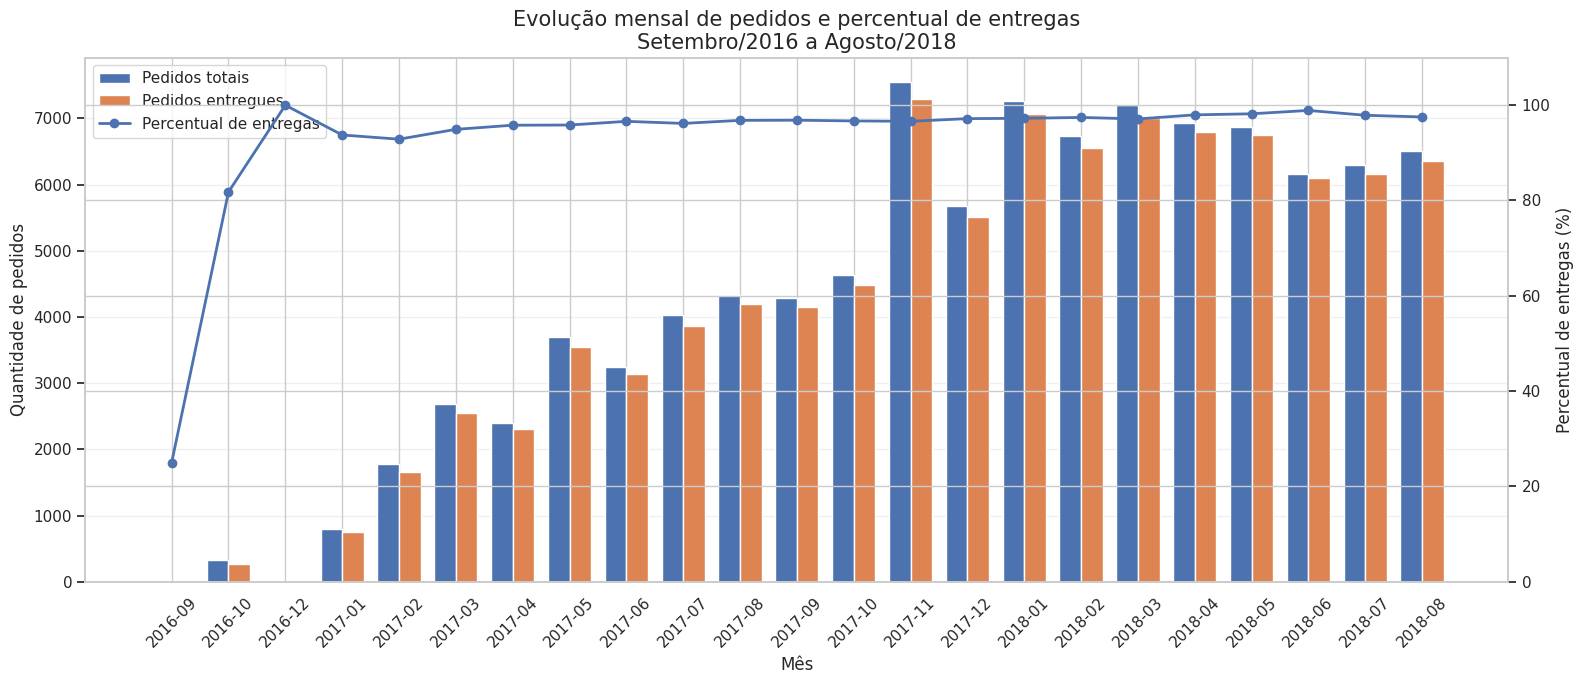

In [50]:
# criar a figura e o primeiro eixo
fig, ax1 = plt.subplots(figsize=(16, 7))

# definir as posições das barras
posicoes = np.arange(len(analise_mensal))
largura = 0.38

# plotar o total de pedidos
ax1.bar(
    posicoes - largura/2,
    analise_mensal["pedidos_total"],
    width=largura,
    label="Pedidos totais"
)

# plotar os pedidos entregues
ax1.bar(
    posicoes + largura/2,
    analise_mensal["pedidos_entregues"],
    width=largura,
    label="Pedidos entregues"
)

# configurar o eixo de quantidade
ax1.set_xlabel("Mês")
ax1.set_ylabel("Quantidade de pedidos")
ax1.set_xticks(posicoes)
ax1.set_xticklabels(analise_mensal.index.astype(str), rotation=45)
ax1.grid(axis="y", alpha=0.3)

# criar um segundo eixo para o percentual
ax2 = ax1.twinx()

# plotar o percentual de entregas
ax2.plot(
    posicoes,
    analise_mensal["percentual_entregue"],
    marker="o",
    linewidth=2,
    label="Percentual de entregas"
)

# configurar o eixo percentual
ax2.set_ylabel("Percentual de entregas (%)")
ax2.set_ylim(0, 110)

# reunir as legendas dos dois eixos
linhas1, legendas1 = ax1.get_legend_handles_labels()
linhas2, legendas2 = ax2.get_legend_handles_labels()

ax1.legend(
    linhas1 + linhas2,
    legendas1 + legendas2,
    loc="upper left"
)

# adicionar título e ajustar o layout
plt.title(
    "Evolução mensal de pedidos e percentual de entregas\n"
    "Setembro/2016 a Agosto/2018",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [51]:
# criar uma sequência completa de meses
todos_meses = pd.period_range(
    start="2016-09",
    end="2018-08",
    freq="M"
)

# incluir os meses sem registros na análise
analise_mensal = analise_mensal.reindex(todos_meses)

# calcular a variação mensal do volume total
analise_mensal["crescimento_pedidos_pct"] = (
    analise_mensal["pedidos_total"].pct_change(fill_method=None) * 100
)

# calcular a variação mensal dos pedidos entregues
analise_mensal["crescimento_entregues_pct"] = (
    analise_mensal["pedidos_entregues"].pct_change(fill_method=None) * 100
)

# visualizar os resultados
display(analise_mensal.round(2))

,pedidos_total,pedidos_entregues,percentual_entregue,crescimento_pedidos_pct,crescimento_entregues_pct
2016-09,4.00,1.00,25.00,NaN,NaN
2016-10,324.00,265.00,81.79,"8,000.00","26,400.00"
2016-11,NaN,NaN,NaN,NaN,NaN
2016-12,1.00,1.00,100.00,NaN,NaN
2017-01,800.00,750.00,93.75,"79,900.00","74,900.00"
2017-02,"1,780.00","1,653.00",92.87,122.50,120.40
2017-03,"2,682.00","2,546.00",94.93,50.67,54.02
2017-04,"2,404.00","2,303.00",95.80,-10.37,-9.54
2017-05,"3,700.00","3,546.00",95.84,53.91,53.97
2017-06,"3,245.00","3,135.00",96.61,-12.30,-11.59


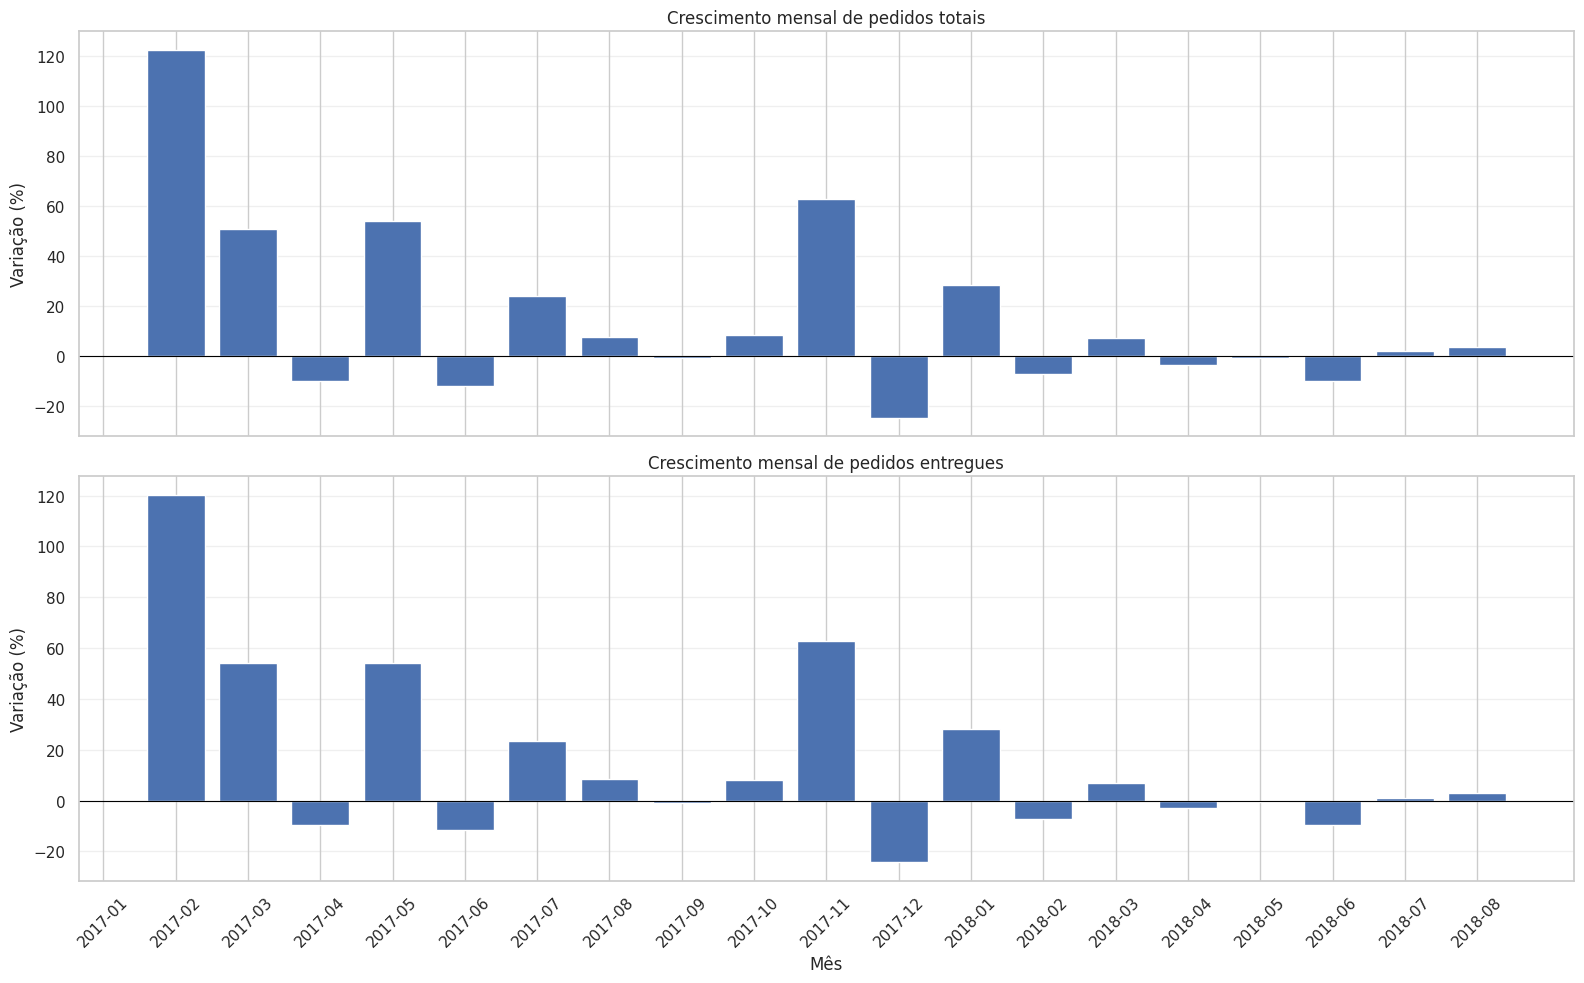

In [52]:
# criar uma cópia para preservar a tabela original
crescimento = analise_mensal.copy()

# desconsiderar os primeiros meses com base muito pequena
crescimento.loc[
    crescimento.index < pd.Period("2017-02", freq="M"),
    ["crescimento_pedidos_pct", "crescimento_entregues_pct"]
] = np.nan

# criar os gráficos
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# gráfico de crescimento dos pedidos totais
axes[0].bar(
    crescimento.index.astype(str),
    crescimento["crescimento_pedidos_pct"]
)

axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Crescimento mensal de pedidos totais")
axes[0].set_ylabel("Variação (%)")
axes[0].grid(axis="y", alpha=0.3)

# gráfico de crescimento dos pedidos entregues
axes[1].bar(
    crescimento.index.astype(str),
    crescimento["crescimento_entregues_pct"]
)

axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Crescimento mensal de pedidos entregues")
axes[1].set_ylabel("Variação (%)")
axes[1].set_xlabel("Mês")
axes[1].grid(axis="y", alpha=0.3)

# ajustar os rótulos do eixo horizontal
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

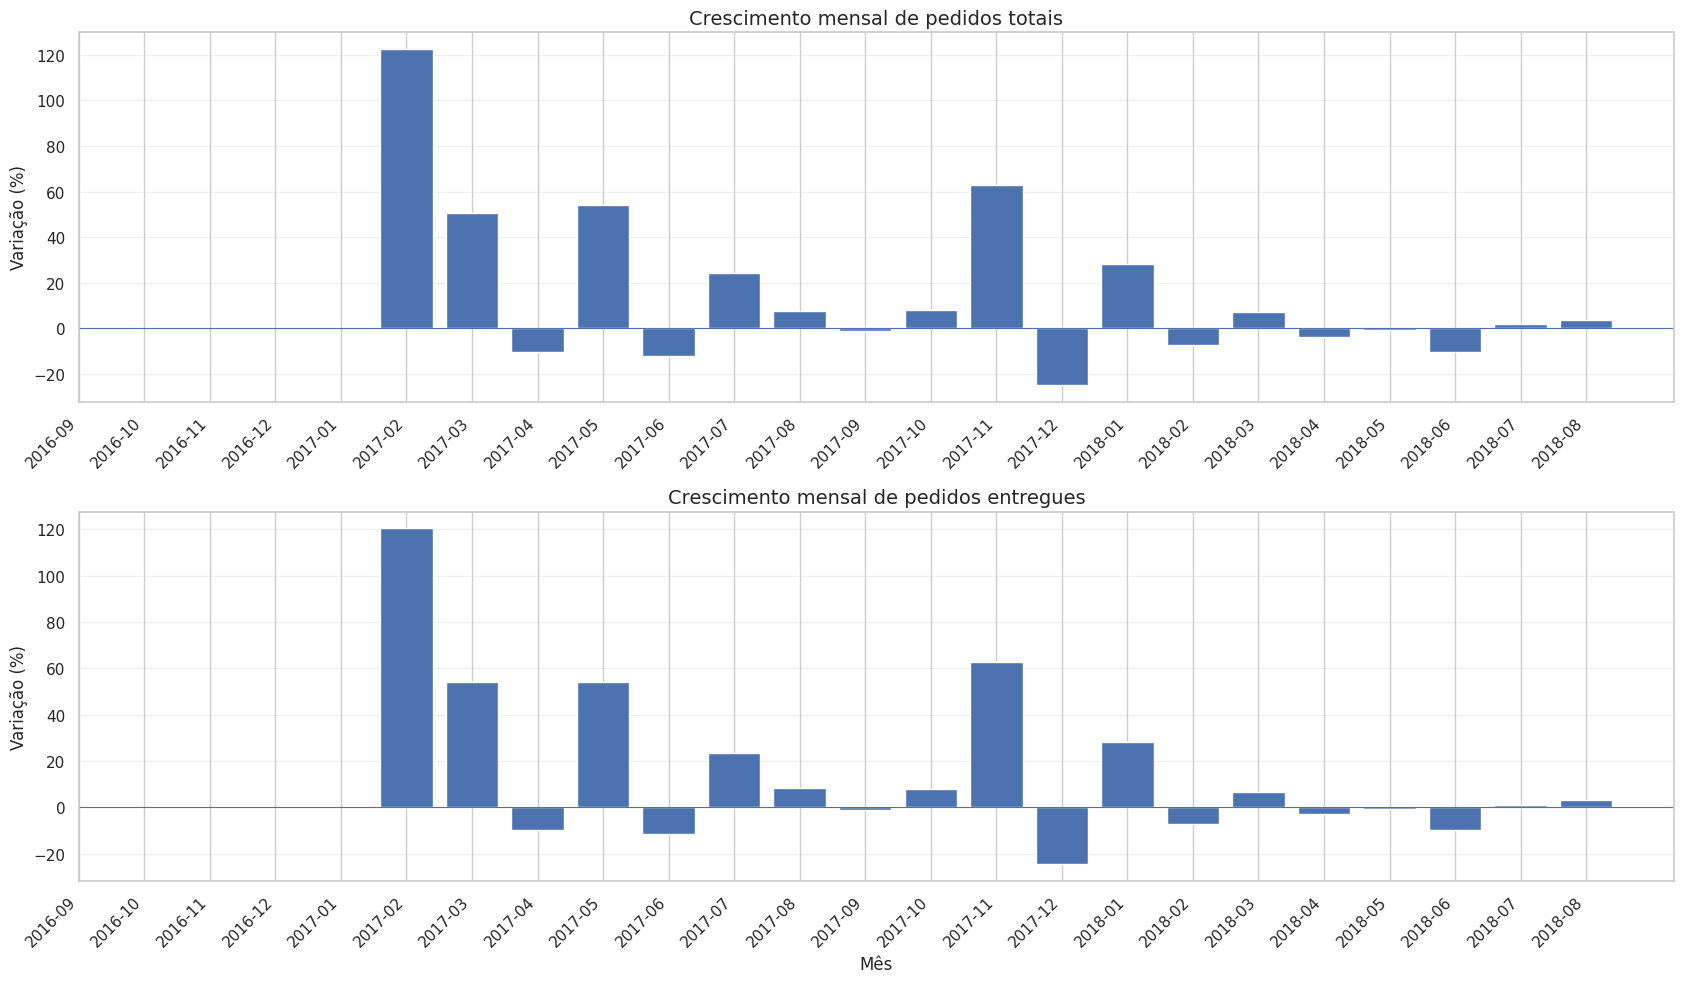

In [53]:
# criar uma cópia para preservar a tabela original
crescimento = analise_mensal.copy()

# retirar os meses iniciais com base muito pequena
crescimento.loc[
    crescimento.index < pd.Period("2017-02", freq="M"),
    ["crescimento_pedidos_pct", "crescimento_entregues_pct"]
] = np.nan

# criar os gráficos
fig, axes = plt.subplots(2, 1, figsize=(17, 10))

# gráfico de pedidos totais
axes[0].bar(
    crescimento.index.astype(str),
    crescimento["crescimento_pedidos_pct"]
)
axes[0].set_title("Crescimento mensal de pedidos totais", fontsize=14)
axes[0].set_ylabel("Variação (%)")
axes[0].set_xticks(range(len(crescimento)))
axes[0].set_xticklabels(crescimento.index.astype(str), rotation=45, ha="right")
axes[0].axhline(0, linewidth=0.8)
axes[0].grid(axis="y", alpha=0.3)
axes[0].set_axisbelow(True)

# gráfico de pedidos entregues
axes[1].bar(
    crescimento.index.astype(str),
    crescimento["crescimento_entregues_pct"]
)
axes[1].set_title("Crescimento mensal de pedidos entregues", fontsize=14)
axes[1].set_ylabel("Variação (%)")
axes[1].set_xlabel("Mês")
axes[1].set_xticks(range(len(crescimento)))
axes[1].set_xticklabels(crescimento.index.astype(str), rotation=45, ha="right")
axes[1].axhline(0, linewidth=0.8)
axes[1].grid(axis="y", alpha=0.3)
axes[1].set_axisbelow(True)

# ajustar espaçamento
plt.tight_layout()
plt.show()

In [54]:
# separar os mesmos meses dos dois anos
pedidos_2017 = analise_mensal.loc["2017-01":"2017-08", "pedidos_total"]
pedidos_2018 = analise_mensal.loc["2018-01":"2018-08", "pedidos_total"]

# calcular os indicadores de cada período
comparacao = pd.DataFrame({
    "2017": [
        pedidos_2017.sum(),
        pedidos_2017.mean(),
        pedidos_2017.median(),
        pedidos_2017.min(),
        pedidos_2017.max(),
        pedidos_2017.std()
    ],
    "2018": [
        pedidos_2018.sum(),
        pedidos_2018.mean(),
        pedidos_2018.median(),
        pedidos_2018.min(),
        pedidos_2018.max(),
        pedidos_2018.std()
    ]
}, index=[
    "total de pedidos",
    "média mensal",
    "mediana mensal",
    "menor volume mensal",
    "maior volume mensal",
    "desvio padrão"
])

display(comparacao.round(2))

,2017,2018
total de pedidos,"22,968.00","53,991.00"
média mensal,"2,871.00","6,748.88"
mediana mensal,"2,963.50","6,800.50"
menor volume mensal,800.00,"6,167.00"
maior volume mensal,"4,331.00","7,269.00"
desvio padrão,"1,196.77",403.47


In [55]:
# calcular o coeficiente de variação de cada período
cv_2017 = (
    pedidos_2017.std() / pedidos_2017.mean()
) * 100

cv_2018 = (
    pedidos_2018.std() / pedidos_2018.mean()
) * 100

# organizar os resultados
comparacao_cv = pd.DataFrame({
    "Período": ["2017", "2018"],
    "Coeficiente de variação (%)": [cv_2017, cv_2018]
})

display(comparacao_cv.round(2))

,Período,Coeficiente de variação (%)
0,2017,41.68
1,2018,5.98


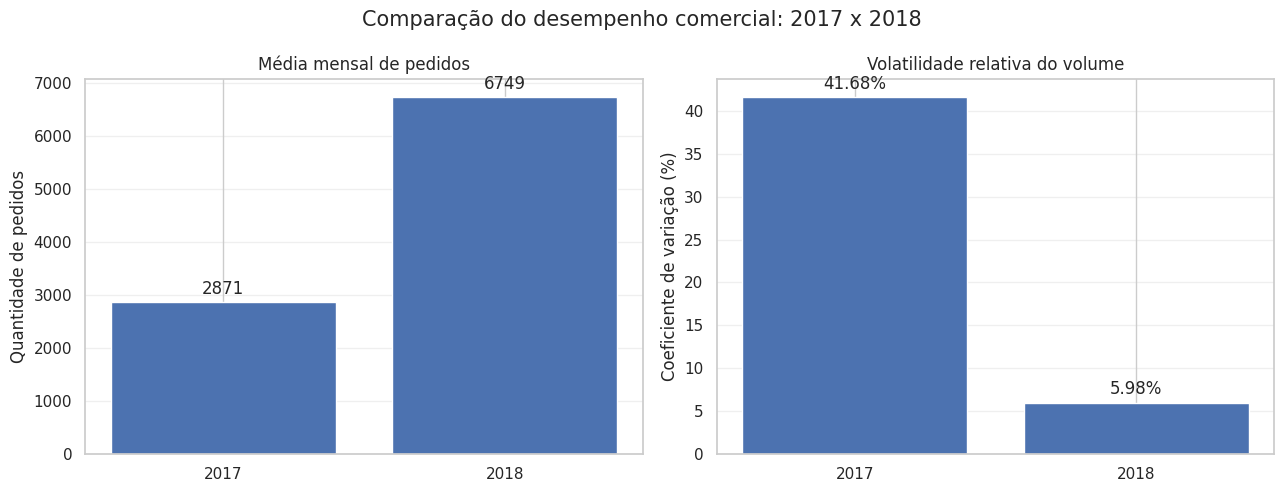

In [56]:
# organizar os indicadores para visualização
indicadores = pd.DataFrame({
    "Período": ["2017", "2018"],
    "Média mensal de pedidos": [
        pedidos_2017.mean(),
        pedidos_2018.mean()
    ],
    "Coeficiente de variação (%)": [
        cv_2017,
        cv_2018
    ]
})

# criar os gráficos
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# gráfico da média mensal
barras1 = axes[0].bar(
    indicadores["Período"],
    indicadores["Média mensal de pedidos"]
)

axes[0].set_title("Média mensal de pedidos")
axes[0].set_ylabel("Quantidade de pedidos")
axes[0].grid(axis="y", alpha=0.3)

# adicionar os valores nas barras
axes[0].bar_label(barras1, fmt="%.0f", padding=3)

# gráfico do coeficiente de variação
barras2 = axes[1].bar(
    indicadores["Período"],
    indicadores["Coeficiente de variação (%)"]
)

axes[1].set_title("Volatilidade relativa do volume")
axes[1].set_ylabel("Coeficiente de variação (%)")
axes[1].grid(axis="y", alpha=0.3)

# adicionar os valores nas barras
axes[1].bar_label(barras2, fmt="%.2f%%", padding=3)

# ajustar apresentação
for ax in axes:
    ax.set_axisbelow(True)

fig.suptitle(
    "Comparação do desempenho comercial: 2017 x 2018",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [57]:
# relacionar pedidos e itens
pedidos_itens = orders_analise[
    ["order_id", "mes", "order_status"]
].merge(
    order_items[["order_id", "price", "freight_value"]],
    on="order_id",
    how="inner"
)

# calcular indicadores comerciais mensais
analise_comercial = pedidos_itens.groupby("mes").agg(
    pedidos=("order_id", "nunique"),
    gmv=("price", "sum"),
    frete=("freight_value", "sum")
)

# calcular o ticket médio por pedido
analise_comercial["ticket_medio"] = (
    analise_comercial["gmv"] /
    analise_comercial["pedidos"]
)

# exibir os resultados
display(analise_comercial.round(2))

,pedidos,gmv,frete,ticket_medio
mes,,,,
2016-09,3,267.36,87.39,89.12
2016-10,308,"49,507.66","7,301.18",160.74
2016-12,1,10.90,8.72,10.90
2017-01,789,"120,312.87","16,875.62",152.49
2017-02,1733,"247,303.02","38,977.60",142.70
2017-03,2641,"374,344.30","57,704.29",141.74
2017-04,2391,"359,927.23","52,495.01",150.53
2017-05,3660,"506,071.14","80,119.81",138.27
2017-06,3217,"433,038.60","69,924.44",134.61


In [58]:
# consolidar o valor dos produtos e fretes por pedido
itens_por_pedido = order_items.groupby("order_id").agg(
    valor_produtos=("price", "sum"),
    valor_frete=("freight_value", "sum")
)

# calcular o volume transacionado estimado
itens_por_pedido["valor_produtos_frete"] = (
    itens_por_pedido["valor_produtos"] +
    itens_por_pedido["valor_frete"]
)

# consolidar todos os pagamentos por pedido
pagamentos_por_pedido = payments.groupby("order_id").agg(
    valor_pagamento=("payment_value", "sum"),
    quantidade_pagamentos=("payment_sequential", "count")
)

# comparar os valores
conciliacao = itens_por_pedido.join(
    pagamentos_por_pedido,
    how="inner"
)

# calcular a diferença entre os valores
conciliacao["diferenca"] = (
    conciliacao["valor_produtos_frete"] -
    conciliacao["valor_pagamento"]
)

# visualizar os resultados
display(conciliacao.head(10).round(2))

,valor_produtos,valor_frete,valor_produtos_frete,valor_pagamento,quantidade_pagamentos,diferenca
order_id,,,,,,
00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,72.19,72.19,1,0.00
00018f77f2f0320c557190d7a144bdd3,239.90,19.93,259.83,259.83,1,0.00
000229ec398224ef6ca0657da4fc703e,199.00,17.87,216.87,216.87,1,0.00
00024acbcdf0a6daa1e931b038114c75,12.99,12.79,25.78,25.78,1,0.00
00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,218.04,218.04,1,0.00
00048cc3ae777c65dbb7d2a0634bc1ea,21.90,12.69,34.59,34.59,1,-0.00
00054e8431b9d7675808bcb819fb4a32,19.90,11.85,31.75,31.75,1,0.00
000576fe39319847cbb9d288c5617fa6,810.00,70.75,880.75,880.75,1,0.00
0005a1a1728c9d785b8e2b08b904576c,145.95,11.65,157.60,157.60,1,0.00


In [59]:
# classificar a conciliação dos pedidos
conciliacao["conciliado"] = np.isclose(
    conciliacao["valor_produtos_frete"],
    conciliacao["valor_pagamento"],
    atol=0.01
)

# calcular os indicadores gerais
total_pedidos = len(conciliacao)
pedidos_conciliados = conciliacao["conciliado"].sum()
pedidos_divergentes = total_pedidos - pedidos_conciliados

resumo_conciliacao = pd.DataFrame({
    "indicador": [
        "pedidos comparados",
        "pedidos conciliados",
        "pedidos divergentes",
        "percentual conciliado"
    ],
    "valor": [
        total_pedidos,
        pedidos_conciliados,
        pedidos_divergentes,
        pedidos_conciliados / total_pedidos * 100
    ]
})

display(resumo_conciliacao)

,indicador,valor
0,pedidos comparados,"98,665.00"
1,pedidos conciliados,"98,365.00"
2,pedidos divergentes,300.00
3,percentual conciliado,99.70


In [60]:
# separar os pedidos com diferenças
divergencias = conciliacao[
    ~conciliacao["conciliado"]
].copy()

# ordenar pelas maiores diferenças absolutas
divergencias["diferenca_absoluta"] = (
    divergencias["diferenca"].abs()
)

divergencias = divergencias.sort_values(
    "diferenca_absoluta",
    ascending=False
)

display(divergencias.head(15).round(2))

,valor_produtos,valor_frete,valor_produtos_frete,valor_pagamento,quantidade_pagamentos,diferenca,conciliado,diferenca_absoluta
order_id,,,,,,,,
ce6d150fb29ada17d2082f4847107665,"1,299.00",104.66,"1,403.66","1,586.47",1,-182.81,False,182.81
6e5fe7366a2e1bfbf3257dba0af1267f,179.19,108.72,287.91,406.92,1,-119.01,False,119.01
70b742795bc441e94a44a084b6d9ce7a,269.99,196.94,466.93,578.82,1,-111.89,False,111.89
996c7e73600ad3723e8627ab7bef81e4,559.90,28.00,587.90,664.43,1,-76.53,False,76.53
70b7e94ea46d3e8b5bc12a50186edaf0,167.88,45.27,213.15,274.84,1,-61.69,False,61.69
bc2c82b0ef78d2252b6176d1972db7c9,165.00,77.01,242.01,303.02,1,-61.01,False,61.01
af9ffff2ce6b3defd34fd4c78857a379,395.65,17.52,413.17,466.97,1,-53.80,False,53.80
262118ce178bb3e4590a3adcf6d62e6b,119.80,57.94,177.74,126.12,1,51.62,False,51.62
bfdb5bbb06458d600a33d61f5f287472,297.00,51.93,348.93,394.36,1,-45.43,False,45.43


In [61]:
# resumir os tipos de pagamento por pedido
tipos_pagamento = payments.groupby("order_id").agg(
    tipos=("payment_type", lambda x: ", ".join(sorted(x.unique())))
)

# adicionar status e tipos de pagamento às divergências
divergencias_detalhadas = divergencias.join(
    orders.set_index("order_id")[["order_status"]]
).join(tipos_pagamento)

# classificar o sentido da diferença
divergencias_detalhadas["sentido"] = np.where(
    divergencias_detalhadas["diferenca"] > 0,
    "produtos e frete maiores",
    "pagamento maior"
)

# analisar as divergências por status
display(
    divergencias_detalhadas.groupby("order_status").agg(
        pedidos=("diferenca", "count"),
        diferenca_media=("diferenca", "mean"),
        diferenca_total=("diferenca", "sum")
    ).round(2)
)

# analisar as divergências por tipo de pagamento
display(
    divergencias_detalhadas.groupby("tipos").agg(
        pedidos=("diferenca", "count"),
        diferenca_media=("diferenca", "mean"),
        diferenca_total=("diferenca", "sum")
    ).sort_values("pedidos", ascending=False).round(2)
)

,pedidos,diferenca_media,diferenca_total
order_status,,,
canceled,2,-16.01,-32.01
delivered,296,-9.57,"-2,832.08"
shipped,2,-3.46,-6.91


,pedidos,diferenca_media,diferenca_total
tipos,,,
credit_card,273,-10.64,"-2,905.45"
boleto,13,-0.00,-0.02
"credit_card, voucher",7,-2.50,-17.48
debit_card,7,7.42,51.95


In [62]:
# selecionar os 10 pedidos com maiores diferenças
amostra_divergencias = divergencias_detalhadas.head(10)

# recuperar os itens desses pedidos
itens_amostra = order_items[
    order_items["order_id"].isin(amostra_divergencias.index)
]

# recuperar os pagamentos desses pedidos
pagamentos_amostra = payments[
    payments["order_id"].isin(amostra_divergencias.index)
]

# exibir os registros originais
display(itens_amostra.sort_values("order_id"))
display(pagamentos_amostra.sort_values("order_id"))

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
16662,262118ce178bb3e4590a3adcf6d62e6b,1,6aeed495dcb87dd06532f70dea6ebb5a,b56906f7fd1696e043f1bcce164c487b,2016-10-11 12:13:50,59.90,28.97
16663,262118ce178bb3e4590a3adcf6d62e6b,2,6aeed495dcb87dd06532f70dea6ebb5a,b56906f7fd1696e043f1bcce164c487b,2016-10-11 12:13:50,59.90,28.97
48566,6e5fe7366a2e1bfbf3257dba0af1267f,1,7721582bb750762d81850267d19881c1,0c8380b62e38e8a1e6adbeba7eb9688c,2016-10-14 12:02:21,19.83,17.00
48567,6e5fe7366a2e1bfbf3257dba0af1267f,2,65bb78cf0bbc3ca6406f30e6793736f9,391fc6631aebcf3004804e51b40bcf1e,2016-10-14 12:02:20,39.90,19.24
48568,6e5fe7366a2e1bfbf3257dba0af1267f,3,7721582bb750762d81850267d19881c1,0c8380b62e38e8a1e6adbeba7eb9688c,2016-10-14 12:02:21,19.83,17.00
48569,6e5fe7366a2e1bfbf3257dba0af1267f,4,65bb78cf0bbc3ca6406f30e6793736f9,391fc6631aebcf3004804e51b40bcf1e,2016-10-14 12:02:20,39.90,19.24
48570,6e5fe7366a2e1bfbf3257dba0af1267f,5,7721582bb750762d81850267d19881c1,0c8380b62e38e8a1e6adbeba7eb9688c,2016-10-14 12:02:21,19.83,17.00
48571,6e5fe7366a2e1bfbf3257dba0af1267f,6,65bb78cf0bbc3ca6406f30e6793736f9,391fc6631aebcf3004804e51b40bcf1e,2016-10-14 12:02:20,39.90,19.24
49611,70b742795bc441e94a44a084b6d9ce7a,1,1dd284c37ca97cbb86c029c65fb9a494,070d165398b553f3b4b851c216b8a358,2017-08-30 10:35:22,269.99,196.94
49616,70b7e94ea46d3e8b5bc12a50186edaf0,3,c1eee16d856657ad280936810ef3d080,014d9a685fd57276679edd00e07089e5,2018-01-05 13:17:25,69.99,3.15


,order_id,payment_sequential,payment_type,payment_installments,payment_value
85540,262118ce178bb3e4590a3adcf6d62e6b,1,credit_card,5,126.12
38060,6e5fe7366a2e1bfbf3257dba0af1267f,1,credit_card,10,406.92
25761,70b742795bc441e94a44a084b6d9ce7a,1,credit_card,20,578.82
2970,70b7e94ea46d3e8b5bc12a50186edaf0,1,credit_card,24,274.84
95180,8d9c0dc8d5a2ce804f6b925d8f8e6c1d,1,credit_card,12,293.89
61856,996c7e73600ad3723e8627ab7bef81e4,1,credit_card,10,664.43
4954,af9ffff2ce6b3defd34fd4c78857a379,1,credit_card,10,466.97
27307,bc2c82b0ef78d2252b6176d1972db7c9,1,credit_card,21,303.02
41563,bfdb5bbb06458d600a33d61f5f287472,1,credit_card,10,394.36
359,ce6d150fb29ada17d2082f4847107665,1,credit_card,10,"1,586.47"


In [63]:
# filtrar apenas os pedidos entregues
itens_entregues = pedidos_itens[
    pedidos_itens["order_status"] == "delivered"
].copy()

# calcular o valor transacionado por item
itens_entregues["gmv_item"] = (
    itens_entregues["price"] +
    itens_entregues["freight_value"]
)

# consolidar os indicadores por mês
analise_gmv = itens_entregues.groupby("mes").agg(
    pedidos=("order_id", "nunique"),
    gmv_produtos=("price", "sum"),
    frete=("freight_value", "sum"),
    gmv=("gmv_item", "sum")
)

# calcular o ticket médio por pedido
analise_gmv["ticket_medio"] = (
    analise_gmv["gmv"] / analise_gmv["pedidos"]
)

# organizar os meses da série histórica
todos_meses = pd.period_range(
    start="2016-09",
    end="2018-08",
    freq="M"
)

analise_gmv = analise_gmv.reindex(todos_meses)
analise_gmv.index.name = "mes"

# visualizar os resultados
display(analise_gmv.round(2))

,pedidos,gmv_produtos,frete,gmv,ticket_medio
mes,,,,,
2016-09,1.00,134.97,8.49,143.46,143.46
2016-10,265.00,"40,325.11","6,165.55","46,490.66",175.44
2016-11,NaN,NaN,NaN,NaN,NaN
2016-12,1.00,10.90,8.72,19.62,19.62
2017-01,750.00,"111,798.36","15,684.01","127,482.37",169.98
2017-02,"1,653.00","234,223.40","37,015.92","271,239.32",164.09
2017-03,"2,546.00","359,198.85","55,132.10","414,330.95",162.74
2017-04,"2,303.00","340,669.68","50,142.72","390,812.40",169.70
2017-05,"3,546.00","489,338.25","77,513.15","566,851.40",159.86


In [64]:
# comparar os mesmos meses dos dois anos
periodos = {
    "2017": analise_gmv.loc["2017-01":"2017-08"],
    "2018": analise_gmv.loc["2018-01":"2018-08"]
}

comparacao_anual = pd.DataFrame({
    ano: {
        "gmv_total": dados["gmv"].sum(),
        "pedidos_total": dados["pedidos"].sum(),
        "gmv_medio_mensal": dados["gmv"].mean(),
        "pedidos_medios_mensais": dados["pedidos"].mean(),
        "ticket_medio_ponderado": (
            dados["gmv"].sum() / dados["pedidos"].sum()
        )
    }
    for ano, dados in periodos.items()
}).T

# calcular a variação percentual entre os períodos
comparacao_anual.loc["crescimento_pct"] = (
    (comparacao_anual.loc["2018"] /
     comparacao_anual.loc["2017"] - 1) * 100
)

display(comparacao_anual.round(2))

,gmv_total,pedidos_total,gmv_medio_mensal,pedidos_medios_mensais,ticket_medio_ponderado
2017,"3,472,898.25","21,998.00","434,112.28","2,749.75",157.87
2018,"8,451,584.77","52,783.00","1,056,448.10","6,597.88",160.12
crescimento_pct,143.36,139.94,143.36,139.94,1.42


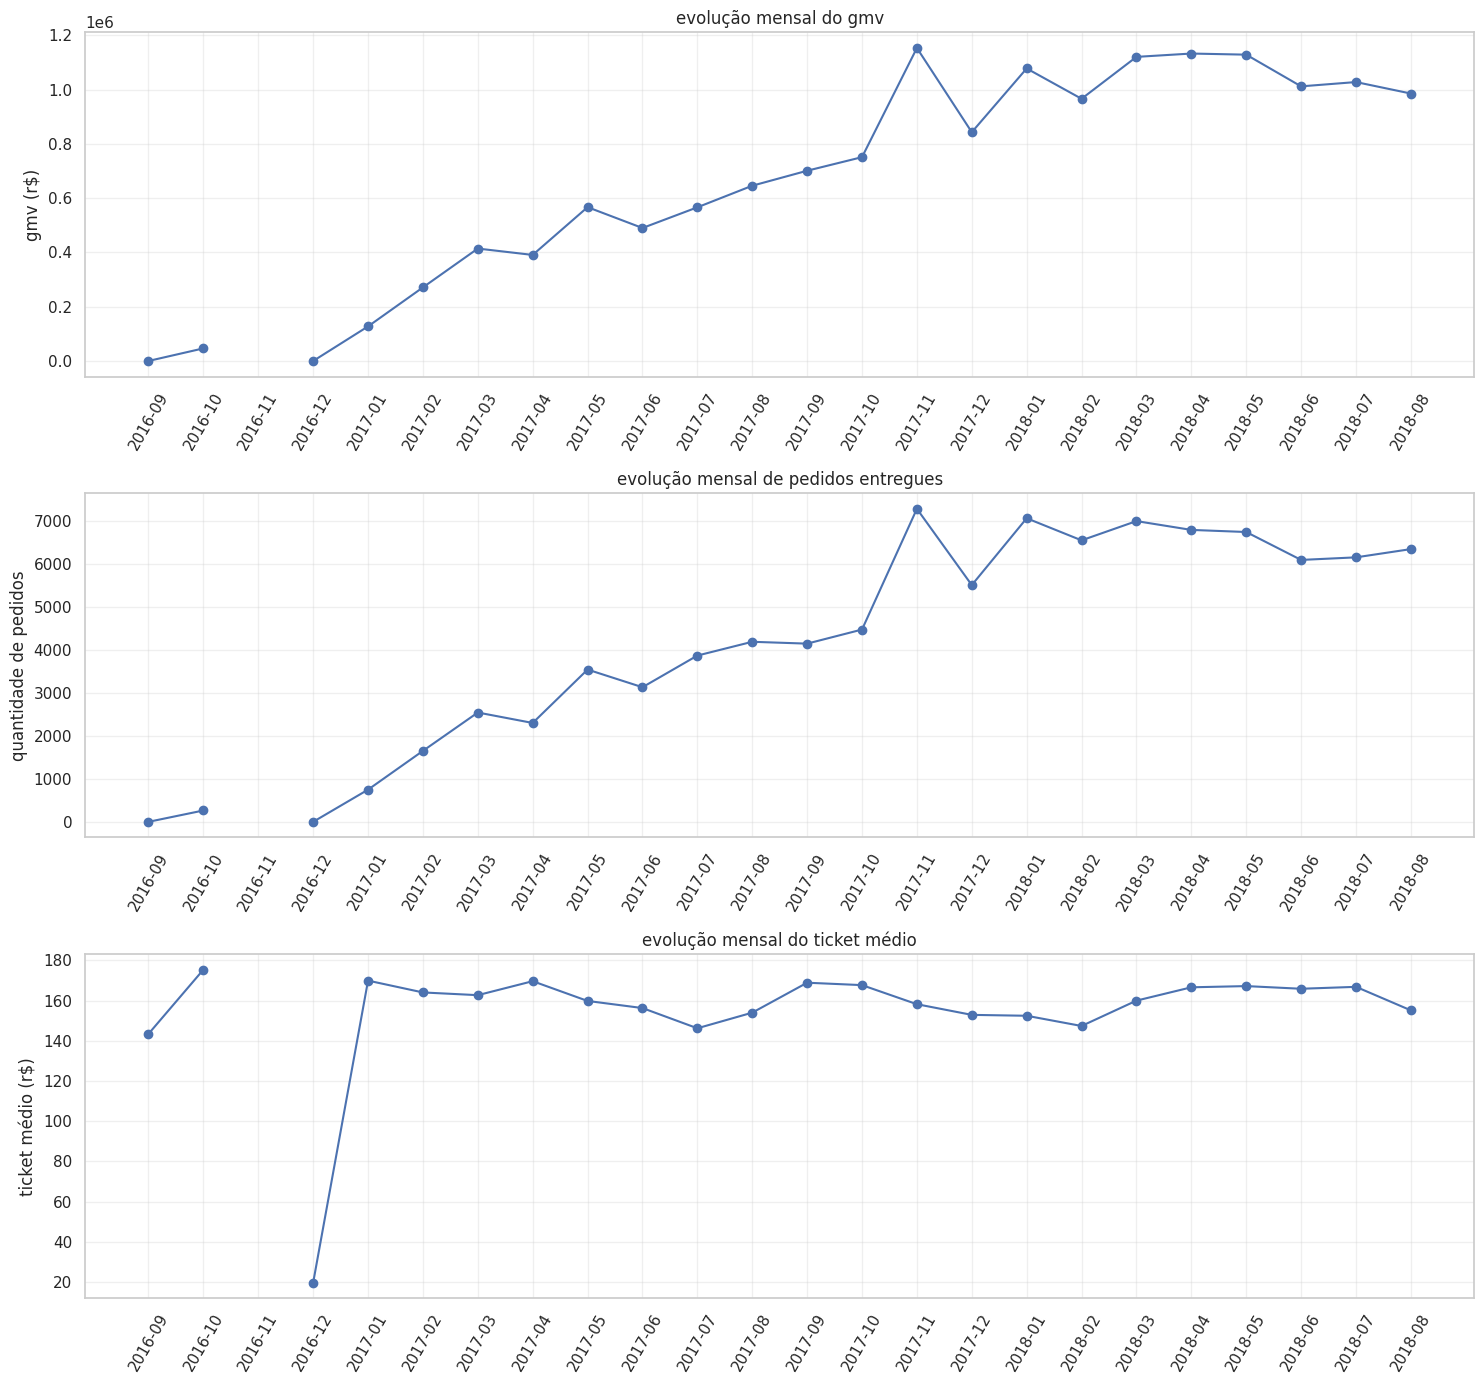

In [65]:
# criar os gráficos da evolução comercial
fig, axes = plt.subplots(3, 1, figsize=(15, 14))

# gráfico de gmv mensal
axes[0].plot(
    analise_gmv.index.astype(str),
    analise_gmv["gmv"],
    marker="o"
)
axes[0].set_title("evolução mensal do gmv")
axes[0].set_ylabel("gmv (r$)")
axes[0].grid(alpha=0.3)

# gráfico de pedidos entregues
axes[1].plot(
    analise_gmv.index.astype(str),
    analise_gmv["pedidos"],
    marker="o"
)
axes[1].set_title("evolução mensal de pedidos entregues")
axes[1].set_ylabel("quantidade de pedidos")
axes[1].grid(alpha=0.3)

# gráfico de ticket médio
axes[2].plot(
    analise_gmv.index.astype(str),
    analise_gmv["ticket_medio"],
    marker="o"
)
axes[2].set_title("evolução mensal do ticket médio")
axes[2].set_ylabel("ticket médio (r$)")
axes[2].grid(alpha=0.3)

# ajustar os rótulos dos meses
for ax in axes:
    ax.tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

In [66]:
# selecionar os meses de janeiro a agosto de 2018
gmv_2018 = analise_gmv.loc["2018-01":"2018-08"].copy()

# calcular a variação percentual mensal
gmv_2018["variacao_mensal_pct"] = (
    gmv_2018["gmv"].pct_change(fill_method=None) * 100
)

# calcular os indicadores de estabilidade
estabilidade_2018 = pd.DataFrame({
    "indicador": [
        "gmv medio mensal",
        "gmv mediano mensal",
        "desvio padrao",
        "coeficiente de variacao",
        "gmv minimo",
        "gmv maximo",
        "amplitude"
    ],
    "valor": [
        gmv_2018["gmv"].mean(),
        gmv_2018["gmv"].median(),
        gmv_2018["gmv"].std(),
        (gmv_2018["gmv"].std() / gmv_2018["gmv"].mean()) * 100,
        gmv_2018["gmv"].min(),
        gmv_2018["gmv"].max(),
        gmv_2018["gmv"].max() - gmv_2018["gmv"].min()
    ]
})

display(estabilidade_2018.round(2))

# visualizar as variações mensais
display(
    gmv_2018[["gmv", "variacao_mensal_pct"]].round(2)
)

,indicador,valor
0,gmv medio mensal,"1,056,448.10"
1,gmv mediano mensal,"1,052,847.37"
2,desvio padrao,"67,221.14"
3,coeficiente de variacao,6.36
4,gmv minimo,"966,168.41"
5,gmv maximo,"1,132,878.93"
6,amplitude,"166,710.52"


,gmv,variacao_mensal_pct
mes,,
2018-01,"1,077,887.46",NaN
2018-02,"966,168.41",-10.36
2018-03,"1,120,598.24",15.98
2018-04,"1,132,878.93",1.10
2018-05,"1,128,774.52",-0.36
2018-06,"1,011,978.29",-10.35
2018-07,"1,027,807.28",1.56
2018-08,"985,491.64",-4.12


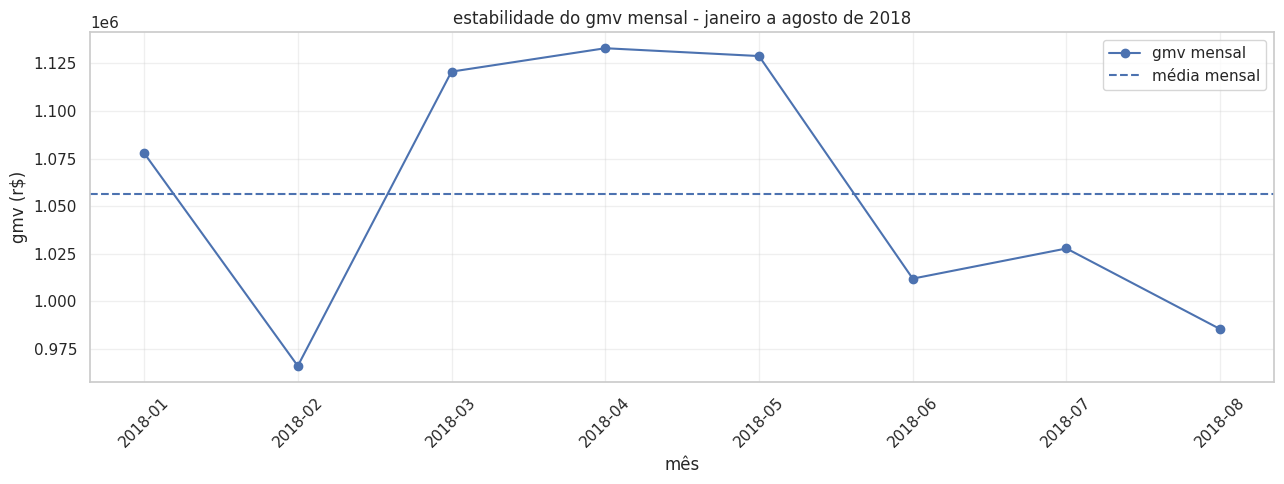

In [67]:
# criar o gráfico de gmv e sua média mensal
plt.figure(figsize=(13, 5))

plt.plot(
    gmv_2018.index.astype(str),
    gmv_2018["gmv"],
    marker="o",
    label="gmv mensal"
)

plt.axhline(
    gmv_2018["gmv"].mean(),
    linestyle="--",
    label="média mensal"
)

plt.title("estabilidade do gmv mensal - janeiro a agosto de 2018")
plt.xlabel("mês")
plt.ylabel("gmv (r$)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [68]:
# selecionar pedidos entregues entre outubro e dezembro de 2017
pedidos_periodo = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_purchase_timestamp"] >= "2017-10-01") &
    (orders["order_purchase_timestamp"] < "2018-01-01")
].copy()

# criar a identificação do mês
pedidos_periodo["mes"] = (
    pedidos_periodo["order_purchase_timestamp"]
    .dt.strftime("%Y-%m")
)

# adicionar o estado do cliente
pedidos_estado = pedidos_periodo.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

# adicionar os itens e valores dos pedidos
base_estado = pedidos_estado.merge(
    order_items[["order_id", "price", "freight_value"]],
    on="order_id",
    how="inner"
)

# calcular o valor transacionado
base_estado["gmv"] = (
    base_estado["price"] + base_estado["freight_value"]
)

# conferir a base criada
display(base_estado.head())
print("Total de registros:", len(base_estado))
print("Estados encontrados:", base_estado["customer_state"].nunique())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,mes,customer_state,price,freight_value,gmv
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017-10,SP,29.99,8.72,38.71
1,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017-11,RN,45.00,27.20,72.20
2,116f0b09343b49556bbad5f35bee0cdf,3187789bec990987628d7a9beb4dd6ac,delivered,2017-12-26 23:41:31,2017-12-26 23:50:22,2017-12-28 18:33:05,2018-01-08 22:36:36,2018-01-29,2017-12,SC,27.99,15.10,43.09
3,85ce859fd6dc634de8d2f1e290444043,059f7fc5719c7da6cbafe370971a8d70,delivered,2017-11-21 00:03:41,2017-11-21 00:14:22,2017-11-23 21:32:26,2017-11-27 18:28:00,2017-12-11,2017-11,SP,17.90,11.85,29.75
4,83018ec114eee8641c97e08f7b4e926f,7f8c8b9c2ae27bf3300f670c3d478be8,delivered,2017-10-26 15:54:26,2017-10-26 16:08:14,2017-10-26 21:46:53,2017-11-08 22:22:00,2017-11-23,2017-10,BA,76.00,16.97,92.97


Total de registros: 19876
Estados encontrados: 27


In [69]:
# agrupar o gmv por estado e mês
gmv_estado = base_estado.groupby(
    ["customer_state", "mes"]
).agg(
    pedidos=("order_id", "nunique"),
    gmv=("gmv", "sum")
).reset_index()

# separar o gmv mensal em colunas
gmv_estado_pivot = gmv_estado.pivot(
    index="customer_state",
    columns="mes",
    values="gmv"
).fillna(0)

# garantir a presença dos três meses
gmv_estado_pivot = gmv_estado_pivot.reindex(
    columns=["2017-10", "2017-11", "2017-12"],
    fill_value=0
)

# calcular o crescimento de outubro para novembro
gmv_estado_pivot["crescimento_pct"] = np.where(
    gmv_estado_pivot["2017-10"] > 0,
    (
        gmv_estado_pivot["2017-11"] /
        gmv_estado_pivot["2017-10"] - 1
    ) * 100,
    np.nan
)

# calcular o crescimento absoluto em reais
gmv_estado_pivot["crescimento_reais"] = (
    gmv_estado_pivot["2017-11"] -
    gmv_estado_pivot["2017-10"]
)

# calcular a participação de cada estado no gmv de novembro
gmv_estado_pivot["participacao_novembro_pct"] = (
    gmv_estado_pivot["2017-11"] /
    gmv_estado_pivot["2017-11"].sum()
) * 100

# ordenar pelos estados com maior gmv em novembro
gmv_estado_pivot = gmv_estado_pivot.sort_values(
    "2017-11",
    ascending=False
)

display(gmv_estado_pivot.round(2))

mes,2017-10,2017-11,2017-12,crescimento_pct,crescimento_reais,participacao_novembro_pct
customer_state,,,,,,
SP,"249,900.80","401,000.87","313,102.51",60.46,"151,100.07",34.77
RJ,"110,577.96","172,197.82","130,017.21",55.73,"61,619.86",14.93
MG,"93,049.17","154,129.38","105,453.80",65.64,"61,080.21",13.36
RS,"43,173.07","67,262.73","48,693.42",55.80,"24,089.66",5.83
PR,"37,404.60","54,237.97","35,094.41",45.00,"16,833.37",4.70
SC,"24,773.76","44,267.72","28,370.06",78.69,"19,493.96",3.84
BA,"27,614.20","35,449.55","32,914.95",28.37,"7,835.35",3.07
DF,"14,731.50","30,196.03","19,766.65",104.98,"15,464.53",2.62
ES,"12,667.55","28,402.83","14,250.56",124.22,"15,735.28",2.46


In [70]:
# consolidar pedidos e valores por estado e mês
indicadores_estado = base_estado.groupby(
    ["customer_state", "mes"]
).agg(
    pedidos=("order_id", "nunique"),
    gmv=("gmv", "sum")
).reset_index()

# calcular o ticket médio por estado e mês
indicadores_estado["ticket_medio"] = (
    indicadores_estado["gmv"] /
    indicadores_estado["pedidos"]
)

# conferir os indicadores
display(indicadores_estado.head(10))

,customer_state,mes,pedidos,gmv,ticket_medio
0,AC,2017-10,5,863.80,172.76
1,AC,2017-11,5,945.16,189.03
2,AC,2017-12,5,"1,409.58",281.92
3,AL,2017-10,28,"6,341.58",226.48
4,AL,2017-11,26,"7,441.47",286.21
5,AL,2017-12,12,"2,680.76",223.40
6,AM,2017-10,3,164.56,54.85
7,AM,2017-11,10,"3,001.01",300.10
8,AM,2017-12,6,"1,173.62",195.60
9,AP,2017-10,3,"1,696.74",565.58


In [71]:
# criar uma tabela dinâmica para cada indicador
pedidos_pivot = indicadores_estado.pivot(
    index="customer_state",
    columns="mes",
    values="pedidos"
).fillna(0)

gmv_pivot = indicadores_estado.pivot(
    index="customer_state",
    columns="mes",
    values="gmv"
).fillna(0)

ticket_pivot = indicadores_estado.pivot(
    index="customer_state",
    columns="mes",
    values="ticket_medio"
)

# criar uma tabela consolidada
comparacao_estado = pd.DataFrame(index=gmv_pivot.index)

# adicionar os indicadores de outubro, novembro e dezembro
for mes in ["2017-10", "2017-11", "2017-12"]:
    comparacao_estado[f"pedidos_{mes}"] = pedidos_pivot[mes]
    comparacao_estado[f"gmv_{mes}"] = gmv_pivot[mes]
    comparacao_estado[f"ticket_{mes}"] = ticket_pivot[mes]

# calcular o crescimento de pedidos de outubro para novembro
comparacao_estado["crescimento_pedidos_pct"] = (
    comparacao_estado["pedidos_2017-11"] /
    comparacao_estado["pedidos_2017-10"] - 1
) * 100

# calcular o crescimento do gmv de outubro para novembro
comparacao_estado["crescimento_gmv_pct"] = (
    comparacao_estado["gmv_2017-11"] /
    comparacao_estado["gmv_2017-10"] - 1
) * 100

# calcular a variação do ticket médio
comparacao_estado["crescimento_ticket_pct"] = (
    comparacao_estado["ticket_2017-11"] /
    comparacao_estado["ticket_2017-10"] - 1
) * 100

# ordenar pelos estados com maior gmv em novembro
comparacao_estado = comparacao_estado.sort_values(
    "gmv_2017-11",
    ascending=False
)

display(comparacao_estado.round(2))

,pedidos_2017-10,gmv_2017-10,ticket_2017-10,pedidos_2017-11,gmv_2017-11,ticket_2017-11,pedidos_2017-12,gmv_2017-12,ticket_2017-12,crescimento_pedidos_pct,crescimento_gmv_pct,crescimento_ticket_pct
customer_state,,,,,,,,,,,,
SP,"1,723.00","249,900.80",145.04,"2,899.00","401,000.87",138.32,"2,295.00","313,102.51",136.43,68.25,60.46,-4.63
RJ,654.00,"110,577.96",169.08,"1,012.00","172,197.82",170.16,746.00,"130,017.21",174.29,54.74,55.73,0.64
MG,542.00,"93,049.17",171.68,922.00,"154,129.38",167.17,669.00,"105,453.80",157.63,70.11,65.64,-2.63
RS,244.00,"43,173.07",176.94,409.00,"67,262.73",164.46,278.00,"48,693.42",175.16,67.62,55.80,-7.05
PR,198.00,"37,404.60",188.91,365.00,"54,237.97",148.60,260.00,"35,094.41",134.98,84.34,45.00,-21.34
SC,174.00,"24,773.76",142.38,288.00,"44,267.72",153.71,192.00,"28,370.06",147.76,65.52,78.69,7.96
BA,158.00,"27,614.20",174.77,243.00,"35,449.55",145.88,188.00,"32,914.95",175.08,53.80,28.37,-16.53
DF,92.00,"14,731.50",160.12,157.00,"30,196.03",192.33,129.00,"19,766.65",153.23,70.65,104.98,20.11
ES,100.00,"12,667.55",126.68,168.00,"28,402.83",169.06,108.00,"14,250.56",131.95,68.00,124.22,33.46


In [72]:
# selecionar pedidos entregues de outubro a dezembro de 2017
pedidos_clientes = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_purchase_timestamp"] >= "2017-10-01") &
    (orders["order_purchase_timestamp"] < "2018-01-01")
].copy()

# adicionar o identificador único do cliente
pedidos_clientes = pedidos_clientes.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

# identificar o mês da compra
pedidos_clientes["mes"] = (
    pedidos_clientes["order_purchase_timestamp"]
    .dt.to_period("M")
)

# contar pedidos por cliente em cada mês
compras_por_cliente = pedidos_clientes.groupby(
    ["mes", "customer_unique_id"]
).agg(
    quantidade_pedidos=("order_id", "nunique")
).reset_index()

# consolidar os indicadores mensais
analise_clientes = compras_por_cliente.groupby("mes").agg(
    clientes_unicos=("customer_unique_id", "nunique"),
    pedidos=("quantidade_pedidos", "sum"),
    clientes_com_mais_de_um_pedido=(
        "quantidade_pedidos",
        lambda x: (x > 1).sum()
    ),
    pedidos_de_clientes_recorrentes=(
        "quantidade_pedidos",
        lambda x: x[x > 1].sum()
    )
)

# calcular indicadores complementares
analise_clientes["pedidos_por_cliente"] = (
    analise_clientes["pedidos"] /
    analise_clientes["clientes_unicos"]
)

analise_clientes["percentual_clientes_recorrentes"] = (
    analise_clientes["clientes_com_mais_de_um_pedido"] /
    analise_clientes["clientes_unicos"] * 100
)

analise_clientes

,clientes_unicos,pedidos,clientes_com_mais_de_um_pedido,pedidos_de_clientes_recorrentes,pedidos_por_cliente,percentual_clientes_recorrentes
mes,,,,,,
2017-10,4417,4478,60,121,1.01,1.36
2017-11,7183,7289,101,207,1.01,1.41
2017-12,5450,5513,59,122,1.01,1.08


In [73]:
# selecionar pedidos entregues dentro do período analisado
base_clientes = orders_analise[
    orders_analise["order_status"] == "delivered"
].merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

# identificar a primeira compra observada de cada cliente
primeira_compra = (
    base_clientes.groupby("customer_unique_id")[
        "order_purchase_timestamp"
    ].min()
)

# adicionar a data da primeira compra à base
base_clientes["primeira_compra"] = (
    base_clientes["customer_unique_id"].map(primeira_compra)
)

# identificar o mês da compra e o mês da primeira compra
base_clientes["mes"] = (
    base_clientes["order_purchase_timestamp"].dt.to_period("M")
)

base_clientes["mes_primeira_compra"] = (
    base_clientes["primeira_compra"].dt.to_period("M")
)

# classificar clientes novos e recorrentes
base_clientes["tipo_cliente"] = np.where(
    base_clientes["mes"] == base_clientes["mes_primeira_compra"],
    "Novo",
    "Recorrente"
)

# consolidar os indicadores mensais
analise_aquisicao = base_clientes.groupby("mes").agg(
    clientes_unicos=("customer_unique_id", "nunique")
)

clientes_tipo = base_clientes.groupby(
    ["mes", "tipo_cliente"]
)["customer_unique_id"].nunique().unstack(fill_value=0)

analise_aquisicao = analise_aquisicao.join(clientes_tipo)

analise_aquisicao["percentual_novos"] = (
    analise_aquisicao["Novo"] /
    analise_aquisicao["clientes_unicos"] * 100
)

analise_aquisicao["percentual_recorrentes"] = (
    analise_aquisicao["Recorrente"] /
    analise_aquisicao["clientes_unicos"] * 100
)

analise_aquisicao.loc["2017-10":"2017-12"]

,clientes_unicos,Novo,Recorrente,percentual_novos,percentual_recorrentes
mes,,,,,
2017-10,4417,4328,89,97.99,2.01
2017-11,7183,7060,123,98.29,1.71
2017-12,5450,5338,112,97.94,2.06


In [74]:
# identificar os clientes cuja primeira compra entregue observada foi em novembro de 2017
coorte_novembro = base_clientes[
    base_clientes["mes_primeira_compra"] == pd.Period("2017-11")
]["customer_unique_id"].unique()

# selecionar todas as compras entregues desses clientes
compras_coorte = base_clientes[
    base_clientes["customer_unique_id"].isin(coorte_novembro)
].copy()

# contar clientes que voltaram a comprar em cada mês
retencao_novembro = compras_coorte.groupby("mes").agg(
    clientes_ativos=("customer_unique_id", "nunique"),
    pedidos=("order_id", "nunique")
)

# calcular percentual de clientes ativos em relação à coorte inicial
retencao_novembro["retencao_pct"] = (
    retencao_novembro["clientes_ativos"] /
    len(coorte_novembro) * 100
)

retencao_novembro.loc["2017-11":"2018-08"]

,clientes_ativos,pedidos,retencao_pct
mes,,,
2017-11,7060,7160,100.00
2017-12,40,42,0.57
2018-01,26,27,0.37
2018-02,12,12,0.17
2018-03,12,12,0.17
2018-04,13,14,0.18
2018-05,8,9,0.11
2018-06,13,13,0.18
2018-07,9,9,0.13


In [75]:
# identificar clientes da coorte que compraram depois de novembro
clientes_retorno = compras_coorte[
    compras_coorte["mes"] > pd.Period("2017-11")
]["customer_unique_id"].nunique()

# calcular indicadores de retorno
resumo_retorno = pd.DataFrame({
    "clientes_iniciais": [len(coorte_novembro)],
    "clientes_que_retornaram": [clientes_retorno],
    "clientes_sem_retorno": [
        len(coorte_novembro) - clientes_retorno
    ]
})

resumo_retorno["taxa_retorno_pct"] = (
    resumo_retorno["clientes_que_retornaram"] /
    resumo_retorno["clientes_iniciais"] * 100
)

resumo_retorno

,clientes_iniciais,clientes_que_retornaram,clientes_sem_retorno,taxa_retorno_pct
0,7060,133,6927,1.88


In [76]:
# definir os meses de entrada das coortes
meses_coorte = [
    pd.Period("2017-10"),
    pd.Period("2017-11"),
    pd.Period("2017-12")
]

resultados_coortes = []

for mes in meses_coorte:

    # identificar clientes novos no mês
    clientes = base_clientes[
        base_clientes["mes_primeira_compra"] == mes
    ]["customer_unique_id"].unique()

    # identificar clientes que voltaram depois da primeira compra
    retornaram = base_clientes[
        (base_clientes["customer_unique_id"].isin(clientes)) &
        (base_clientes["mes"] > mes)
    ]["customer_unique_id"].nunique()

    resultados_coortes.append({
        "coorte": str(mes),
        "clientes_iniciais": len(clientes),
        "clientes_que_retornaram": retornaram,
        "taxa_retorno_pct": retornaram / len(clientes) * 100
    })

comparacao_coortes = pd.DataFrame(resultados_coortes)

comparacao_coortes

,coorte,clientes_iniciais,clientes_que_retornaram,taxa_retorno_pct
0,2017-10,4328,108,2.50
1,2017-11,7060,133,1.88
2,2017-12,5338,87,1.63


In [77]:
import os
import zipfile

# localizar o arquivo zip enviado
arquivos = [
    arquivo for arquivo in os.listdir("/content")
    if arquivo.endswith(".zip")
]

print(arquivos)

['archive (1).zip', 'archive (2).zip', 'archive.zip']


In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile

from google.colab import files

# fazer upload do arquivo zip
arquivo = files.upload()

Saving archive.zip to archive (3).zip


In [79]:
# identificar o nome do arquivo enviado
nome_zip = list(arquivo.keys())[0]

# criar a pasta de destino
pasta = "/content/olist"
os.makedirs(pasta, exist_ok=True)

# extrair os arquivos
with zipfile.ZipFile(nome_zip, "r") as zip_ref:
    zip_ref.extractall(pasta)

print("arquivos extraídos com sucesso!")

arquivos extraídos com sucesso!


In [80]:
# listar os arquivos extraídos
os.listdir(pasta)

['product_category_name_translation.csv',
 'olist_order_reviews_dataset.csv',
 'olist_orders_dataset.csv',
 'olist_geolocation_dataset.csv',
 'olist_products_dataset.csv',
 'olist_sellers_dataset.csv',
 'olist_order_payments_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_customers_dataset.csv']

In [81]:
# carregar as tabelas do dataset

orders = pd.read_csv(f"{pasta}/olist_orders_dataset.csv")
order_items = pd.read_csv(f"{pasta}/olist_order_items_dataset.csv")
payments = pd.read_csv(f"{pasta}/olist_order_payments_dataset.csv")
sellers = pd.read_csv(f"{pasta}/olist_sellers_dataset.csv")
customers = pd.read_csv(f"{pasta}/olist_customers_dataset.csv")
reviews = pd.read_csv(f"{pasta}/olist_order_reviews_dataset.csv")
products = pd.read_csv(f"{pasta}/olist_products_dataset.csv")
geolocation = pd.read_csv(f"{pasta}/olist_geolocation_dataset.csv")
category_translation = pd.read_csv(f"{pasta}/product_category_name_translation.csv")

# organizar as tabelas em um dicionário
tabelas = {
    "Pedidos": orders,
    "Itens dos pedidos": order_items,
    "Pagamentos": payments,
    "Vendedores": sellers,
    "Clientes": customers,
    "Avaliações": reviews,
    "Produtos": products,
    "Geolocalização": geolocation,
    "Tradução de categorias": category_translation
}

# conferir dimensões
for nome, tabela in tabelas.items():
    print(nome, tabela.shape)

Pedidos (99441, 8)
Itens dos pedidos (112650, 7)
Pagamentos (103886, 5)
Vendedores (3095, 4)
Clientes (99441, 5)
Avaliações (99224, 7)
Produtos (32951, 9)
Geolocalização (1000163, 5)
Tradução de categorias (71, 2)


In [82]:
# converter as colunas de data
colunas_datas = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for coluna in colunas_datas:
    orders[coluna] = pd.to_datetime(
        orders[coluna],
        errors="coerce"
    )

# criar a identificação do mês
orders["mes"] = (
    orders["order_purchase_timestamp"].dt.to_period("M")
)

# definir o período da análise
data_inicio = "2016-09-01"
data_fim = "2018-09-01"

orders_analise = orders[
    (orders["order_purchase_timestamp"] >= data_inicio) &
    (orders["order_purchase_timestamp"] < data_fim)
].copy()

print("total de pedidos:", len(orders_analise))
print("primeiro pedido:", orders_analise["order_purchase_timestamp"].min())
print("último pedido:", orders_analise["order_purchase_timestamp"].max())

total de pedidos: 99421
primeiro pedido: 2016-09-04 21:15:19
último pedido: 2018-08-31 16:13:44


In [83]:
# selecionar pedidos entregues e adicionar o identificador único do cliente
base_clientes = orders_analise[
    orders_analise["order_status"] == "delivered"
].merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

# identificar a primeira compra entregue observada de cada cliente
primeira_compra = (
    base_clientes.groupby("customer_unique_id")[
        "order_purchase_timestamp"
    ].min()
)

base_clientes["primeira_compra"] = (
    base_clientes["customer_unique_id"].map(primeira_compra)
)

# identificar o mês da compra e o mês da primeira compra
base_clientes["mes"] = (
    base_clientes["order_purchase_timestamp"].dt.to_period("M")
)

base_clientes["mes_primeira_compra"] = (
    base_clientes["primeira_compra"].dt.to_period("M")
)

print("total de pedidos entregues:", len(base_clientes))
print("clientes únicos:", base_clientes["customer_unique_id"].nunique())

total de pedidos entregues: 96478
clientes únicos: 93358


In [84]:
# definir as coortes que serão comparadas
meses_coorte = [
    pd.Period("2017-10"),
    pd.Period("2017-11"),
    pd.Period("2017-12")
]

# comparar a recompra nos três meses seguintes
resultados = []

for mes in meses_coorte:

    clientes = base_clientes[
        base_clientes["mes_primeira_compra"] == mes
    ]["customer_unique_id"].unique()

    fim = mes + 3

    retornaram = base_clientes[
        (base_clientes["customer_unique_id"].isin(clientes)) &
        (base_clientes["mes"] > mes) &
        (base_clientes["mes"] <= fim)
    ]["customer_unique_id"].nunique()

    resultados.append({
        "coorte": str(mes),
        "clientes_iniciais": len(clientes),
        "clientes_que_retornaram_3m": retornaram,
        "taxa_retorno_3m_pct": round(
            retornaram / len(clientes) * 100, 2
        )
    })

comparacao_3m = pd.DataFrame(resultados)

comparacao_3m

,coorte,clientes_iniciais,clientes_que_retornaram_3m,taxa_retorno_3m_pct
0,2017-10,4328,46,1.06
1,2017-11,7060,76,1.08
2,2017-12,5338,44,0.82


In [85]:
# calcular o valor total por pedido
itens_por_pedido = (
    order_items.groupby("order_id")
    .agg(
        valor_produtos=("price", "sum"),
        frete=("freight_value", "sum")
    )
    .reset_index()
)

itens_por_pedido["gmv"] = (
    itens_por_pedido["valor_produtos"] +
    itens_por_pedido["frete"]
)

# relacionar pedidos entregues aos clientes e ao gmv
base_estados = (
    orders_analise[
        orders_analise["order_status"] == "delivered"
    ]
    .merge(
        customers[
            ["customer_id", "customer_unique_id", "customer_state"]
        ],
        on="customer_id",
        how="left"
    )
    .merge(
        itens_por_pedido[["order_id", "gmv"]],
        on="order_id",
        how="left"
    )
)

# consolidar os indicadores por estado
resumo_estados = (
    base_estados.groupby("customer_state")
    .agg(
        pedidos=("order_id", "nunique"),
        clientes=("customer_unique_id", "nunique"),
        gmv=("gmv", "sum")
    )
    .reset_index()
)

# calcular participação no gmv total
resumo_estados["participacao_gmv"] = (
    resumo_estados["gmv"] /
    resumo_estados["gmv"].sum() * 100
)

# calcular ticket médio por pedido
resumo_estados["ticket_medio"] = (
    resumo_estados["gmv"] /
    resumo_estados["pedidos"]
)

# ordenar do maior para o menor gmv
resumo_estados = resumo_estados.sort_values(
    "gmv",
    ascending=False
)

display(
    resumo_estados.round(2)
)

,customer_state,pedidos,clientes,gmv,participacao_gmv,ticket_medio
25,SP,40501,39156,"5,769,703.15",37.42,142.46
18,RJ,12350,11917,"2,055,401.57",13.33,166.43
10,MG,11354,11001,"1,818,891.67",11.80,160.20
22,RS,5345,5168,"861,472.79",5.59,161.17
17,PR,4923,4769,"781,708.80",5.07,158.79
23,SC,3546,3449,"595,127.78",3.86,167.83
4,BA,3256,3158,"591,137.81",3.83,181.55
6,DF,2080,2019,"346,123.35",2.24,166.41
8,GO,1957,1895,"334,212.35",2.17,170.78
7,ES,1995,1928,"317,657.93",2.06,159.23


In [86]:
# criar a coluna de ano e mês
base_estados["ano"] = (
    base_estados["order_purchase_timestamp"].dt.year
)

base_estados["mes_num"] = (
    base_estados["order_purchase_timestamp"].dt.month
)

# selecionar janeiro a agosto de 2017 e 2018
comparacao = base_estados[
    base_estados["ano"].isin([2017, 2018]) &
    base_estados["mes_num"].between(1, 8)
].copy()

# consolidar indicadores por estado e ano
resumo_estado_ano = (
    comparacao.groupby(["customer_state", "ano"])
    .agg(
        pedidos=("order_id", "nunique"),
        clientes=("customer_unique_id", "nunique"),
        gmv=("gmv", "sum")
    )
    .reset_index()
)

# transformar os anos em colunas
tabela_comparacao = resumo_estado_ano.pivot(
    index="customer_state",
    columns="ano",
    values=["pedidos", "clientes", "gmv"]
).fillna(0)

# calcular crescimento entre os períodos
for indicador in ["pedidos", "clientes", "gmv"]:
    tabela_comparacao[(indicador, "crescimento_pct")] = (
        tabela_comparacao[(indicador, 2018)] /
        tabela_comparacao[(indicador, 2017)].replace(0, np.nan) - 1
    ) * 100

# ordenar pelo gmv de 2018
tabela_comparacao = tabela_comparacao.sort_values(
    ("gmv", 2018),
    ascending=False
)

display(tabela_comparacao.round(2))

pedidos           clientes                    gmv  \
ano                2017      2018     2017      2018         2017   
customer_state                                                      
SP             8,578.00 23,335.00 8,340.00 22,795.00 1,225,231.48   
RJ             2,965.00  6,342.00 2,891.00  6,185.00   493,452.91   
MG             2,614.00  6,079.00 2,552.00  5,951.00   389,585.11   
RS             1,387.00  2,737.00 1,344.00  2,675.00   208,714.56   
PR             1,193.00  2,711.00 1,151.00  2,656.00   184,796.83   
SC               846.00  1,884.00   830.00  1,849.00   133,583.20   
BA               771.00  1,726.00   752.00  1,686.00   145,429.79   
DF               409.00  1,193.00   399.00  1,163.00    71,601.54   
ES               476.00  1,047.00   459.00  1,026.00    69,139.69   
GO               449.00  1,033.00   437.00  1,011.00    79,164.44   
PE               358.00    852.00   348.00    841.00    63,123.61   
CE               321.00    633.00   316.00    627.00    63,955.92   
PA               269.00    453.00   262.00    446.00    63,309.70   
MT               203.00    476.00   195.00    462.00    43,836.74   
PB               130.00    269.00   127.00    262.00    30,076.15   
MS               147.00    411.00   139.00    405.00    34,037.05   
MA               185.00    346.00   183.00    342.00    30,122.45   
PI               118.00    258.00   117.00    253.00    27,577.77   
RN               112.00    241.00   112.00    238.00    20,214.12   
AL               113.00    198.00   110.00    194.00    29,314.94   
SE               102.00    146.00   100.00    145.00    18,029.33   
TO                70.00    144.00    69.00    143.00    15,546.64   
RO                77.00    109.00    75.00    107.00    13,614.07   
AM                45.00     72.00    42.00     72.00     6,976.30   
AP                15.00     39.00    15.00     39.00     3,554.85   
RR                12.00     22.00    12.00     21.00     1,264.60   
AC                33.00     27.00    31.00     27.00     7,644.46   

                                    pedidos        clientes             gmv  
ano                    2018 crescimento_pct crescimento_pct crescimento_pct  
customer_state                                                               
SP             3,327,997.14          172.03          173.32          171.62  
RJ             1,033,414.59          113.90          113.94          109.43  
MG               988,893.32          132.56          133.19          153.83  
RS               447,497.30           97.33           99.03          114.41  
PR               442,913.37          127.24          130.76          139.68  
SC               332,482.25          122.70          122.77          148.90  
BA               321,426.99          123.87          124.20          121.02  
DF               193,264.59          191.69          191.48          169.92  
ES               178,891.30          119.96          123.53          158.74  
GO               176,175.74          130.07          131.35          122.54  
PE               165,285.81          137.99          141.67          161.84  
CE               132,201.31           97.20           98.42          106.71  
PA               104,222.30           68.40           70.23           64.62  
MT                92,314.12          134.48          136.92          110.59  
PB                77,155.43          106.92          106.30          156.53  
MS                74,470.84          179.59          191.37          118.79  
MA                73,415.24           87.03           86.89          143.72  
PI                61,511.25          118.64          116.24          123.05  
RN                56,408.91          115.18          112.50          179.06  
AL                43,223.36           75.22           76.36           47.44  
SE                32,583.79           43.14           45.00           80.73  
TO                31,851.86          105.71          107.25          104.

In [87]:
# relacionar os pedidos entregues com o estado dos clientes
base_recompra = base_clientes.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

# ordenar os pedidos por cliente e data
base_recompra = base_recompra.sort_values(
    "order_purchase_timestamp"
)

# identificar a primeira compra de cada cliente
primeira_compra_estado = (
    base_recompra.drop_duplicates(
        "customer_unique_id",
        keep="first"
    )[
        ["customer_unique_id", "customer_state"]
    ]
)

# contar pedidos entregues por cliente
pedidos_cliente = (
    base_recompra.groupby("customer_unique_id")
    .agg(
        total_pedidos=("order_id", "nunique")
    )
    .reset_index()
)

# identificar clientes que realizaram recompra
pedidos_cliente["recomprou"] = (
    pedidos_cliente["total_pedidos"] > 1
)

# relacionar o comportamento de compra ao estado inicial
base_recompra_estado = pedidos_cliente.merge(
    primeira_compra_estado,
    on="customer_unique_id",
    how="left"
)

# consolidar indicadores por estado
resumo_recompra_estado = (
    base_recompra_estado.groupby("customer_state")
    .agg(
        clientes=("customer_unique_id", "nunique"),
        clientes_recompra=("recomprou", "sum"),
        pedidos=("total_pedidos", "sum")
    )
    .reset_index()
)

# calcular clientes de compra única e taxa de recompra
resumo_recompra_estado["clientes_compra_unica"] = (
    resumo_recompra_estado["clientes"] -
    resumo_recompra_estado["clientes_recompra"]
)

resumo_recompra_estado["taxa_recompra_pct"] = (
    resumo_recompra_estado["clientes_recompra"] /
    resumo_recompra_estado["clientes"] * 100
)

# ordenar pelos estados com maior base de clientes
resumo_recompra_estado = (
    resumo_recompra_estado.sort_values(
        "clientes",
        ascending=False
    )
)

display(resumo_recompra_estado.round(2))

,customer_state,clientes,clientes_recompra,pedidos,clientes_compra_unica,taxa_recompra_pct
25,SP,39145,1219,40497,37926,3.11
18,RJ,11913,390,12349,11523,3.27
10,MG,10998,324,11357,10674,2.95
22,RS,5167,158,5345,5009,3.06
17,PR,4768,141,4925,4627,2.96
23,SC,3444,92,3543,3352,2.67
4,BA,3158,90,3258,3068,2.85
6,DF,2018,60,2082,1958,2.97
7,ES,1927,56,1994,1871,2.91
8,GO,1894,59,1959,1835,3.12


In [88]:
# verificar a estrutura da tabela de avaliações
print("dimensões:", reviews.shape)

# verificar a distribuição das notas
print("\ndistribuição das notas:")
print(reviews["review_score"].value_counts().sort_index())

# verificar quantas avaliações existem por pedido
avaliacoes_por_pedido = reviews["order_id"].value_counts()

print("\nquantidade de avaliações por pedido:")
print(avaliacoes_por_pedido.value_counts().sort_index())

# verificar pedidos com mais de uma avaliação
print(
    "\npedidos com mais de uma avaliação:",
    (avaliacoes_por_pedido > 1).sum()
)

# verificar percentual de pedidos com avaliação
print(
    "\npercentual de avaliações sobre os pedidos:",
    round(reviews["order_id"].nunique() / orders["order_id"].nunique() * 100, 2),
    "%"
)

dimensões: (99224, 7)

distribuição das notas:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

quantidade de avaliações por pedido:
count
1    98126
2      543
3        4
Name: count, dtype: int64

pedidos com mais de uma avaliação: 547

percentual de avaliações sobre os pedidos: 99.23 %


In [89]:
# identificar pedidos com mais de uma avaliação
pedidos_multiplas_avaliacoes = (
    reviews.groupby("order_id")
    .agg(
        quantidade_avaliacoes=("review_id", "nunique"),
        notas_diferentes=("review_score", "nunique"),
        nota_minima=("review_score", "min"),
        nota_maxima=("review_score", "max")
    )
    .query("quantidade_avaliacoes > 1")
    .reset_index()
)

# verificar se existem notas divergentes para o mesmo pedido
print("pedidos com notas diferentes:")
print(
    (pedidos_multiplas_avaliacoes["notas_diferentes"] > 1).sum()
)

# visualizar os pedidos com notas divergentes
display(
    pedidos_multiplas_avaliacoes[
        pedidos_multiplas_avaliacoes["notas_diferentes"] > 1
    ].head(10)
)

pedidos com notas diferentes:
202


,order_id,quantidade_avaliacoes,notas_diferentes,nota_minima,nota_maxima
1,013056cfe49763c6f66bda03396c5ee3,2,2,4,5
3,02355020fd0a40a0d56df9f6ff060413,2,2,1,3
4,029863af4b968de1e5d6a82782e662f5,2,2,4,5
8,03c939fd7fd3b38f8485a0f95798f1f6,3,2,3,4
9,03eba6d9fef8f5b3e811d4b5a7cca9cd,2,2,4,5
10,04f1827088d972a62224f5203a071500,2,2,1,5
11,0544030711e50ec2cb6c15764d22891a,2,2,1,4
14,059bbeb3477ed66fd7e670c3f879009a,2,2,2,5
17,073fa4be4665f397a289842b1053229c,2,2,1,5
19,075a544c5f4ed4bb75f82b160465fe76,2,2,1,3


In [90]:
# visualizar avaliações dos pedidos com notas divergentes
ids_divergentes = pedidos_multiplas_avaliacoes.loc[
    pedidos_multiplas_avaliacoes["notas_diferentes"] > 1,
    "order_id"
]

# selecionar os registros completos desses pedidos
avaliacoes_divergentes = reviews[
    reviews["order_id"].isin(ids_divergentes)
].copy()

# converter datas para o formato datetime
avaliacoes_divergentes["review_creation_date"] = pd.to_datetime(
    avaliacoes_divergentes["review_creation_date"],
    errors="coerce"
)

avaliacoes_divergentes["review_answer_timestamp"] = pd.to_datetime(
    avaliacoes_divergentes["review_answer_timestamp"],
    errors="coerce"
)

# ordenar e visualizar alguns exemplos
display(
    avaliacoes_divergentes.sort_values(
        ["order_id", "review_creation_date"]
    )[
        [
            "order_id",
            "review_id",
            "review_score",
            "review_creation_date",
            "review_answer_timestamp"
        ]
    ].head(20)
)

,order_id,review_id,review_score,review_creation_date,review_answer_timestamp
22779,013056cfe49763c6f66bda03396c5ee3,ab30810c29da5da8045216f0f62652a2,5,2018-02-22,2018-02-23 12:12:30
68633,013056cfe49763c6f66bda03396c5ee3,73413b847f63e02bc752b364f6d05ee9,4,2018-03-04,2018-03-05 17:02:00
89888,02355020fd0a40a0d56df9f6ff060413,0c8e7347f1cdd2aede37371543e3d163,3,2018-03-21,2018-03-22 01:32:08
17582,02355020fd0a40a0d56df9f6ff060413,017f0e1ea6386de662cbeba299c59ad1,1,2018-03-29,2018-03-30 03:16:19
37911,029863af4b968de1e5d6a82782e662f5,04d945e95c788a3aa1ffbee42105637b,5,2017-07-14,2017-07-17 13:58:06
55137,029863af4b968de1e5d6a82782e662f5,61fe4e7d1ae801bbe169eb67b86c6eda,4,2017-07-19,2017-07-20 12:06:11
69438,03c939fd7fd3b38f8485a0f95798f1f6,405eb2ea45e1dbe2662541ae5b47e2aa,3,2018-03-06,2018-03-06 19:50:32
8273,03c939fd7fd3b38f8485a0f95798f1f6,b04ed893318da5b863e878cd3d0511df,3,2018-03-20,2018-03-21 02:28:23
51527,03c939fd7fd3b38f8485a0f95798f1f6,f4bb9d6dd4fb6dcc2298f0e7b17b8e1e,4,2018-03-29,2018-03-30 00:29:09
88624,03eba6d9fef8f5b3e811d4b5a7cca9cd,36ce47fb903bec726f89c65eac26dc9f,4,2018-02-23,2018-02-23 23:55:53


In [91]:
# ordenar avaliações pela data de criação
reviews_ordenadas = reviews.sort_values(
    ["order_id", "review_creation_date", "review_answer_timestamp"]
)

# manter a primeira avaliação de cada pedido
reviews_unicas = (
    reviews_ordenadas
    .drop_duplicates(subset="order_id", keep="first")
    [["order_id", "review_score"]]
)

# conferir a consolidação
print("avaliações originais:", reviews.shape[0])
print("pedidos com avaliação:", reviews_unicas["order_id"].nunique())
print("notas ausentes:", reviews_unicas["review_score"].isna().sum())

display(
    reviews_unicas["review_score"]
    .value_counts()
    .sort_index()
)

avaliações originais: 99224
pedidos com avaliação: 98673
notas ausentes: 0


,count
review_score,
1,11343
2,3132
3,8121
4,19047
5,57030


In [92]:
# ordenar os pedidos entregues por cliente e data
base_ordenada = base_clientes.sort_values(
    ["customer_unique_id", "order_purchase_timestamp"]
)

# identificar a primeira compra entregue de cada cliente
primeiros_pedidos = (
    base_ordenada
    .drop_duplicates("customer_unique_id", keep="first")
    [["customer_unique_id", "order_id"]]
)

# contar os pedidos entregues de cada cliente
resumo_clientes = (
    base_clientes.groupby("customer_unique_id")
    .agg(total_pedidos=("order_id", "nunique"))
    .reset_index()
)

# identificar clientes que realizaram recompra
resumo_clientes["recomprou"] = (
    resumo_clientes["total_pedidos"] > 1
)

# associar a primeira compra ao histórico de recompra
analise_recompra = primeiros_pedidos.merge(
    resumo_clientes,
    on="customer_unique_id",
    how="left"
)

# associar a avaliação do primeiro pedido
analise_recompra = analise_recompra.merge(
    reviews_unicas,
    on="order_id",
    how="left"
)

# consolidar indicadores por nota
resumo_por_nota = (
    analise_recompra.groupby("review_score", dropna=False)
    .agg(
        clientes=("customer_unique_id", "nunique"),
        clientes_recompra=("recomprou", "sum")
    )
    .reset_index()
)

# calcular clientes sem recompra e taxa de recompra
resumo_por_nota["clientes_sem_recompra"] = (
    resumo_por_nota["clientes"] -
    resumo_por_nota["clientes_recompra"]
)

resumo_por_nota["taxa_recompra_pct"] = (
    resumo_por_nota["clientes_recompra"] /
    resumo_por_nota["clientes"] * 100
)

display(resumo_por_nota.round(2))

,review_score,clientes,clientes_recompra,clientes_sem_recompra,taxa_recompra_pct
0,1.00,9076,258,8818,2.84
1,2.00,2833,81,2752,2.86
2,3.00,7658,218,7440,2.85
3,4.00,18365,509,17856,2.77
4,5.00,54809,1712,53097,3.12
5,NaN,617,23,594,3.73


In [93]:
# identificar o primeiro pedido entregue de cada cliente
primeiros_pedidos = (
    base_clientes
    .sort_values("order_purchase_timestamp")
    .drop_duplicates("customer_unique_id", keep="first")
    [["customer_unique_id", "order_id", "customer_id"]]
)

# recuperar o estado do cliente no primeiro pedido
primeiros_pedidos = primeiros_pedidos.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

# relacionar os primeiros pedidos aos produtos
itens_primeira_compra = primeiros_pedidos.merge(
    order_items[["order_id", "product_id"]],
    on="order_id",
    how="left"
)

# relacionar os produtos às categorias
itens_primeira_compra = itens_primeira_compra.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# traduzir os nomes das categorias
itens_primeira_compra = itens_primeira_compra.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

# verificar a estrutura da base
print("linhas:", itens_primeira_compra.shape[0])
print(
    "clientes únicos:",
    itens_primeira_compra["customer_unique_id"].nunique()
)
print(
    "pedidos únicos:",
    itens_primeira_compra["order_id"].nunique()
)
print(
    "categorias identificadas:",
    itens_primeira_compra["product_category_name_english"].nunique()
)

# verificar categorias ausentes
print(
    "produtos sem categoria:",
    itens_primeira_compra["product_category_name"].isna().sum()
)

linhas: 106401
clientes únicos: 93358
pedidos únicos: 93358
categorias identificadas: 71
produtos sem categoria: 1492


In [94]:
# preencher categorias ausentes
itens_primeira_compra["categoria"] = (
    itens_primeira_compra["product_category_name_english"]
    .fillna("categoria não identificada")
)

# manter uma ocorrência por cliente e categoria
cliente_categoria = (
    itens_primeira_compra[
        ["customer_unique_id", "customer_state", "categoria"]
    ]
    .drop_duplicates()
)

# relacionar com o histórico de recompra
cliente_categoria = cliente_categoria.merge(
    resumo_clientes[
        ["customer_unique_id", "total_pedidos", "recomprou"]
    ],
    on="customer_unique_id",
    how="left"
)

# consolidar indicadores por categoria
recompra_categoria = (
    cliente_categoria.groupby("categoria")
    .agg(
        clientes=("customer_unique_id", "nunique"),
        clientes_recompra=("recomprou", "sum"),
        pedidos=("total_pedidos", "sum")
    )
    .reset_index()
)

# calcular taxa de recompra
recompra_categoria["taxa_recompra_pct"] = (
    recompra_categoria["clientes_recompra"] /
    recompra_categoria["clientes"] * 100
)

# ordenar pelas categorias com maior base de clientes
recompra_categoria = recompra_categoria.sort_values(
    "clientes",
    ascending=False
)

display(recompra_categoria.round(2))

,categoria,clientes,clientes_recompra,pedidos,taxa_recompra_pct
7,bed_bath_table,8824,394,9264,4.47
44,health_beauty,8390,228,8641,2.72
66,sports_leisure,7239,284,7564,3.92
16,computers_accessories,6315,180,6509,2.85
40,furniture_decor,6014,281,6311,4.67
...,...,...,...,...,...
3,arts_and_craftmanship,21,3,27,14.29
53,la_cuisine,13,2,17,15.38
12,cds_dvds_musicals,12,0,12,0.00
30,fashion_childrens_clothes,6,0,6,0.00


In [95]:
# consolidar recompra por estado e categoria
recompra_estado_categoria = (
    cliente_categoria.groupby(
        ["customer_state", "categoria"]
    )
    .agg(
        clientes=("customer_unique_id", "nunique"),
        clientes_recompra=("recomprou", "sum")
    )
    .reset_index()
)

# calcular taxa de recompra
recompra_estado_categoria["taxa_recompra_pct"] = (
    recompra_estado_categoria["clientes_recompra"] /
    recompra_estado_categoria["clientes"] * 100
)

# ordenar por estado e volume de clientes
recompra_estado_categoria = (
    recompra_estado_categoria.sort_values(
        ["customer_state", "clientes"],
        ascending=[True, False]
    )
)

display(recompra_estado_categoria.round(2))

,customer_state,categoria,clientes,clientes_recompra,taxa_recompra_pct
23,AC,sports_leisure,8,1,12.50
7,AC,computers_accessories,6,0,0.00
13,AC,furniture_decor,6,1,16.67
16,AC,health_beauty,6,0,0.00
25,AC,telephony,5,0,0.00
...,...,...,...,...,...
1356,TO,industry_commerce_and_business,1,0,0.00
1357,TO,kitchen_dining_laundry_garden_furniture,1,0,0.00
1359,TO,market_place,1,0,0.00
1360,TO,musical_instruments,1,0,0.00


In [96]:
# filtrar combinações com pelo menos 100 clientes
analise_estado_categoria = (
    recompra_estado_categoria[
        recompra_estado_categoria["clientes"] >= 100
    ].copy()
)

# visualizar as maiores taxas de recompra
maiores_taxas = analise_estado_categoria.sort_values(
    ["taxa_recompra_pct", "clientes"],
    ascending=[False, False]
)

print("combinações com pelo menos 100 clientes:")
print(analise_estado_categoria.shape[0])

print("\nmaiores taxas de recompra:")
display(maiores_taxas.head(20).round(2))

print("\nmenores taxas de recompra:")
display(
    analise_estado_categoria.sort_values(
        ["taxa_recompra_pct", "clientes"],
        ascending=[True, False]
    ).head(20).round(2)
)

combinações com pelo menos 100 clientes:
169

maiores taxas de recompra:


,customer_state,categoria,clientes,clientes_recompra,taxa_recompra_pct
1305,SP,home_appliances,308,28,9.09
945,RJ,fashion_bags_accessories,169,12,7.10
165,BA,furniture_decor,188,13,6.91
276,DF,furniture_decor,104,7,6.73
1289,SP,fashion_bags_accessories,709,45,6.35
186,BA,sports_leisure,238,15,6.30
1191,SC,furniture_decor,256,16,6.25
258,DF,computers_accessories,128,8,6.25
369,GO,bed_bath_table,178,11,6.18
299,DF,sports_leisure,183,11,6.01



menores taxas de recompra:


,customer_state,categoria,clientes,clientes_recompra,taxa_recompra_pct
425,GO,watches_gifts,137,0,0.00
244,CE,watches_gifts,126,0,0.00
912,PR,stationery,116,0,0.00
1270,SP,books_technical,106,0,0.00
499,MG,electronics,253,1,0.40
144,BA,computers_accessories,210,1,0.48
525,MG,luggage_accessories,174,1,0.57
1194,SC,garden_tools,143,1,0.70
1323,SP,small_appliances,267,2,0.75
916,PR,watches_gifts,264,2,0.76


In [97]:
# selecionar categorias de interesse
categorias_interesse = [
    "bed_bath_table",
    "furniture_decor",
    "sports_leisure",
    "health_beauty",
    "computers_accessories",
    "telephony",
    "fashion_bags_accessories"
]

# selecionar os principais estados
estados_interesse = ["SP", "RJ", "MG", "RS", "PR", "SC", "BA"]

# filtrar a base
comparacao_categorias = analise_estado_categoria[
    analise_estado_categoria["categoria"].isin(categorias_interesse) &
    analise_estado_categoria["customer_state"].isin(estados_interesse)
].copy()

# organizar a comparação
comparacao_categorias = comparacao_categorias.sort_values(
    ["categoria", "taxa_recompra_pct"],
    ascending=[True, False]
)

display(comparacao_categorias.round(2))

,customer_state,categoria,clientes,clientes_recompra,taxa_recompra_pct
480,MG,bed_bath_table,1066,56,5.25
1095,RS,bed_bath_table,507,25,4.93
923,RJ,bed_bath_table,1282,61,4.76
1162,SC,bed_bath_table,256,12,4.69
1267,SP,bed_bath_table,4153,170,4.09
858,PR,bed_bath_table,379,15,3.96
136,BA,bed_bath_table,204,5,2.45
866,PR,computers_accessories,319,14,4.39
932,RJ,computers_accessories,795,32,4.03
1104,RS,computers_accessories,375,11,2.93


In [98]:
# ordenar por quantidade de clientes que recompraram
oportunidades_recompra = analise_estado_categoria.sort_values(
    "clientes_recompra",
    ascending=False
)

# selecionar as 20 principais combinações
display(
    oportunidades_recompra[
        [
            "customer_state",
            "categoria",
            "clientes",
            "clientes_recompra",
            "taxa_recompra_pct"
        ]
    ].head(20).round(2)
)

,customer_state,categoria,clientes,clientes_recompra,taxa_recompra_pct
1267,SP,bed_bath_table,4153,170,4.09
1300,SP,furniture_decor,2536,124,4.89
1325,SP,sports_leisure,3080,118,3.83
1304,SP,health_beauty,3596,104,2.89
1310,SP,housewares,2632,76,2.89
1276,SP,computers_accessories,2519,70,2.78
923,RJ,bed_bath_table,1282,61,4.76
1330,SP,watches_gifts,2015,57,2.83
480,MG,bed_bath_table,1066,56,5.25
1289,SP,fashion_bags_accessories,709,45,6.35


In [99]:
print(itens_primeira_compra.columns.tolist())

['customer_unique_id', 'order_id', 'customer_id', 'customer_state', 'product_id', 'product_category_name', 'product_category_name_english', 'categoria']


In [100]:
print(order_items.columns.tolist())

['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']


In [101]:
# selecionar os valores financeiros dos itens
valores_itens = order_items[
    ["order_id", "product_id", "price", "freight_value"]
].copy()

# incorporar os valores financeiros à primeira compra
itens_primeira_compra_valores = itens_primeira_compra.merge(
    valores_itens,
    on=["order_id", "product_id"],
    how="left"
)

# conferir o resultado
display(
    itens_primeira_compra_valores[
        ["order_id", "categoria", "price", "freight_value"]
    ].head()
)

print("linhas:", len(itens_primeira_compra_valores))
print("valores financeiros ausentes:",
      itens_primeira_compra_valores["price"].isna().sum())

,order_id,categoria,price,freight_value
0,bfbd0f9bdef84302105ad712db648a6c,health_beauty,44.99,2.83
1,bfbd0f9bdef84302105ad712db648a6c,health_beauty,44.99,2.83
2,bfbd0f9bdef84302105ad712db648a6c,health_beauty,44.99,2.83
3,bfbd0f9bdef84302105ad712db648a6c,health_beauty,44.99,2.83
4,bfbd0f9bdef84302105ad712db648a6c,health_beauty,44.99,2.83


linhas: 136827
valores financeiros ausentes: 0


In [102]:
# verificar produtos repetidos por pedido nas duas bases
print(
    "duplicados na primeira compra:",
    itens_primeira_compra.duplicated(
        ["order_id", "product_id"]
    ).sum()
)

print(
    "duplicados em order_items:",
    order_items.duplicated(
        ["order_id", "product_id"]
    ).sum()
)

# verificar quantas linhas existem em cada base
print("primeira compra:", len(itens_primeira_compra))
print("order_items:", len(order_items))
print("base após cruzamento:", len(itens_primeira_compra_valores))

duplicados na primeira compra: 9549
duplicados em order_items: 10225
primeira compra: 106401
order_items: 112650
base após cruzamento: 136827


In [103]:
# identificar os pedidos da primeira compra
pedidos_primeira_compra = (
    itens_primeira_compra[["order_id"]]
    .drop_duplicates()
)

# recuperar a identificação dos clientes por pedido
clientes_primeira_compra = (
    itens_primeira_compra[
        ["order_id", "customer_unique_id", "customer_state"]
    ]
    .drop_duplicates(subset=["order_id"])
)

# recuperar a categoria de cada produto
categorias_produtos = (
    itens_primeira_compra[
        ["product_id", "categoria"]
    ]
    .drop_duplicates(subset=["product_id"])
)

# recuperar os itens originais dos pedidos
itens_primeira_compra_valores = (
    order_items
    .merge(pedidos_primeira_compra, on="order_id", how="inner")
    .merge(clientes_primeira_compra, on="order_id", how="left")
    .merge(categorias_produtos, on="product_id", how="left")
)

# conferir a reconstrução
print("linhas reconstruídas:", len(itens_primeira_compra_valores))
print("linhas originais da primeira compra:", len(itens_primeira_compra))
print("valores financeiros ausentes:",
      itens_primeira_compra_valores["price"].isna().sum())
print("clientes ausentes:",
      itens_primeira_compra_valores["customer_unique_id"].isna().sum())

linhas reconstruídas: 106401
linhas originais da primeira compra: 106401
valores financeiros ausentes: 0
clientes ausentes: 0


In [104]:
# calcular o valor total de cada item
itens_primeira_compra_valores["gmv"] = (
    itens_primeira_compra_valores["price"] +
    itens_primeira_compra_valores["freight_value"]
)

# consolidar os indicadores por categoria
gmv_categoria = (
    itens_primeira_compra_valores
    .groupby("categoria", as_index=False)
    .agg(
        clientes=("customer_unique_id", "nunique"),
        valor_produtos=("price", "sum"),
        valor_frete=("freight_value", "sum"),
        gmv=("gmv", "sum")
    )
)

# calcular ticket médio por cliente na categoria
gmv_categoria["ticket_medio"] = (
    gmv_categoria["gmv"] / gmv_categoria["clientes"]
)

# calcular participação no gmv total
gmv_categoria["participacao_gmv_pct"] = (
    gmv_categoria["gmv"] /
    gmv_categoria["gmv"].sum() * 100
)

# ordenar pelo maior gmv
gmv_categoria = gmv_categoria.sort_values(
    "gmv",
    ascending=False
)

display(gmv_categoria.round(2))

,categoria,clientes,valor_produtos,valor_frete,gmv,ticket_medio,participacao_gmv_pct
44,health_beauty,8390,"1,202,908.11","173,984.01","1,376,892.12",164.11,9.20
71,watches_gifts,5336,"1,136,210.17","95,292.37","1,231,502.54",230.79,8.23
7,bed_bath_table,8824,"972,333.13","191,247.76","1,163,580.89",131.87,7.78
66,sports_leisure,7239,"919,598.03","157,368.92","1,076,966.95",148.77,7.20
16,computers_accessories,6315,"855,119.67","138,781.46","993,901.13",157.39,6.64
...,...,...,...,...,...,...,...
36,flowers,29,"1,110.04",488.87,"1,598.91",55.13,0.01
47,home_comfort_2,23,747.37,395.21,"1,142.58",49.68,0.01
12,cds_dvds_musicals,12,730.00,224.99,954.99,79.58,0.01
30,fashion_childrens_clothes,6,479.96,72.29,552.25,92.04,0.00


In [105]:
# consolidar indicadores por estado e categoria
gmv_estado_categoria = (
    itens_primeira_compra_valores
    .groupby(["customer_state", "categoria"], as_index=False)
    .agg(
        clientes=("customer_unique_id", "nunique"),
        gmv=("gmv", "sum")
    )
)

# calcular ticket médio por cliente
gmv_estado_categoria["ticket_medio"] = (
    gmv_estado_categoria["gmv"] /
    gmv_estado_categoria["clientes"]
)

# selecionar os principais estados
estados_interesse = ["SP", "RJ", "MG", "RS", "PR", "SC", "BA"]

comparacao_gmv_estado = gmv_estado_categoria[
    gmv_estado_categoria["customer_state"].isin(estados_interesse)
].copy()

# ordenar pelo maior gmv
comparacao_gmv_estado = comparacao_gmv_estado.sort_values(
    "gmv",
    ascending=False
)

display(comparacao_gmv_estado.head(25).round(2))

,customer_state,categoria,clientes,gmv,ticket_medio
1267,SP,bed_bath_table,4153,"523,833.60",126.13
1304,SP,health_beauty,3596,"495,939.46",137.91
1330,SP,watches_gifts,2015,"434,414.66",215.59
1325,SP,sports_leisure,3080,"408,733.92",132.71
1276,SP,computers_accessories,2519,"369,460.11",146.67
1300,SP,furniture_decor,2536,"318,372.00",125.54
1310,SP,housewares,2632,"313,755.75",119.21
1265,SP,auto,1543,"226,750.53",146.95
1281,SP,cool_stuff,1267,"225,346.01",177.86
1329,SP,toys,1538,"200,168.01",130.15


In [106]:
print(orders_analise.columns.tolist())
print(customers.columns.tolist())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'mes']
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']


In [107]:
# selecionar pedidos entregues no período analisado
pedidos_entregues = orders_analise[
    orders_analise["order_status"] == "delivered"
].copy()

# incorporar os dados dos clientes
pedidos_entregues = pedidos_entregues.merge(
    customers[
        ["customer_id", "customer_unique_id", "customer_state"]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# incorporar todos os itens dos pedidos
base_gmv_completa = pedidos_entregues.merge(
    order_items,
    on="order_id",
    how="inner",
    validate="one_to_many"
)

# incorporar as categorias dos produtos
base_gmv_completa = base_gmv_completa.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# incorporar a tradução das categorias
base_gmv_completa = base_gmv_completa.merge(
    category_translation,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

# padronizar categorias não identificadas
base_gmv_completa["categoria"] = (
    base_gmv_completa["product_category_name_english"]
    .fillna("categoria não identificada")
)

# calcular o valor total dos itens
base_gmv_completa["gmv"] = (
    base_gmv_completa["price"] +
    base_gmv_completa["freight_value"]
)

# conferir a base
print("linhas:", len(base_gmv_completa))
print("pedidos:", base_gmv_completa["order_id"].nunique())
print("clientes:", base_gmv_completa["customer_unique_id"].nunique())
print("categorias:", base_gmv_completa["categoria"].nunique())
print("valores financeiros ausentes:", base_gmv_completa["gmv"].isna().sum())
print("clientes sem identificação:", base_gmv_completa["customer_unique_id"].isna().sum())

linhas: 110197
pedidos: 96478
clientes: 93358
categorias: 72
valores financeiros ausentes: 0
clientes sem identificação: 0


In [108]:
# consolidar indicadores por categoria
gmv_categoria_completo = (
    base_gmv_completa
    .groupby("categoria", as_index=False)
    .agg(
        pedidos=("order_id", "nunique"),
        clientes=("customer_unique_id", "nunique"),
        itens=("order_item_id", "count"),
        valor_produtos=("price", "sum"),
        valor_frete=("freight_value", "sum"),
        gmv=("gmv", "sum")
    )
)

# calcular ticket médio por pedido
gmv_categoria_completo["ticket_medio"] = (
    gmv_categoria_completo["gmv"] /
    gmv_categoria_completo["pedidos"]
)

# calcular participação no gmv total
gmv_total = gmv_categoria_completo["gmv"].sum()

gmv_categoria_completo["participacao_gmv_pct"] = (
    gmv_categoria_completo["gmv"] / gmv_total * 100
)

# ordenar pelas categorias de maior gmv
gmv_categoria_completo = gmv_categoria_completo.sort_values(
    "gmv",
    ascending=False
)

display(gmv_categoria_completo.round(2))

,categoria,pedidos,clientes,itens,valor_produtos,valor_frete,gmv,ticket_medio,participacao_gmv_pct
44,health_beauty,8647,8498,9465,"1,233,131.72","178,957.81","1,412,089.53",163.30,9.16
71,watches_gifts,5495,5421,5859,"1,166,176.98","98,156.14","1,264,333.12",230.09,8.20
7,bed_bath_table,9272,9008,10953,"1,023,434.76","201,774.50","1,225,209.26",132.14,7.95
66,sports_leisure,7530,7341,8431,"954,852.55","163,404.36","1,118,256.91",148.51,7.25
16,computers_accessories,6530,6405,7644,"888,724.61","143,999.16","1,032,723.77",158.15,6.70
...,...,...,...,...,...,...,...,...,...
36,flowers,29,29,33,"1,110.04",488.87,"1,598.91",55.13,0.01
47,home_comfort_2,24,23,30,760.27,410.31,"1,170.58",48.77,0.01
12,cds_dvds_musicals,12,12,14,730.00,224.99,954.99,79.58,0.01
30,fashion_childrens_clothes,7,7,7,519.95,78.72,598.67,85.52,0.00


In [109]:
# ordenar categorias por gmv
concentracao_categorias = gmv_categoria_completo.sort_values(
    "gmv",
    ascending=False
).copy()

# calcular participação acumulada
concentracao_categorias["participacao_acumulada_pct"] = (
    concentracao_categorias["participacao_gmv_pct"].cumsum()
)

# calcular concentração nas maiores categorias
for n in [5, 10, 20]:
    participacao = (
        concentracao_categorias
        .head(n)["participacao_gmv_pct"]
        .sum()
    )

    print(f"top {n} categorias: {participacao:.2f}% do gmv")

# mostrar as 20 maiores
display(
    concentracao_categorias[
        [
            "categoria",
            "gmv",
            "participacao_gmv_pct",
            "participacao_acumulada_pct"
        ]
    ].head(20).round(2)
)

top 5 categorias: 39.25% do gmv
top 10 categorias: 62.38% do gmv
top 20 categorias: 83.95% do gmv


,categoria,gmv,participacao_gmv_pct,participacao_acumulada_pct
44,health_beauty,"1,412,089.53",9.16,9.16
71,watches_gifts,"1,264,333.12",8.20,17.36
7,bed_bath_table,"1,225,209.26",7.95,25.30
66,sports_leisure,"1,118,256.91",7.25,32.55
16,computers_accessories,"1,032,723.77",6.70,39.25
40,furniture_decor,"880,329.92",5.71,44.96
50,housewares,"758,392.25",4.92,49.88
21,cool_stuff,"691,680.89",4.49,54.37
5,auto,"669,454.75",4.34,58.71
43,garden_tools,"567,145.68",3.68,62.38


In [110]:
# consolidar o gmv por estado e categoria
gmv_estado_categoria_completo = (
    base_gmv_completa
    .groupby(["customer_state", "categoria"], as_index=False)
    .agg(
        pedidos=("order_id", "nunique"),
        clientes=("customer_unique_id", "nunique"),
        gmv=("gmv", "sum")
    )
)

# calcular o gmv total de cada estado
gmv_por_estado = (
    gmv_estado_categoria_completo
    .groupby("customer_state")["gmv"]
    .transform("sum")
)

# calcular a participação da categoria dentro do estado
gmv_estado_categoria_completo["participacao_no_estado_pct"] = (
    gmv_estado_categoria_completo["gmv"] /
    gmv_por_estado * 100
)

# selecionar os principais estados
estados_interesse = ["SP", "RJ", "MG", "RS", "PR", "SC", "BA"]

comparacao_estado_categoria = (
    gmv_estado_categoria_completo[
        gmv_estado_categoria_completo["customer_state"].isin(
            estados_interesse
        )
    ]
    .sort_values(
        ["customer_state", "gmv"],
        ascending=[True, False]
    )
)

display(comparacao_estado_categoria.round(2))

,customer_state,categoria,pedidos,clientes,gmv,participacao_no_estado_pct
168,BA,health_beauty,319,313,"58,620.07",9.92
191,BA,watches_gifts,214,212,"50,254.70",8.50
186,BA,sports_leisure,250,242,"44,410.84",7.51
144,BA,computers_accessories,214,213,"38,502.91",6.51
134,BA,auto,145,144,"33,532.84",5.67
...,...,...,...,...,...,...
1320,SP,la_cuisine,5,5,872.48,0.02
1314,SP,home_comfort_2,11,11,624.56,0.01
1303,SP,flowers,10,10,558.12,0.01
1279,SP,cds_dvds_musicals,6,6,409.64,0.01


In [111]:
# calcular o gmv total de cada categoria no marketplace
gmv_total_categoria = (
    base_gmv_completa
    .groupby("categoria")["gmv"]
    .sum()
)

# calcular a participação de cada combinação no gmv nacional
comparacao_estado_categoria["participacao_nacional_pct"] = (
    comparacao_estado_categoria["gmv"] /
    base_gmv_completa["gmv"].sum() * 100
)

# selecionar as cinco maiores categorias de cada estado
top5_estado_categoria = (
    comparacao_estado_categoria
    .sort_values(
        ["customer_state", "gmv"],
        ascending=[True, False]
    )
    .groupby("customer_state")
    .head(5)
)

display(
    top5_estado_categoria[
        [
            "customer_state",
            "categoria",
            "pedidos",
            "clientes",
            "gmv",
            "participacao_no_estado_pct",
            "participacao_nacional_pct"
        ]
    ].round(2)
)

,customer_state,categoria,pedidos,clientes,gmv,participacao_no_estado_pct,participacao_nacional_pct
168,BA,health_beauty,319,313,"58,620.07",9.92,0.38
191,BA,watches_gifts,214,212,"50,254.70",8.50,0.33
186,BA,sports_leisure,250,242,"44,410.84",7.51,0.29
144,BA,computers_accessories,214,213,"38,502.91",6.51,0.25
134,BA,auto,145,144,"33,532.84",5.67,0.22
517,MG,health_beauty,990,975,"175,007.52",9.62,1.13
482,MG,bed_bath_table,1120,1085,"156,483.10",8.60,1.01
543,MG,watches_gifts,601,595,"132,311.65",7.27,0.86
538,MG,sports_leisure,850,825,"129,923.10",7.14,0.84
490,MG,computers_accessories,862,846,"127,121.59",6.99,0.82


In [112]:
# selecionar apenas janeiro a agosto de 2017 e 2018
base_comparacao = base_gmv_completa[
    (
        (base_gmv_completa["order_purchase_timestamp"].dt.year == 2017) |
        (base_gmv_completa["order_purchase_timestamp"].dt.year == 2018)
    ) &
    (base_gmv_completa["order_purchase_timestamp"].dt.month.between(1, 8))
].copy()

# criar a coluna do ano
base_comparacao["ano"] = (
    base_comparacao["order_purchase_timestamp"].dt.year
)

# validar o período e o volume
base_comparacao.groupby("ano").agg(
    pedidos=("order_id", "nunique"),
    clientes=("customer_unique_id", "nunique"),
    gmv=("gmv", "sum")
).reset_index()

,ano,pedidos,clientes,gmv
0,2017,21998,21404,"3,472,898.25"
1,2018,52783,51612,"8,451,584.77"


In [113]:
# consolidar gmv por estado, categoria e ano
gmv_estado_categoria_ano = (
    base_comparacao
    .groupby(["customer_state", "categoria", "ano"])
    .agg(
        pedidos=("order_id", "nunique"),
        gmv=("gmv", "sum")
    )
    .reset_index()
)

# separar os valores de cada ano
comparacao_estado_categoria = (
    gmv_estado_categoria_ano
    .pivot_table(
        index=["customer_state", "categoria"],
        columns="ano",
        values="gmv",
        fill_value=0
    )
    .reset_index()
)

# organizar os nomes das colunas
comparacao_estado_categoria.columns.name = None
comparacao_estado_categoria = comparacao_estado_categoria.rename(
    columns={
        2017: "gmv_2017",
        2018: "gmv_2018"
    }
)

# calcular crescimento absoluto e percentual
comparacao_estado_categoria["crescimento_absoluto"] = (
    comparacao_estado_categoria["gmv_2018"] -
    comparacao_estado_categoria["gmv_2017"]
)

comparacao_estado_categoria["crescimento_pct"] = (
    comparacao_estado_categoria["crescimento_absoluto"] /
    comparacao_estado_categoria["gmv_2017"].replace(0, np.nan)
) * 100

# ordenar pelas maiores contribuições absolutas
comparacao_estado_categoria = (
    comparacao_estado_categoria
    .sort_values("crescimento_absoluto", ascending=False)
)

comparacao_estado_categoria.head(20).round(2)

,customer_state,categoria,gmv_2017,gmv_2018,crescimento_absoluto,crescimento_pct
1251,SP,health_beauty,"81,654.80","335,872.16","254,217.36",311.33
1214,SP,bed_bath_table,"122,940.66","313,396.40","190,455.74",154.92
1277,SP,watches_gifts,"77,445.82","262,046.38","184,600.56",238.36
1223,SP,computers_accessories,"81,805.64","236,996.13","155,190.49",189.71
1272,SP,sports_leisure,"93,333.31","240,257.46","146,924.15",157.42
1257,SP,housewares,"62,456.23","208,767.20","146,310.97",234.26
1247,SP,furniture_decor,"84,861.45","176,525.76","91,664.31",108.02
1212,SP,auto,"53,959.80","141,191.27","87,231.47",161.66
1213,SP,baby,"27,119.35","112,019.44","84,900.09",313.06
486,MG,health_beauty,"31,648.92","112,512.86","80,863.94",255.50


In [114]:
# identificar as maiores retrações de gmv
maiores_retracoes = (
    comparacao_estado_categoria[
        comparacao_estado_categoria["gmv_2017"] > 0
    ]
    .sort_values("crescimento_absoluto")
    .head(20)
)

maiores_retracoes[
    [
        "customer_state",
        "categoria",
        "gmv_2017",
        "gmv_2018",
        "crescimento_absoluto",
        "crescimento_pct"
    ]
].round(2)

,customer_state,categoria,gmv_2017,gmv_2018,crescimento_absoluto,crescimento_pct
464,MG,cool_stuff,"30,724.81","23,895.12","-6,829.69",-22.23
279,DF,small_appliances,"8,285.34","2,166.05","-6,119.29",-73.86
548,MS,housewares,"8,347.76","3,266.31","-5,081.45",-60.87
359,GO,cool_stuff,"7,714.15","3,447.56","-4,266.59",-55.31
1051,RS,computers,"4,387.06",710.22,"-3,676.84",-83.81
691,PB,garden_tools,"4,201.22",569.38,"-3,631.84",-86.45
934,RJ,small_appliances,"15,322.02","11,969.30","-3,352.72",-21.88
240,DF,computers,"4,835.32","1,916.08","-2,919.24",-60.37
221,CE,small_appliances,"3,173.14",333.54,"-2,839.60",-89.49
626,PA,categoria não identificada,"5,098.37","2,328.26","-2,770.11",-54.33


In [115]:
# incorporar a localização dos sellers
base_sellers = base_gmv_completa.merge(
    sellers[["seller_id", "seller_state"]],
    on="seller_id",
    how="left",
    validate="many_to_one"
)

# consolidar os indicadores por seller
gmv_sellers = (
    base_sellers
    .groupby(["seller_id", "seller_state"])
    .agg(
        pedidos=("order_id", "nunique"),
        clientes=("customer_unique_id", "nunique"),
        itens=("order_item_id", "count"),
        gmv=("gmv", "sum")
    )
    .reset_index()
)

# calcular participação no gmv total
gmv_total = gmv_sellers["gmv"].sum()

gmv_sellers["participacao_gmv_pct"] = (
    gmv_sellers["gmv"] / gmv_total * 100
)

# ordenar do maior para o menor vendedor
gmv_sellers = gmv_sellers.sort_values(
    "gmv",
    ascending=False
).reset_index(drop=True)

# calcular participação acumulada
gmv_sellers["participacao_acumulada_pct"] = (
    gmv_sellers["participacao_gmv_pct"].cumsum()
)

# visualizar os 20 maiores sellers
gmv_sellers.head(20).round(2)

,seller_id,seller_state,pedidos,clientes,itens,gmv,participacao_gmv_pct,participacao_acumulada_pct
0,4869f7a5dfa277a7dca6462dcf3b52b2,SP,1124,1117,1148,"247,007.06",1.60,1.60
1,7c67e1448b00f6e969d365cea6b010ab,SP,973,962,1355,"237,806.69",1.54,3.14
2,4a3ca9315b744ce9f8e9374361493884,SP,1772,1759,1949,"231,220.43",1.50,4.64
3,53243585a1d6dc2643021fd1853d8905,BA,348,340,400,"230,797.02",1.50,6.14
4,fa1c13f2614d7b5c4749cbc52fecda94,SP,578,575,579,"200,833.50",1.30,7.44
5,da8622b14eb17ae2831f4ac5b9dab84a,SP,1311,1272,1548,"184,706.78",1.20,8.64
6,7e93a43ef30c4f03f38b393420bc753a,SP,319,319,322,"171,973.55",1.12,9.76
7,1025f0e2d44d7041d6cf58b6550e0bfa,SP,910,894,1420,"171,924.96",1.11,10.87
8,7a67c85e85bb2ce8582c35f2203ad736,SP,1145,1140,1155,"160,278.52",1.04,11.91
9,955fee9216a65b617aa5c0531780ce60,SP,1261,1256,1472,"156,606.48",1.02,12.93


In [116]:
# PROJETO FIAP - TECH CHALLENGE
# Análise de vendas do marketplace Olist
# Objetivo: avaliar crescimento, previsibilidade, riscos e oportunidades
# Importando as bibliotecas

# Manipulação de dados
import pandas as pd
import numpy as np

# Visualização de dados
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Configurações para facilitar a leitura
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [117]:

# ============================================================
# DASHBOARD EXECUTIVO PARA O INVESTIDOR
# Projeto: Olist Marketplace | FIAP Tech Challenge
# ============================================================

%pip -q install plotly

import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ------------------------------------------------------------
# 1. PREPARAR A BASE DE PEDIDOS E GMV
# ------------------------------------------------------------

pedidos_painel = (
    base_gmv_completa
    .groupby(
        ["order_id", "customer_unique_id", "customer_state",
         "order_purchase_timestamp"],
        as_index=False
    )
    .agg(gmv=("gmv", "sum"))
)

pedidos_painel["order_purchase_timestamp"] = pd.to_datetime(
    pedidos_painel["order_purchase_timestamp"]
)

pedidos_painel["mes"] = (
    pedidos_painel["order_purchase_timestamp"].dt.to_period("M")
)

# ------------------------------------------------------------
# 2. INDICADORES MENSAIS
# ------------------------------------------------------------

gmv_mensal = (
    pedidos_painel.groupby("mes")
    .agg(
        pedidos=("order_id", "nunique"),
        clientes=("customer_unique_id", "nunique"),
        gmv=("gmv", "sum")
    )
    .reset_index()
)

gmv_mensal["mes_data"] = gmv_mensal["mes"].dt.to_timestamp()

# Comparação de janeiro a agosto de 2017 e 2018
comparacao = gmv_mensal[
    (gmv_mensal["mes"].dt.year.isin([2017, 2018])) &
    (gmv_mensal["mes"].dt.month.between(1, 8))
].copy()

resumo_ano = (
    comparacao.assign(ano=comparacao["mes"].dt.year)
    .groupby("ano")
    .agg(
        pedidos=("pedidos", "sum"),
        gmv=("gmv", "sum")
    )
)

resumo_ano["ticket_medio"] = (
    resumo_ano["gmv"] / resumo_ano["pedidos"]
)

crescimento_gmv = (
    resumo_ano.loc[2018, "gmv"] /
    resumo_ano.loc[2017, "gmv"] - 1
) * 100

crescimento_pedidos = (
    resumo_ano.loc[2018, "pedidos"] /
    resumo_ano.loc[2017, "pedidos"] - 1
) * 100

crescimento_ticket = (
    resumo_ano.loc[2018, "ticket_medio"] /
    resumo_ano.loc[2017, "ticket_medio"] - 1
) * 100

# Coeficiente de variação mensal do GMV em janeiro a agosto de 2018
gmv_2018 = comparacao.loc[
    comparacao["mes"].dt.year == 2018, "gmv"
]

cv_gmv_2018 = gmv_2018.std() / gmv_2018.mean() * 100

# ------------------------------------------------------------
# 3. DISTRIBUIÇÃO GEOGRÁFICA
# ------------------------------------------------------------

gmv_estado = (
    pedidos_painel.groupby("customer_state", as_index=False)
    .agg(gmv=("gmv", "sum"))
    .sort_values("gmv", ascending=False)
)

gmv_estado["participacao_pct"] = (
    gmv_estado["gmv"] / gmv_estado["gmv"].sum() * 100
)

concentracao_3_estados = (
    gmv_estado.head(3)["participacao_pct"].sum()
)

# ------------------------------------------------------------
# 4. PRINCIPAIS CATEGORIAS
# ------------------------------------------------------------

categorias = (
    gmv_categoria_completo
    .sort_values("gmv", ascending=False)
    .head(8)
    .copy()
)

# ------------------------------------------------------------
# 5. RECOMPRA DE CLIENTES
# ------------------------------------------------------------

clientes = (
    pedidos_painel.groupby("customer_unique_id")
    .agg(pedidos=("order_id", "nunique"))
)

total_clientes = len(clientes)
clientes_recompra = int((clientes["pedidos"] > 1).sum())

taxa_recompra = (
    clientes_recompra / total_clientes * 100
)

# ------------------------------------------------------------
# 6. CONCENTRAÇÃO DOS VENDEDORES
# ------------------------------------------------------------

sellers = gmv_sellers.sort_values(
    "gmv", ascending=False
).copy()

top20_sellers_pct = (
    sellers.head(20)["participacao_gmv_pct"].sum()
)

sellers = sellers.reset_index(drop=True)
sellers["ranking"] = np.arange(1, len(sellers) + 1)

sellers["participacao_acumulada_pct"] = (
    sellers["participacao_gmv_pct"].cumsum()
)

# ------------------------------------------------------------
# 7. LOGÍSTICA E AVALIAÇÕES
# ------------------------------------------------------------

pedidos_logistica = orders_analise[
    orders_analise["order_status"] == "delivered"
][[
    "order_id",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]].copy()

pedidos_logistica["order_delivered_customer_date"] = pd.to_datetime(
    pedidos_logistica["order_delivered_customer_date"],
    errors="coerce"
)

pedidos_logistica["order_estimated_delivery_date"] = pd.to_datetime(
    pedidos_logistica["order_estimated_delivery_date"],
    errors="coerce"
)

pedidos_logistica["atraso_dias"] = (
    pedidos_logistica["order_delivered_customer_date"] -
    pedidos_logistica["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

pedidos_logistica = pedidos_logistica.merge(
    reviews_unicas,
    on="order_id",
    how="left"
)

pedidos_logistica["faixa_atraso"] = pd.cut(
    pedidos_logistica["atraso_dias"],
    bins=[-np.inf, 0, 3, 15, 30, np.inf],
    labels=[
        "No prazo ou antecipado",
        "1 a 3 dias",
        "4 a 15 dias",
        "16 a 30 dias",
        "Mais de 30 dias"
    ]
)

avaliacoes_atraso = (
    pedidos_logistica
    .dropna(subset=["review_score", "faixa_atraso"])
    .groupby("faixa_atraso", observed=False)
    .agg(
        avaliacao_media=("review_score", "mean"),
        pedidos=("order_id", "nunique")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 8. MONTAR O DASHBOARD
# ------------------------------------------------------------

fig = make_subplots(
    rows=4,
    cols=4,
    specs=[
        [
            {"type": "indicator"}, {"type": "indicator"},
            {"type": "indicator"}, {"type": "indicator"}
        ],
        [
            {"colspan": 2}, None,
            {"colspan": 2}, None
        ],
        [
            {"colspan": 2}, None,
            {"colspan": 2}, None
        ],
        [
            {"colspan": 4}, None, None, None
        ]
    ],
    subplot_titles=[
        "", "", "", "",
        "Evolução mensal do GMV",
        "Participação por estado",
        "Principais categorias por GMV",
        "Avaliação média por faixa de atraso",
        "Concentração acumulada dos vendedores"
    ],
    vertical_spacing=0.12,
    horizontal_spacing=0.10
)

# Indicador 1: GMV
fig.add_trace(
    go.Indicator(
        mode="number",
        value=resumo_ano.loc[2018, "gmv"],
        title={
            "text": f"GMV jan-ago/2018<br>+{crescimento_gmv:.1f}% vs. 2017"
        },
        number={"prefix": "R$ ", "valueformat": ",.0f"}
    ),
    row=1, col=1
)

# Indicador 2: pedidos
fig.add_trace(
    go.Indicator(
        mode="number",
        value=resumo_ano.loc[2018, "pedidos"],
        title={
            "text": f"Pedidos jan-ago/2018<br>+{crescimento_pedidos:.1f}% vs. 2017"
        },
        number={"valueformat": ",.0f"}
    ),
    row=1, col=2
)

# Indicador 3: ticket médio
fig.add_trace(
    go.Indicator(
        mode="number",
        value=resumo_ano.loc[2018, "ticket_medio"],
        title={
            "text": f"Ticket médio<br>{crescimento_ticket:+.1f}% vs. 2017"
        },
        number={"prefix": "R$ ", "valueformat": ",.2f"}
    ),
    row=1, col=3
)

# Indicador 4: recompra
fig.add_trace(
    go.Indicator(
        mode="number",
        value=taxa_recompra,
        title={
            "text": f"Recompra observada<br>{clientes_recompra:,} clientes"
        },
        number={"suffix": "%", "valueformat": ".2f"}
    ),
    row=1, col=4
)

# Gráfico 1: evolução mensal do GMV
for ano in [2017, 2018]:
    serie = comparacao[
        comparacao["mes"].dt.year == ano
    ].sort_values("mes")

    fig.add_trace(
        go.Scatter(
            x=serie["mes_data"],
            y=serie["gmv"],
            mode="lines+markers",
            name=str(ano),
            hovertemplate="%{x|%b/%Y}<br>GMV: R$ %{y:,.0f}<extra></extra>"
        ),
        row=2, col=1
    )

# Gráfico 2: participação por estado
top_estados = gmv_estado.head(7).sort_values("participacao_pct")

fig.add_trace(
    go.Bar(
        x=top_estados["participacao_pct"],
        y=top_estados["customer_state"],
        orientation="h",
        text=top_estados["participacao_pct"].map(
            lambda x: f"{x:.1f}%"
        ),
        textposition="outside",
        showlegend=False,
        hovertemplate="%{y}: %{x:.2f}%<extra></extra>"
    ),
    row=2, col=3
)

# Gráfico 3: principais categorias
categorias = categorias.sort_values("participacao_gmv_pct")

fig.add_trace(
    go.Bar(
        x=categorias["participacao_gmv_pct"],
        y=categorias["categoria"],
        orientation="h",
        text=categorias["participacao_gmv_pct"].map(
            lambda x: f"{x:.1f}%"
        ),
        textposition="outside",
        showlegend=False,
        hovertemplate="%{y}: %{x:.2f}% do GMV<extra></extra>"
    ),
    row=3, col=1
)

# Gráfico 4: avaliação por faixa de atraso
fig.add_trace(
    go.Bar(
        x=avaliacoes_atraso["faixa_atraso"].astype(str),
        y=avaliacoes_atraso["avaliacao_media"],
        text=avaliacoes_atraso["avaliacao_media"].map(
            lambda x: f"{x:.2f}"
        ),
        textposition="outside",
        showlegend=False,
        hovertemplate="%{x}<br>Nota média: %{y:.2f}<extra></extra>"
    ),
    row=3, col=3
)

# Gráfico 5: participação acumulada dos vendedores
fig.add_trace(
    go.Scatter(
        x=sellers["ranking"].head(50),
        y=sellers["participacao_acumulada_pct"].head(50),
        mode="lines",
        name="Participação acumulada",
        showlegend=False,
        hovertemplate=(
            "Vendedores: %{x}<br>"
            "GMV acumulado: %{y:.1f}%<extra></extra>"
        )
    ),
    row=4, col=1
)

# ------------------------------------------------------------
# 9. CONTEXTO EXECUTIVO E FORMATAÇÃO
# ------------------------------------------------------------

fig.add_annotation(
    text=(
        f"<b>Leitura executiva:</b> GMV cresceu {crescimento_gmv:.1f}% "
        f"e pedidos cresceram {crescimento_pedidos:.1f}% na comparação "
        f"de janeiro a agosto. O coeficiente de variação mensal do GMV "
        f"em 2018 foi {cv_gmv_2018:.2f}%. "
        f"SP, RJ e MG concentram {concentracao_3_estados:.1f}% do GMV. "
        f"Os 20 maiores vendedores representam {top20_sellers_pct:.1f}%."
    ),
    xref="paper",
    yref="paper",
    x=0,
    y=-0.10,
    showarrow=False,
    align="left",
    font={"size": 11}
)

fig.update_layout(
    title={
        "text": (
            "<b>OLIST MARKETPLACE</b><br>"
            "<span style='font-size:14px'>"
            "Painel executivo para o investidor | "
            "Base histórica até agosto de 2018"
            "</span>"
        ),
        "x": 0.02,
        "xanchor": "left"
    },
    template="plotly_white",
    height=1400,
    width=1500,
    margin={"l": 70, "r": 60, "t": 130, "b": 130},
    legend={
        "orientation": "h",
        "yanchor": "bottom",
        "y": 0.72,
        "xanchor": "left",
        "x": 0.05
    },
    font={"family": "Arial", "size": 11}
)

fig.update_yaxes(title_text="GMV (R$)", row=2, col=1, tickformat=",.0s")
fig.update_xaxes(title_text="Mês", row=2, col=1)
fig.update_xaxes(title_text="Participação no GMV (%)", row=2, col=3)
fig.update_xaxes(title_text="Participação no GMV (%)", row=3, col=1)
fig.update_yaxes(
    title_text="Avaliação média (1 a 5)",
    range=[0, 5],
    row=3, col=3
)
fig.update_xaxes(
    title_text="Quantidade de vendedores no ranking",
    row=4, col=1
)
fig.update_yaxes(
    title_text="GMV acumulado (%)",
    range=[0, 100],
    row=4, col=1
)

# Exibir o dashboard
fig.show()

# Salvar o dashboard interativo em HTML
arquivo_dashboard = "/content/dashboard_investidor_olist.html"

fig.write_html(
    arquivo_dashboard,
    include_plotlyjs=True,
    full_html=True
)

print("Dashboard criado com sucesso!")
print("Arquivo salvo em:", arquivo_dashboard)


Dashboard criado com sucesso!
Arquivo salvo em: /content/dashboard_investidor_olist.html


In [118]:
from google.colab import files

files.download("/content/dashboard_investidor_olist.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [120]:
# ============================================================
# DASHBOARD EXECUTIVO | OLIST MARKETPLACE
# Versão visual premium e analítica para Google Colab
# Execute depois das células de preparação do notebook original.
# ============================================================

import pandas as pd
import numpy as np
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display, HTML

# ------------------------------------------------------------
# 1. VALIDAR AS BASES NECESSÁRIAS
# ------------------------------------------------------------

bases_necessarias = [
    "base_gmv_completa", "base_clientes", "gmv_categoria_completo",
    "gmv_sellers", "orders_analise", "reviews_unicas", "comparacao_3m"
]

bases_ausentes = [
    nome for nome in bases_necessarias if nome not in globals()
]

if bases_ausentes:
    raise NameError(
        "Ainda faltam bases do notebook: " + ", ".join(bases_ausentes) +
        ". Execute primeiro todas as células anteriores do projeto."
    )

# ------------------------------------------------------------
# 2. CONSOLIDAR INDICADORES
# ------------------------------------------------------------

pedidos_painel = (
    base_gmv_completa
    .groupby(
        [
            "order_id",
            "customer_unique_id",
            "customer_state",
            "order_purchase_timestamp"
        ],
        as_index=False
    )
    .agg(gmv=("gmv", "sum"))
)

pedidos_painel["order_purchase_timestamp"] = pd.to_datetime(
    pedidos_painel["order_purchase_timestamp"],
    errors="coerce"
)

pedidos_painel = pedidos_painel.dropna(
    subset=["order_purchase_timestamp"]
)

pedidos_painel["mes"] = (
    pedidos_painel["order_purchase_timestamp"].dt.to_period("M")
)

pedidos_painel["ano"] = (
    pedidos_painel["order_purchase_timestamp"].dt.year
)

pedidos_painel["mes_num"] = (
    pedidos_painel["order_purchase_timestamp"].dt.month
)

mensal = (
    pedidos_painel.groupby("mes", as_index=False)
    .agg(
        gmv=("gmv", "sum"),
        pedidos=("order_id", "nunique"),
        clientes=("customer_unique_id", "nunique")
    )
)

mensal["data"] = mensal["mes"].dt.to_timestamp()
mensal["ano"] = mensal["mes"].dt.year
mensal["mes_num"] = mensal["mes"].dt.month
mensal["ticket_medio"] = mensal["gmv"] / mensal["pedidos"]

mensal_comp = mensal[
    mensal["ano"].isin([2017, 2018]) &
    mensal["mes_num"].between(1, 8)
].copy()

resumo_ano = mensal_comp.groupby("ano").agg(
    gmv=("gmv", "sum"),
    pedidos=("pedidos", "sum")
)

resumo_ano["ticket_medio"] = (
    resumo_ano["gmv"] / resumo_ano["pedidos"]
)

if not {2017, 2018}.issubset(set(resumo_ano.index)):
    raise ValueError(
        "A comparação precisa conter dados de janeiro a agosto "
        "de 2017 e 2018."
    )

crescimento_gmv = (
    resumo_ano.loc[2018, "gmv"] /
    resumo_ano.loc[2017, "gmv"] - 1
) * 100

crescimento_pedidos = (
    resumo_ano.loc[2018, "pedidos"] /
    resumo_ano.loc[2017, "pedidos"] - 1
) * 100

crescimento_ticket = (
    resumo_ano.loc[2018, "ticket_medio"] /
    resumo_ano.loc[2017, "ticket_medio"] - 1
) * 100

serie_gmv_2018 = mensal_comp.loc[
    mensal_comp["ano"] == 2018, "gmv"
]

cv_gmv_2018 = (
    serie_gmv_2018.std() / serie_gmv_2018.mean()
) * 100

# ------------------------------------------------------------
# 3. DISTRIBUIÇÃO GEOGRÁFICA
# ------------------------------------------------------------

estados = (
    pedidos_painel.groupby("customer_state", as_index=False)
    .agg(
        gmv=("gmv", "sum"),
        pedidos=("order_id", "nunique")
    )
    .sort_values("gmv", ascending=False)
)

estados["participacao_pct"] = (
    estados["gmv"] / estados["gmv"].sum()
) * 100

participacao_top3_estados = (
    estados.head(3)["participacao_pct"].sum()
)

# ------------------------------------------------------------
# 4. CATEGORIAS
# ------------------------------------------------------------

categorias = gmv_categoria_completo.sort_values(
    "gmv", ascending=False
).copy()

top5_categorias_pct = (
    categorias.head(5)["participacao_gmv_pct"].sum()
)

top20_categorias_pct = (
    categorias.head(20)["participacao_gmv_pct"].sum()
)

# ------------------------------------------------------------
# 5. CLIENTES E RECOMPRA
# ------------------------------------------------------------

clientes_resumo = base_clientes.groupby(
    "customer_unique_id"
).agg(
    pedidos=("order_id", "nunique")
)

total_clientes = int(len(clientes_resumo))

clientes_recompra = int(
    (clientes_resumo["pedidos"] > 1).sum()
)

taxa_recompra = (
    clientes_recompra / total_clientes * 100
    if total_clientes else 0
)

# Aquisição e recorrência mensal
base_aquisicao = base_clientes.copy()

if "tipo_cliente" not in base_aquisicao.columns:

    base_aquisicao["order_purchase_timestamp"] = pd.to_datetime(
        base_aquisicao["order_purchase_timestamp"]
    )

    primeira = base_aquisicao.groupby(
        "customer_unique_id"
    )["order_purchase_timestamp"].transform("min")

    base_aquisicao["tipo_cliente"] = np.where(
        base_aquisicao["order_purchase_timestamp"].dt.to_period("M")
        == primeira.dt.to_period("M"),
        "Novo",
        "Recorrente"
    )

base_aquisicao["mes"] = (
    base_aquisicao["order_purchase_timestamp"].dt.to_period("M")
)

base_aquisicao["data"] = (
    base_aquisicao["mes"].dt.to_timestamp()
)

aquisicao = (
    base_aquisicao.groupby(
        ["mes", "data", "tipo_cliente"]
    )["customer_unique_id"]
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)

# ------------------------------------------------------------
# 6. RETORNO DE CLIENTES EM TRÊS MESES
# ------------------------------------------------------------

retorno_3m = comparacao_3m.copy()

retorno_html = "<br>".join(
    f"{linha['coorte']}: "
    f"{linha['taxa_retorno_3m_pct']:.2f}%"
    for _, linha in retorno_3m.iterrows()
)

# ------------------------------------------------------------
# 7. LOGÍSTICA E AVALIAÇÕES
# ------------------------------------------------------------

logistica = orders_analise.loc[
    orders_analise["order_status"] == "delivered",
    [
        "order_id",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
].copy()

for coluna in [
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]:
    logistica[coluna] = pd.to_datetime(
        logistica[coluna],
        errors="coerce"
    )

logistica["dias_apos_prazo"] = (
    logistica["order_delivered_customer_date"] -
    logistica["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

logistica = logistica.merge(
    reviews_unicas[["order_id", "review_score"]],
    on="order_id",
    how="left"
)

logistica["faixa_atraso"] = pd.cut(
    logistica["dias_apos_prazo"],
    bins=[-np.inf, 0, 3, 15, 30, np.inf],
    labels=[
        "No prazo ou antecipado",
        "1 a 3 dias",
        "4 a 15 dias",
        "16 a 30 dias",
        "Mais de 30 dias"
    ]
)

avaliacao_atraso = (
    logistica.dropna(
        subset=["review_score", "faixa_atraso"]
    )
    .groupby("faixa_atraso", observed=False)
    .agg(
        nota_media=("review_score", "mean"),
        pedidos=("order_id", "nunique")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 8. CONCENTRAÇÃO DE VENDEDORES
# ------------------------------------------------------------

sellers_painel = (
    gmv_sellers.sort_values("gmv", ascending=False)
    .copy()
    .reset_index(drop=True)
)

sellers_painel["ranking"] = np.arange(
    1, len(sellers_painel) + 1
)

sellers_painel["participacao_acumulada"] = (
    sellers_painel["participacao_gmv_pct"].cumsum()
)

top20_sellers_pct = (
    sellers_painel.head(20)["participacao_gmv_pct"].sum()
)

# ------------------------------------------------------------
# 9. IDENTIDADE VISUAL
# ------------------------------------------------------------

NAVY = "#17263C"
BLUE = "#456B91"
GOLD = "#C39A55"
TEAL = "#5E8B83"
SLATE = "#8795A8"
INK = "#263445"
MUTED = "#748092"
BG = "#F3F5F8"
WHITE = "#FFFFFF"
GRID = "#E8ECF1"

layout_base = dict(
    template="plotly_white",
    paper_bgcolor=WHITE,
    plot_bgcolor=WHITE,
    font=dict(
        family="Arial",
        color=INK,
        size=12
    ),
    margin=dict(
        l=48,
        r=24,
        t=48,
        b=48
    ),
    hoverlabel=dict(
        bgcolor=WHITE,
        font_size=12
    )
)

# ------------------------------------------------------------
# 10. GRÁFICO DE EVOLUÇÃO DO GMV
# ------------------------------------------------------------

fig_gmv = go.Figure()

for ano, cor in [(2017, SLATE), (2018, GOLD)]:

    s = mensal_comp[
        mensal_comp["ano"] == ano
    ].sort_values("mes_num")

    fig_gmv.add_trace(
        go.Scatter(
            x=s["mes_num"],
            y=s["gmv"],
            name=str(ano),
            mode="lines+markers",
            line=dict(color=cor, width=3),
            marker=dict(size=8),
            customdata=s["data"].dt.strftime("%b/%Y"),
            hovertemplate=(
                "%{customdata}<br>"
                "GMV: R$ %{y:,.0f}<extra></extra>"
            )
        )
    )

fig_gmv.update_layout(
    **layout_base,
    height=330,
    legend=dict(
        orientation="h",
        y=1.12,
        x=0
    )
)

fig_gmv.update_xaxes(
    tickmode="array",
    tickvals=list(range(1, 9)),
    ticktext=[
        "Jan", "Fev", "Mar", "Abr",
        "Mai", "Jun", "Jul", "Ago"
    ],
    showgrid=False,
    title="Mês"
)

fig_gmv.update_yaxes(
    title="GMV (R$)",
    tickformat="~s",
    gridcolor=GRID,
    zeroline=False
)

# ------------------------------------------------------------
# 11. GRÁFICO DE PEDIDOS
# ------------------------------------------------------------

fig_pedidos = go.Figure()

for ano, cor in [(2017, SLATE), (2018, TEAL)]:

    s = mensal_comp[
        mensal_comp["ano"] == ano
    ].sort_values("mes_num")

    fig_pedidos.add_trace(
        go.Scatter(
            x=s["mes_num"],
            y=s["pedidos"],
            name=str(ano),
            mode="lines+markers",
            line=dict(color=cor, width=3),
            marker=dict(size=8),
            customdata=s["data"].dt.strftime("%b/%Y"),
            hovertemplate=(
                "%{customdata}<br>"
                "Pedidos: %{y:,.0f}<extra></extra>"
            )
        )
    )

fig_pedidos.update_layout(
    **layout_base,
    height=330,
    showlegend=False
)

fig_pedidos.update_xaxes(
    tickmode="array",
    tickvals=list(range(1, 9)),
    ticktext=[
        "Jan", "Fev", "Mar", "Abr",
        "Mai", "Jun", "Jul", "Ago"
    ],
    showgrid=False,
    title="Mês"
)

fig_pedidos.update_yaxes(
    title="Pedidos",
    tickformat=",.0f",
    gridcolor=GRID,
    zeroline=False
)

# ------------------------------------------------------------
# 12. GRÁFICO DE ESTADOS
# ------------------------------------------------------------

top_estados = estados.head(7).sort_values(
    "participacao_pct"
)

fig_estados = go.Figure(
    go.Bar(
        x=top_estados["participacao_pct"],
        y=top_estados["customer_state"],
        orientation="h",
        marker=dict(color=NAVY),
        text=top_estados["participacao_pct"].map(
            lambda v: f"{v:.1f}%"
        ),
        textposition="outside",
        hovertemplate=(
            "Estado do comprador: %{y}<br>"
            "Participação: %{x:.2f}%<extra></extra>"
        )
    )
)

fig_estados.update_layout(
    **layout_base,
    height=330,
    showlegend=False
)

fig_estados.update_xaxes(
    title="Participação no GMV (%)",
    showgrid=True,
    gridcolor=GRID,
    range=[
        0,
        max(top_estados["participacao_pct"]) * 1.25
    ]
)

fig_estados.update_yaxes(
    title="",
    showgrid=False
)

# ------------------------------------------------------------
# 13. GRÁFICO DE CATEGORIAS
# CORREÇÃO: margem definida apenas uma vez
# ------------------------------------------------------------

top_categorias = categorias.head(8).sort_values(
    "participacao_gmv_pct"
)

fig_categorias = go.Figure(
    go.Bar(
        x=top_categorias["participacao_gmv_pct"],
        y=top_categorias["categoria"],
        orientation="h",
        marker=dict(color=GOLD),
        text=top_categorias["participacao_gmv_pct"].map(
            lambda v: f"{v:.1f}%"
        ),
        textposition="outside",
        hovertemplate=(
            "Categoria: %{y}<br>"
            "Participação: %{x:.2f}%<extra></extra>"
        )
    )
)

fig_categorias.update_layout(
    **{
        **layout_base,
        "height": 390,
        "showlegend": False,
        "margin": dict(l=160, r=40, t=35, b=45)
    }
)

fig_categorias.update_xaxes(
    title="Participação no GMV (%)",
    showgrid=True,
    gridcolor=GRID
)

fig_categorias.update_yaxes(
    title="",
    showgrid=False
)

# ------------------------------------------------------------
# 14. GRÁFICO DE AQUISIÇÃO E RECORRÊNCIA
# ------------------------------------------------------------

fig_aquisicao = go.Figure()

for nome, cor in [
    ("Novo", GOLD),
    ("Recorrente", TEAL)
]:

    if nome in aquisicao.columns:

        fig_aquisicao.add_trace(
            go.Bar(
                x=aquisicao["data"],
                y=aquisicao[nome],
                name=nome,
                marker_color=cor,
                hovertemplate=(
                    "%{x|%b/%Y}<br>"
                    "Clientes: %{y:,.0f}<extra></extra>"
                )
            )
        )

fig_aquisicao.update_layout(
    **layout_base,
    height=330,
    barmode="stack",
    legend=dict(
        orientation="h",
        y=1.12,
        x=0
    )
)

fig_aquisicao.update_xaxes(
    title="Mês",
    showgrid=False
)

fig_aquisicao.update_yaxes(
    title="Clientes distintos",
    gridcolor=GRID,
    tickformat=",.0f"
)

# ------------------------------------------------------------
# 15. GRÁFICO DE LOGÍSTICA
# ------------------------------------------------------------

fig_logistica = go.Figure(
    go.Bar(
        x=avaliacao_atraso["faixa_atraso"].astype(str),
        y=avaliacao_atraso["nota_media"],
        marker=dict(
            color=[
                TEAL, BLUE, GOLD, NAVY, SLATE
            ][:len(avaliacao_atraso)]
        ),
        text=avaliacao_atraso["nota_media"].map(
            lambda v: f"{v:.2f}"
        ),
        textposition="outside",
        customdata=avaliacao_atraso["pedidos"],
        hovertemplate=(
            "%{x}<br>"
            "Nota média: %{y:.2f}<br>"
            "Pedidos avaliados: %{customdata:,}<extra></extra>"
        )
    )
)

fig_logistica.update_layout(
    **layout_base,
    height=330,
    showlegend=False
)

fig_logistica.update_xaxes(
    title="Faixa de atraso",
    tickangle=-15,
    showgrid=False
)

fig_logistica.update_yaxes(
    title="Nota média (1 a 5)",
    range=[0, 5.7],
    dtick=1,
    gridcolor=GRID
)

# ------------------------------------------------------------
# 16. GRÁFICO DE CONCENTRAÇÃO DOS VENDEDORES
# ------------------------------------------------------------

curva = sellers_painel.head(50)

fig_sellers = go.Figure(
    go.Scatter(
        x=curva["ranking"],
        y=curva["participacao_acumulada"],
        mode="lines",
        line=dict(
            color=GOLD,
            width=3
        ),
        fill="tozeroy",
        fillcolor="rgba(195,154,85,0.14)",
        hovertemplate=(
            "Top %{x} vendedores<br>"
            "Participação acumulada: %{y:.2f}%<extra></extra>"
        )
    )
)

fig_sellers.update_layout(
    **layout_base,
    height=300,
    showlegend=False
)

fig_sellers.update_xaxes(
    title="Quantidade de vendedores",
    showgrid=False
)

fig_sellers.update_yaxes(
    title="Participação acumulada no GMV (%)",
    range=[0, 100],
    gridcolor=GRID
)

# ------------------------------------------------------------
# 17. CARDS E INDICADORES
# ------------------------------------------------------------

def br_num(valor, casas=0):

    texto = f"{valor:,.{casas}f}"

    return (
        texto.replace(",", "X")
        .replace(".", ",")
        .replace("X", ".")
    )


def card_kpi(titulo, valor, variacao, legenda):

    sinal = "↑" if variacao >= 0 else "↓"

    classe = (
        "positive" if variacao >= 0 else "negative"
    )

    return f'''
    <div class="kpi-card">
        <div class="kpi-label">{titulo}</div>
        <div class="kpi-value">{valor}</div>
        <div class="kpi-bottom">
            <span class="change {classe}">
                {sinal} {br_num(abs(variacao), 1)}%
            </span>
            <span class="kpi-note">{legenda}</span>
        </div>
    </div>
    '''


cards = "".join([
    card_kpi(
        "GMV · JAN A AGO/2018",
        "R$ " + br_num(
            resumo_ano.loc[2018, "gmv"] / 1_000_000, 2
        ) + " mi",
        crescimento_gmv,
        "vs. mesmo período de 2017"
    ),

    card_kpi(
        "PEDIDOS · JAN A AGO/2018",
        br_num(resumo_ano.loc[2018, "pedidos"]),
        crescimento_pedidos,
        "vs. mesmo período de 2017"
    ),

    card_kpi(
        "TICKET MÉDIO · 2018",
        "R$ " + br_num(
            resumo_ano.loc[2018, "ticket_medio"], 2
        ),
        crescimento_ticket,
        "vs. mesmo período de 2017"
    ),

    f'''
    <div class="kpi-card">
        <div class="kpi-label">RECOMPRA OBSERVADA</div>
        <div class="kpi-value">
            {br_num(taxa_recompra, 2)}<small>%</small>
        </div>
        <div class="kpi-bottom">
            <span class="change neutral">
                {br_num(clientes_recompra)} clientes
            </span>
            <span class="kpi-note">
                com mais de um pedido entregue
            </span>
        </div>
    </div>
    '''
])

# ------------------------------------------------------------
# 18. LEITURAS EXECUTIVAS
# ------------------------------------------------------------

insights = f'''
<div class="insight-grid">

<div class="insight">
    <span class="insight-number">01</span>
    <div>
        <b>Crescimento puxado por volume</b>
        <p>
        O GMV avançou {br_num(crescimento_gmv,1)}%,
        enquanto os pedidos cresceram
        {br_num(crescimento_pedidos,1)}%.
        O ticket médio variou
        {br_num(crescimento_ticket,1)}%,
        indicando que a expansão observada esteve
        principalmente associada ao aumento das transações.
        </p>
    </div>
</div>

<div class="insight">
    <span class="insight-number">02</span>
    <div>
        <b>Concentração geográfica</b>
        <p>
        SP, RJ e MG concentram
        {br_num(participacao_top3_estados,1)}%
        do GMV histórico, o que evidencia a importância
        desses mercados para o resultado.
        </p>
    </div>
</div>

<div class="insight">
    <span class="insight-number">03</span>
    <div>
        <b>Regularidade não é previsão</b>
        <p>
        O coeficiente de variação mensal do GMV em
        janeiro a agosto de 2018 foi
        {br_num(cv_gmv_2018,2)}%.
        Esse indicador descreve a dispersão observada,
        mas não comprova previsibilidade futura.
        </p>
    </div>
</div>

<div class="insight">
    <span class="insight-number">04</span>
    <div>
        <b>Concentração de categorias e vendedores</b>
        <p>
        As 20 maiores categorias representam
        {br_num(top20_categorias_pct,1)}% do GMV.
        Os 20 maiores vendedores representam
        {br_num(top20_sellers_pct,1)}%.
        </p>
    </div>
</div>

</div>
'''

# ------------------------------------------------------------
# 19. EXPORTAÇÃO DOS GRÁFICOS PARA HTML
# ------------------------------------------------------------

graficos = [
    fig_gmv,
    fig_pedidos,
    fig_estados,
    fig_categorias,
    fig_aquisicao,
    fig_logistica,
    fig_sellers
]

graficos_html = []

for i, grafico in enumerate(graficos):

    graficos_html.append(
        pio.to_html(
            grafico,
            full_html=False,
            include_plotlyjs=True if i == 0 else False,
            config={
                "displayModeBar": True,
                "responsive": True
            }
        )
    )

# ------------------------------------------------------------
# 20. MONTAR A PÁGINA DO DASHBOARD
# ------------------------------------------------------------

html = f'''<!DOCTYPE html>
<html lang="pt-BR">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">

<title>Olist Marketplace | Dashboard Executivo</title>

<style>

:root {{
    --navy:#17263C;
    --gold:#C39A55;
    --teal:#5E8B83;
    --ink:#263445;
    --muted:#748092;
    --bg:#F3F5F8;
    --line:#E8ECF1;
}}

* {{
    box-sizing:border-box;
}}

body {{
    margin:0;
    background:var(--bg);
    font-family:Inter,Arial,sans-serif;
    color:var(--ink);
}}

.wrap {{
    max-width:1500px;
    margin:auto;
    padding:30px 34px 42px;
}}

.header {{
    background:linear-gradient(115deg,#17263C,#263F5B);
    border-radius:18px;
    padding:28px 34px;
    color:white;
    box-shadow:0 12px 30px rgba(23,38,60,.13);
}}

.eyebrow {{
    font-size:11px;
    letter-spacing:2px;
    text-transform:uppercase;
    color:#D6B77F;
    font-weight:700;
}}

h1 {{
    font-size:30px;
    margin:9px 0 6px;
    letter-spacing:.3px;
}}

.subtitle {{
    color:#D7DFE8;
    font-size:13px;
}}

.header-meta {{
    display:flex;
    gap:22px;
    flex-wrap:wrap;
    margin-top:20px;
    color:#E7ECF2;
    font-size:12px;
}}

.section-title {{
    font-size:13px;
    letter-spacing:1.3px;
    text-transform:uppercase;
    color:var(--muted);
    font-weight:700;
    margin:27px 2px 13px;
}}

.kpis {{
    display:grid;
    grid-template-columns:repeat(4,minmax(0,1fr));
    gap:16px;
}}

.kpi-card {{
    background:white;
    border:1px solid var(--line);
    border-radius:15px;
    padding:20px 22px;
    min-height:145px;
    box-shadow:0 5px 18px rgba(25,42,62,.045);
    position:relative;
    overflow:hidden;
}}

.kpi-card:before {{
    content:"";
    position:absolute;
    left:0;
    top:0;
    bottom:0;
    width:4px;
    background:var(--gold);
}}

.kpi-card:nth-child(2):before {{
    background:var(--teal);
}}

.kpi-card:nth-child(3):before {{
    background:#456B91;
}}

.kpi-card:nth-child(4):before {{
    background:#8795A8;
}}

.kpi-label {{
    font-size:10px;
    letter-spacing:1px;
    color:var(--muted);
    font-weight:700;
}}

.kpi-value {{
    font-size:31px;
    line-height:1.25;
    font-weight:750;
    color:var(--navy);
    margin:12px 0 13px;
    letter-spacing:-.8px;
}}

.kpi-value small {{
    font-size:18px;
    margin-left:2px;
}}

.kpi-bottom {{
    display:flex;
    align-items:center;
    gap:9px;
    flex-wrap:wrap;
}}

.change {{
    font-size:11px;
    font-weight:700;
    padding:6px 9px;
    border-radius:20px;
}}

.positive {{
    background:#E7F3EE;
    color:#32745D;
}}

.negative {{
    background:#FCEBE8;
    color:#B24D43;
}}

.neutral {{
    background:#EDF1F6;
    color:#53677F;
}}

.kpi-note {{
    font-size:10px;
    color:var(--muted);
}}

.grid-2 {{
    display:grid;
    grid-template-columns:repeat(2,minmax(0,1fr));
    gap:17px;
    margin-top:17px;
}}

.panel {{
    background:white;
    border:1px solid var(--line);
    border-radius:15px;
    padding:18px 20px;
    box-shadow:0 5px 18px rgba(25,42,62,.04);
    min-width:0;
}}

.panel h3 {{
    font-size:13px;
    margin:0 0 2px;
    color:var(--navy);
    letter-spacing:.2px;
}}

.panel .desc {{
    font-size:11px;
    color:var(--muted);
    margin:4px 0 5px;
}}

.chart {{
    width:100%;
    min-width:0;
}}

.insight-grid {{
    display:grid;
    grid-template-columns:repeat(2,minmax(0,1fr));
    gap:14px;
}}

.insight {{
    display:flex;
    gap:14px;
    background:white;
    border:1px solid var(--line);
    border-radius:13px;
    padding:18px;
}}

.insight-number {{
    font-size:19px;
    color:var(--gold);
    font-weight:800;
}}

.insight b {{
    font-size:13px;
    color:var(--navy);
}}

.insight p {{
    font-size:12px;
    line-height:1.55;
    color:#586678;
    margin:6px 0 0;
}}

.note {{
    background:#EAEFF4;
    border-radius:12px;
    padding:17px 20px;
    font-size:11px;
    line-height:1.65;
    color:#5C6877;
    margin-top:18px;
}}

.footer {{
    font-size:10px;
    color:#8A95A3;
    text-align:right;
    margin-top:18px;
}}

@media(max-width:950px) {{
    .kpis {{
        grid-template-columns:repeat(2,minmax(0,1fr));
    }}

    .grid-2 {{
        grid-template-columns:1fr;
    }}
}}

@media(max-width:600px) {{
    .wrap {{
        padding:14px;
    }}

    .header {{
        padding:22px;
    }}

    h1 {{
        font-size:23px;
    }}

    .kpis,.insight-grid {{
        grid-template-columns:1fr;
    }}

    .kpi-value {{
        font-size:28px;
    }}
}}

</style>
</head>

<body>

<main class="wrap">

<header class="header">

<div class="eyebrow">
FIAP Tech Challenge · Análise de desempenho
</div>

<h1>Olist Marketplace</h1>

<div class="subtitle">
Dashboard executivo para investidores
</div>

<div class="header-meta">
<span>Período histórico: set/2016 a ago/2018</span>
<span>Comparação: jan-ago/2017 x jan-ago/2018</span>
<span>Base: pedidos entregues</span>
</div>

</header>

<div class="section-title">
Indicadores principais
</div>

<section class="kpis">
{cards}
</section>

<div class="section-title">
Crescimento e evolução
</div>

<section class="grid-2">

<div class="panel">
<h3>Evolução mensal do GMV</h3>
<div class="desc">
Comparação dos mesmos meses entre 2017 e 2018
</div>
<div class="chart">{graficos_html[0]}</div>
</div>

<div class="panel">
<h3>Volume mensal de pedidos</h3>
<div class="desc">
A evolução do número de transações acompanha o crescimento?
</div>
<div class="chart">{graficos_html[1]}</div>
</div>

</section>

<div class="section-title">
Composição e concentração
</div>

<section class="grid-2">

<div class="panel">
<h3>Distribuição geográfica</h3>
<div class="desc">
Participação dos sete principais estados dos compradores
</div>
<div class="chart">{graficos_html[2]}</div>
</div>

<div class="panel">
<h3>Principais categorias</h3>
<div class="desc">
Participação das oito maiores categorias no GMV
</div>
<div class="chart">{graficos_html[3]}</div>
</div>

</section>

<div class="section-title">
Clientes e operação
</div>

<section class="grid-2">

<div class="panel">
<h3>Aquisição e recorrência</h3>
<div class="desc">
Clientes distintos por mês, conforme primeira compra observada
ou compra recorrente
</div>
<div class="chart">{graficos_html[4]}</div>
</div>

<div class="panel">
<h3>Experiência e prazo de entrega</h3>
<div class="desc">
Avaliação média por faixa de diferença entre entrega real
e prazo estimado
</div>
<div class="chart">{graficos_html[5]}</div>
</div>

</section>

<div class="section-title">
Estrutura de vendedores
</div>

<section class="grid-2">

<div class="panel">
<h3>Concentração acumulada dos vendedores</h3>
<div class="desc">
Participação acumulada dos 50 maiores vendedores no GMV
</div>
<div class="chart">{graficos_html[6]}</div>
</div>

<div class="panel">
<h3>Retorno de clientes em até três meses</h3>
<div class="desc">
Comparação dos grupos de primeira compra já analisados
no projeto
</div>

<p style="font-size:13px;line-height:1.9;color:#536174">
{retorno_html}
</p>

<p style="font-size:11px;color:#8792A0">
As taxas dependem da janela de observação e não devem ser
interpretadas isoladamente como medida de fidelização.
</p>

</div>

</section>

<div class="section-title">
Leituras para o investidor
</div>

{insights}

<div class="note">

<b>Notas metodológicas:</b>

GMV corresponde ao valor dos produtos somado ao frete
dos pedidos entregues. Não representa receita líquida,
lucro ou margem da plataforma.

A recompra é observada dentro da janela histórica disponível.
O coeficiente de variação descreve a dispersão mensal observada
e não comprova previsibilidade futura.

A associação entre atraso e avaliação não demonstra causalidade.
A distribuição geográfica utiliza a UF do comprador.
As taxas de retorno em três meses utilizam os grupos e critérios
calculados nas análises anteriores.

</div>

<div class="footer">
Olist Marketplace · FIAP Tech Challenge · Dashboard analítico
</div>

</main>
</body>
</html>
'''

# ------------------------------------------------------------
# 21. SALVAR O DASHBOARD
# ------------------------------------------------------------

arquivo_dashboard_visual = (
    "/content/dashboard_investidor_olist_visual.html"
)

with open(
    arquivo_dashboard_visual,
    "w",
    encoding="utf-8"
) as arquivo:
    arquivo.write(html)

display(
    HTML(
        """
        <div style="
            padding:14px;
            background:#E7F3EE;
            border-radius:10px;
            color:#32745D;
            font-weight:600">
            Dashboard gerado com sucesso!
        </div>
        """
    )
)

print("Arquivo criado:", arquivo_dashboard_visual)

# ------------------------------------------------------------
# 22. BAIXAR O DASHBOARD
# ------------------------------------------------------------

from google.colab import files

files.download(arquivo_dashboard_visual)

Arquivo criado: /content/dashboard_investidor_olist_visual.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>